# NOTEBOOK 09 — ĐÁNH GIÁ MÔ HÌNH VÀ PHÂN TÍCH LỖI

## 1. Mục tiêu

Notebook này thực hiện đánh giá cuối cùng các mô hình học sâu đã được huấn luyện và tối ưu hóa trong Notebook 08 trên tập kiểm tra (Test) của bộ dữ liệu CBIS-DDSM.

Mục tiêu chính là đánh giá hiệu quả của từng mô hình, phân tích các trường hợp dự đoán sai và kiểm tra khả năng kết hợp hai giai đoạn phát hiện, định vị và phân loại tổn thương Mass trên ảnh X-quang tuyến vú.

Các mô hình được đánh giá bao gồm:

- **YOLOv5n:** thực hiện phát hiện và định vị tổn thương Mass.
- **VGG16, ResNet50 và InceptionV3:** thực hiện phân loại tổn thương Mass thành hai nhóm BENIGN và MALIGNANT.

## 2. Phạm vi thực hiện

Notebook được triển khai theo kiến trúc hai giai đoạn:

**Giai đoạn 1 — Phát hiện và định vị tổn thương**

Đánh giá các cấu hình YOLOv5n đã được huấn luyện trong Notebook 08, bao gồm:

- YOLOv5n với kích thước đầu vào 640×640.
- YOLOv5n với kích thước đầu vào 1024×1024.
- YOLOv5n 640×640 sau quá trình fine-tuning.

Các chỉ số đánh giá bao gồm Precision, Recall, mAP@0.5, mAP@0.5:0.95 và các tiêu chí liên quan đến khả năng định vị tổn thương.

**Giai đoạn 2 — Phân loại bản chất tổn thương**

Đánh giá và so sánh ba mô hình CNN:

- VGG16.
- ResNet50.
- InceptionV3.

Việc đánh giá được thực hiện trên hai loại dữ liệu:

- **Ground Truth Crops:** các vùng tổn thương được cắt dựa trên bounding box tham chiếu, nhằm đánh giá năng lực phân loại của từng CNN.
- **Predicted Detection Crops:** các vùng tổn thương được cắt từ kết quả dự đoán của YOLOv5n, nhằm đánh giá khả năng phân loại khi sử dụng đầu vào từ giai đoạn phát hiện.

**Đánh giá toàn bộ hệ thống**

Kết hợp YOLOv5n và CNN thành quy trình Two-stage Pipeline, đánh giá khả năng phát hiện, định vị và phân loại tổn thương trong cùng một quy trình.

## 3. Nguyên tắc đánh giá

- Tập Test được giữ độc lập trong toàn bộ quá trình huấn luyện và tối ưu hóa tại Notebook 08.
- Các checkpoint và ngưỡng dự đoán đã được lựa chọn dựa trên tập Validation.
- Không sử dụng kết quả Test để điều chỉnh siêu tham số, lựa chọn checkpoint hoặc tối ưu ngưỡng dự đoán.
- Giữ nguyên phân chia dữ liệu theo bệnh nhân nhằm tránh rò rỉ dữ liệu giữa các tập.
- Đối với phân loại nhị phân, BENIGN và BENIGN_WITHOUT_CALLBACK được ánh xạ thành BENIGN; MALIGNANT được giữ nguyên.
- Khi đánh giá trên Predicted Detection Crops, cần tính đến cả tổn thương bị bỏ sót và các vùng phát hiện sai, không chỉ đánh giá những vùng được YOLOv5n phát hiện thành công.
- Các kết quả được báo cáo dựa trên checkpoint đã xác định, không lựa chọn lại mô hình theo kết quả trên tập Test.

## 4. Chỉ số đánh giá

| Nhóm nhiệm vụ | Chỉ số |
|---|---|
| Phát hiện và định vị | Precision, Recall, mAP@0.5, mAP@0.5:0.95, IoU |
| Phân loại | Accuracy, Precision, Recall, Specificity, F1-score, ROC-AUC |
| Phân tích lỗi | False Positive, False Negative, Confusion Matrix |
| Toàn bộ hệ thống | Khả năng phát hiện và phân loại tổn thương trong quy trình hai giai đoạn |

## 5. Kết quả đầu ra

Notebook dự kiến tạo ra:

- Bảng kết quả đánh giá các cấu hình YOLOv5n trên tập Test.
- Bảng so sánh ba mô hình CNN trên Ground Truth Crops.
- Kết quả phân loại trên Predicted Detection Crops.
- Kết quả đánh giá toàn bộ Two-stage Pipeline.
- Các biểu đồ, ma trận nhầm lẫn và phân tích lỗi.
- Bảng tổng hợp kết quả phục vụ trình bày và viết khóa luận tốt nghiệp.

**Lưu ý:** Notebook 09 là giai đoạn đánh giá cuối cùng trên tập Test. Mọi quyết định huấn luyện, lựa chọn checkpoint và thiết lập ngưỡng dự đoán đã được thực hiện ở các giai đoạn trước.

In [1]:
# 09.1 — Kiểm tra dữ liệu Test, checkpoint và cấu hình đánh giá

from pathlib import Path
import json
import pandas as pd
import torch

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")
PROCESSED_DIR = PROJECT_ROOT / "Data" / "processed"

NB08_DIR = PROCESSED_DIR / "nb08_model_training"
NB09_DIR = PROCESSED_DIR / "nb09_model_evaluation"

CLASSIFICATION_DIR = (
    NB08_DIR
    / "nb08_7_classification_dataset"
    / "mass_crops_20261117_015211"
)

MANIFEST_PATH = (
    CLASSIFICATION_DIR
    / "nb08_7_9_mass_crop_manifest.csv"
)

CNN_TRAINING_DIR = NB08_DIR / "nb08_8_cnn_training"
CNN_SUMMARY_DIR = CNN_TRAINING_DIR / "nb08_8_9_training_summary"

YOLO_BASELINE_DIR = (
    NB08_DIR
    / "nb08_6_yolov5_baseline"
    / "yolov5n_baseline_640_b4_20261115_013121"
)

YOLO_1024_DIR = (
    NB08_DIR
    / "nb08_6_7_yolov5_1024_full_training"
    / "yolov5n_1024_b1_30ep_20261115_1952162"
)

NB09_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 75)
print("09.1 — KIỂM TRA ĐẦU VÀO ĐÁNH GIÁ CUỐI CÙNG")
print("=" * 75)

print("\n1. KIỂM TRA MÔI TRƯỜNG")
print("Python/PyTorch:", torch.__version__)
print("CUDA khả dụng:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\n2. KIỂM TRA MANIFEST PHÂN LOẠI")

if not MANIFEST_PATH.exists():
    raise FileNotFoundError(f"Không tìm thấy manifest: {MANIFEST_PATH}")

manifest = pd.read_csv(MANIFEST_PATH)

required_columns = [
    "annotation_id",
    "image_id",
    "patient_id",
    "dataset_split",
    "original_pathology",
    "binary_pathology",
    "crop_path",
    "crop_readable"
]

missing_columns = [
    col for col in required_columns
    if col not in manifest.columns
]

if missing_columns:
    raise ValueError(f"Manifest thiếu cột: {missing_columns}")

test_manifest = manifest[
    manifest["dataset_split"].astype(str).str.lower() == "test"
].copy()

print("Tổng số dòng manifest:", len(manifest))
print("Số mẫu Test:", len(test_manifest))
print("Số ảnh Test:", test_manifest["image_id"].nunique())
print("Số bệnh nhân Test:", test_manifest["patient_id"].nunique())

print("\nPhân bố nhãn Test:")
print(test_manifest["binary_pathology"].value_counts(dropna=False))

print("\nPhân bố nhãn gốc Test:")
print(test_manifest["original_pathology"].value_counts(dropna=False))

print("\nTình trạng crop Test:")
print(test_manifest["crop_readable"].value_counts(dropna=False))

print("\n3. KIỂM TRA CHECKPOINT CNN")

cnn_checkpoint_files = sorted(
    CNN_TRAINING_DIR.rglob("*.pth")
) + sorted(
    CNN_TRAINING_DIR.rglob("*.pt")
)

for model_name in ["VGG16", "ResNet50", "InceptionV3"]:
    matches = [
        path for path in cnn_checkpoint_files
        if model_name.lower() in str(path).lower()
    ]

    print(f"\n{model_name}:")
    if matches:
        for path in matches:
            print(" ", path)
    else:
        print("  Chưa tìm thấy checkpoint theo tên mô hình.")

print("\n4. KIỂM TRA CHECKPOINT YOLO")

for model_name, model_dir in [
    ("YOLOv5n 640 baseline", YOLO_BASELINE_DIR),
    ("YOLOv5n 1024", YOLO_1024_DIR)
]:
    print(f"\n{model_name}:")

    if model_dir.exists():
        weights = sorted(model_dir.rglob("best.pt"))
        if weights:
            for path in weights:
                print(" ", path)
        else:
            print("  Không tìm thấy best.pt.")
    else:
        print("  Không tìm thấy thư mục:", model_dir)

print("\nCác checkpoint YOLO fine-tuning 640:")
fine_tuned_candidates = []

for path in NB08_DIR.rglob("best.pt"):
    path_text = str(path).lower()

    if "fine" in path_text or "finetun" in path_text:
        fine_tuned_candidates.append(path)

if fine_tuned_candidates:
    for path in sorted(fine_tuned_candidates):
        print(" ", path)
else:
    print("Chưa tìm thấy checkpoint theo tên thư mục fine-tuning.")

print("\n5. KIỂM TRA CÁC TỆP TỔNG HỢP CNN")

summary_files = [
    CNN_SUMMARY_DIR / "nb08_8_9_model_training_summary.csv",
    CNN_SUMMARY_DIR / "nb08_8_9_threshold_summary.csv",
    CNN_SUMMARY_DIR / "nb08_8_9_checkpoint_inventory.csv"
]

for path in summary_files:
    print(
        "PASS" if path.exists() else "THIẾU",
        "|",
        path.name
    )

print("\n6. KIỂM TRA ĐIỀU KIỆN TẬP TEST")

checks = {
    "Có đủ 378 mẫu Test": len(test_manifest) == 378,
    "Có đủ 361 ảnh Test": test_manifest["image_id"].nunique() == 361,
    "Có đủ 201 bệnh nhân Test": test_manifest["patient_id"].nunique() == 201,
    "Không thiếu mã bệnh nhân": test_manifest["patient_id"].notna().all(),
    "Không thiếu nhãn nhị phân": test_manifest["binary_pathology"].notna().all(),
    "Tất cả crop Test đọc được": (
        test_manifest["crop_readable"]
        .astype(str).str.lower().isin(["true", "1"]).all()
    )
}

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'CHECK'} — {name}")

print("\n7. LƯU DANH SÁCH ĐẦU VÀO")

inventory = {
    "manifest_path": str(MANIFEST_PATH),
    "test_annotations": int(len(test_manifest)),
    "test_images": int(test_manifest["image_id"].nunique()),
    "test_patients": int(test_manifest["patient_id"].nunique()),
    "cnn_checkpoints": [str(p) for p in cnn_checkpoint_files],
    "yolo_baseline_dir": str(YOLO_BASELINE_DIR),
    "yolo_1024_dir": str(YOLO_1024_DIR),
    "all_test_checks_passed": bool(all(checks.values()))
}

inventory_path = NB09_DIR / "nb09_1_input_inventory.json"

with open(inventory_path, "w", encoding="utf-8") as file:
    json.dump(inventory, file, ensure_ascii=False, indent=4)

print("Đã lưu:", inventory_path)

if all(checks.values()):
    print("\nKẾT QUẢ: PASS — DỮ LIỆU TEST PHÂN LOẠI SẴN SÀNG")
else:
    print("\nKẾT QUẢ: CHECK — CẦN XỬ LÝ CÁC ĐIỀU KIỆN CHƯA ĐẠT")

print("Lưu ý: Cell này chưa thực hiện đánh giá trên tập Test.")


09.1 — KIỂM TRA ĐẦU VÀO ĐÁNH GIÁ CUỐI CÙNG

1. KIỂM TRA MÔI TRƯỜNG
Python/PyTorch: 2.5.1+cu121
CUDA khả dụng: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU

2. KIỂM TRA MANIFEST PHÂN LOẠI
Tổng số dòng manifest: 1696
Số mẫu Test: 378
Số ảnh Test: 361
Số bệnh nhân Test: 201

Phân bố nhãn Test:
binary_pathology
BENIGN       231
MALIGNANT    147
Name: count, dtype: int64

Phân bố nhãn gốc Test:
original_pathology
BENIGN                     194
MALIGNANT                  147
BENIGN_WITHOUT_CALLBACK     37
Name: count, dtype: int64

Tình trạng crop Test:
crop_readable
True    378
Name: count, dtype: int64

3. KIỂM TRA CHECKPOINT CNN

VGG16:
  C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_8_cnn_training\nb08_8_6_cnn_training\VGG16\best_checkpoint.pth

ResNet50:
  C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_8_cnn_training\nb08_8_6_cnn_training\ResNet50\best_checkpoint.pth

InceptionV3:
  C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb

In [2]:
from pathlib import Path

NB08_DIR = Path(
    r"C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training"
)

print("CHECKPOINT YOLO")
for path in sorted(NB08_DIR.rglob("best.pt")):
    print(path)

print("\nCHECKPOINT CNN")
for path in sorted(NB08_DIR.rglob("*.pth")):
    print(path)

for path in sorted(NB08_DIR.rglob("*.pt")):
    if "yolo" not in str(path).lower() and path.name != "best.pt":
        print(path)

CHECKPOINT YOLO
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_6_5_yolov5_1024_short_training\yolov5n_1024_b1_3ep_20261115_190404\weights\best.pt
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_6_7_yolov5_1024_full_training\yolov5n_1024_b1_30ep_20261115_1952162\weights\best.pt
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_6_yolov5_baseline\yolov5n_baseline_640_b4_20261115_013121\weights\best.pt
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_7_3_yolov5_640_finetuning\yolov5n_640_finetune_lr001_20261116_205312\weights\best.pt

CHECKPOINT CNN
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_8_cnn_training\nb08_8_6_cnn_training\InceptionV3\best_checkpoint.pth
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_8_cnn_training\nb08_8_6_cnn_training\ResNet50\best_checkpoint.pth
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_8_cnn_training\nb08_8_6_cnn_training\V

In [3]:
# 09.2 — Đánh giá YOLOv5n trên tập Test

from pathlib import Path
import os
import sys
import json
import re
import yaml
import subprocess
import pandas as pd
import torch

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")
NB08_DIR = PROJECT_ROOT / "Data" / "processed" / "nb08_model_training"
NB09_DIR = PROJECT_ROOT / "Data" / "processed" / "nb09_model_evaluation"

YOLO_REPO = PROJECT_ROOT / "external" / "yolov5"
VAL_SCRIPT = YOLO_REPO / "val.py"

OUTPUT_DIR = NB09_DIR / "nb09_2_yolo_test_evaluation_v2"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

INVENTORY_PATH = OUTPUT_DIR / "nb09_2_yolo_test_evaluation_inventory.json"

DEVICE = "0" if torch.cuda.is_available() else "cpu"
BATCH_SIZE = 1
CONF_THRESHOLD = 0.001
NMS_IOU_THRESHOLD = 0.60

MODELS = [
    {
        "model_name": "yolov5n_640_baseline",
        "checkpoint": NB08_DIR / "nb08_6_yolov5_baseline" /
            "yolov5n_baseline_640_b4_20261115_013121" /
            "weights" / "best.pt",
        "image_size": 640,
    },
    {
        "model_name": "yolov5n_1024_full",
        "checkpoint": NB08_DIR / "nb08_6_7_yolov5_1024_full_training" /
            "yolov5n_1024_b1_30ep_20261115_1952162" /
            "weights" / "best.pt",
        "image_size": 1024,
    },
    {
        "model_name": "yolov5n_640_finetuned",
        "checkpoint": NB08_DIR / "nb08_7_3_yolov5_640_finetuning" /
            "yolov5n_640_finetune_lr001_20261116_205312" /
            "weights" / "best.pt",
        "image_size": 640,
    },
]

def doc_dong_tong_hop(log_path):
    if not log_path.is_file():
        return None

    content = log_path.read_text(
        encoding="utf-8",
        errors="replace"
    )

    lines = content.replace("\r", "\n").split("\n")

    pattern = re.compile(
        r"^all\s+(\d+)\s+(\d+)\s+"
        r"([0-9]*\.?[0-9]+)\s+"
        r"([0-9]*\.?[0-9]+)\s+"
        r"([0-9]*\.?[0-9]+)\s+"
        r"([0-9]*\.?[0-9]+)\s*$"
    )

    matches = []

    for line in lines:
        match = pattern.match(line.strip())
        if match:
            matches.append(match.groups())

    if len(matches) != 1:
        return None

    images, instances, precision, recall, map50, map5095 = matches[0]

    return {
        "images": int(images),
        "instances": int(instances),
        "precision": float(precision),
        "recall": float(recall),
        "mAP50": float(map50),
        "mAP50_95": float(map5095),
    }


print("=" * 75)
print("09.2 — ĐÁNH GIÁ YOLOv5n TRÊN TẬP TEST")
print("=" * 75)

print("\n1. KIỂM TRA MÔI TRƯỜNG")
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
print(
    "Thiết bị:",
    torch.cuda.get_device_name(0)
    if torch.cuda.is_available() else "CPU"
)
print("YOLO repository:", YOLO_REPO)
print("YOLO validation script:", VAL_SCRIPT)

if not YOLO_REPO.is_dir():
    raise FileNotFoundError(f"Không tìm thấy YOLO repository: {YOLO_REPO}")

if not VAL_SCRIPT.is_file():
    raise FileNotFoundError(f"Không tìm thấy val.py: {VAL_SCRIPT}")

print("\n2. KIỂM TRA CHECKPOINT")

for model in MODELS:
    if not model["checkpoint"].is_file():
        raise FileNotFoundError(
            f"Không tìm thấy checkpoint:\n{model['checkpoint']}"
        )

    print(
        f"{model['model_name']}: PASS | "
        f"{model['image_size']}px"
    )

print("\n3. CHUẨN BỊ MÔI TRƯỜNG TIẾN TRÌNH CON")

env = os.environ.copy()

python_paths = [
    str(PROJECT_ROOT),
    str(YOLO_REPO),
]

if env.get("PYTHONPATH"):
    python_paths.append(env["PYTHONPATH"])

env["PYTHONPATH"] = os.pathsep.join(python_paths)

print("NumPy compatibility: vá trong tiến trình chạy val.py")
print("Không chỉnh sửa NumPy hoặc mã nguồn YOLOv5.")

# Đọc Inventory cũ để giữ thông tin những lần đánh giá đã hoàn thành.
old_inventory = {}

if INVENTORY_PATH.is_file():
    with open(INVENTORY_PATH, "r", encoding="utf-8") as file:
        previous_records = json.load(file)

    old_inventory = {
        item["model_name"]: item
        for item in previous_records
    }

evaluation_records = []

print("\n4. ĐÁNH GIÁ HOẶC TÁI SỬ DỤNG KẾT QUẢ ĐÃ CÓ")

for model in MODELS:

    model_name = model["model_name"]
    checkpoint = model["checkpoint"]
    image_size = model["image_size"]

    log_path = OUTPUT_DIR / f"{model_name}_evaluation_log.txt"

    # Nếu log cũ có đúng một dòng tổng hợp hợp lệ thì không chạy lại.
    metrics = doc_dong_tong_hop(log_path)

    if metrics is not None:
        print(f"\n{model_name}: TÁI SỬ DỤNG KẾT QUẢ ĐÃ ĐÁNH GIÁ")
        print("Đọc từ:", log_path)

    else:
        print("\n" + "=" * 75)
        print("BẮT ĐẦU ĐÁNH GIÁ:", model_name)
        print("=" * 75)

        run_dir = checkpoint.parent.parent
        opt_path = run_dir / "opt.yaml"

        if not opt_path.is_file():
            raise FileNotFoundError(
                f"Không tìm thấy cấu hình huấn luyện: {opt_path}"
            )

        with open(opt_path, "r", encoding="utf-8") as file:
            train_config = yaml.safe_load(file)

        data_value = train_config.get("data")

        if not data_value:
            raise ValueError(f"Không có đường dẫn data trong {opt_path}")

        data_path = Path(data_value)

        possible_paths = [
            data_path,
            PROJECT_ROOT / data_path,
            YOLO_REPO / data_path,
            run_dir / data_path,
        ]

        data_path = next(
            (path.resolve() for path in possible_paths if path.exists()),
            None
        )

        if data_path is None:
            raise FileNotFoundError(
                f"Không xác định được data.yaml: {data_value}"
            )

        with open(data_path, "r", encoding="utf-8") as file:
            data_config = yaml.safe_load(file)

        if "test" not in data_config:
            raise KeyError("data.yaml không có khóa test.")

        test_path = Path(data_config["test"])

        if not test_path.is_absolute():
            test_path = (data_path.parent / test_path).resolve()

        if not test_path.exists():
            raise FileNotFoundError(f"Không tìm thấy dữ liệu Test: {test_path}")

        args = [
            "--weights", str(checkpoint),
            "--data", str(data_path),
            "--imgsz", str(image_size),
            "--batch-size", str(BATCH_SIZE),
            "--conf-thres", str(CONF_THRESHOLD),
            "--iou-thres", str(NMS_IOU_THRESHOLD),
            "--task", "test",
            "--device", DEVICE,
            "--workers", "0",
            "--project", str(OUTPUT_DIR),
            "--name", model_name,
            "--exist-ok",
            "--save-txt",
            "--save-conf",
            "--verbose",
        ]

        bootstrap_code = f"""
import sys
import runpy
import numpy as np

if not hasattr(np, "trapz"):
    np.trapz = np.trapezoid

sys.argv = {[str(VAL_SCRIPT), *args]!r}

runpy.run_path(
    {str(VAL_SCRIPT)!r},
    run_name="__main__"
)
"""

        command = [
            sys.executable,
            "-c",
            bootstrap_code,
        ]

        with open(log_path, "w", encoding="utf-8") as log_file:
            process = subprocess.run(
                command,
                cwd=str(YOLO_REPO),
                env=env,
                stdout=log_file,
                stderr=subprocess.STDOUT,
                text=True,
                check=False,
            )

        if process.returncode != 0:
            log_content = log_path.read_text(
                encoding="utf-8",
                errors="replace"
            )
            print(log_content[-10000:])
            raise RuntimeError(f"Đánh giá thất bại: {model_name}")

        metrics = doc_dong_tong_hop(log_path)

        if metrics is None:
            raise RuntimeError(
                f"Không trích xuất được dòng tổng hợp từ log: {log_path}"
            )

    previous = old_inventory.get(model_name, {})

    evaluation_records.append({
        "model_name": model_name,
        "checkpoint": str(checkpoint),
        "image_size": image_size,
        "test_data": previous.get("test_data", ""),
        "confidence_threshold": CONF_THRESHOLD,
        "nms_iou_threshold": NMS_IOU_THRESHOLD,
        "batch_size": BATCH_SIZE,
        "device": DEVICE,
        "return_code": 0,
        "result_directory": str(OUTPUT_DIR / model_name),
        "log_path": str(log_path),
        "status": "PASS",
        **metrics,
    })

    print(
        f"Kết quả: P={metrics['precision']:.4f} | "
        f"R={metrics['recall']:.4f} | "
        f"mAP50={metrics['mAP50']:.4f} | "
        f"mAP50-95={metrics['mAP50_95']:.4f}"
    )

print("\n5. BẢNG TỔNG HỢP KẾT QUẢ TEST")

result_df = pd.DataFrame(evaluation_records)

display(
    result_df[
        [
            "model_name",
            "image_size",
            "images",
            "instances",
            "precision",
            "recall",
            "mAP50",
            "mAP50_95",
            "status",
        ]
    ].style.format({
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "mAP50": "{:.4f}",
        "mAP50_95": "{:.4f}",
    })
)

# Lưu bảng kết quả và Inventory.
csv_path = OUTPUT_DIR / "nb09_2_yolo_test_metrics.csv"
json_path = OUTPUT_DIR / "nb09_2_yolo_test_metrics.json"

result_df.to_csv(
    csv_path,
    index=False,
    encoding="utf-8-sig"
)

with open(json_path, "w", encoding="utf-8") as file:
    json.dump(
        evaluation_records,
        file,
        ensure_ascii=False,
        indent=4
    )

with open(INVENTORY_PATH, "w", encoding="utf-8") as file:
    json.dump(
        evaluation_records,
        file,
        ensure_ascii=False,
        indent=4
    )

# Kiểm tra tính nhất quán của tập Test.
if len(result_df) != 3:
    raise RuntimeError("Chưa có đủ kết quả của ba mô hình.")

if not (result_df["status"] == "PASS").all():
    raise RuntimeError("Có mô hình chưa hoàn thành đánh giá.")

if result_df["images"].nunique() != 1:
    raise RuntimeError("Số ảnh Test giữa các mô hình không đồng nhất.")

if result_df["instances"].nunique() != 1:
    raise RuntimeError("Số annotation Test giữa các mô hình không đồng nhất.")

print("\n6. KIỂM TRA VÀ LƯU KẾT QUẢ")
print("Số mô hình:", len(result_df))
print("Số ảnh Test:", result_df["images"].iloc[0])
print("Số annotation Test:", result_df["instances"].iloc[0])
print("CSV:", csv_path)
print("JSON:", json_path)
print("Inventory:", INVENTORY_PATH)

print("\n" + "=" * 75)
print("PASS — HOÀN THÀNH ĐÁNH GIÁ VÀ TỔNG HỢP 3 MÔ HÌNH YOLOv5n")
print("=" * 75)


09.2 — ĐÁNH GIÁ YOLOv5n TRÊN TẬP TEST

1. KIỂM TRA MÔI TRƯỜNG
Python: 3.11.18
PyTorch: 2.5.1+cu121
CUDA: True
Thiết bị: NVIDIA GeForce RTX 4050 Laptop GPU
YOLO repository: C:\Breast-Cancer-CBIS-DDSM\external\yolov5
YOLO validation script: C:\Breast-Cancer-CBIS-DDSM\external\yolov5\val.py

2. KIỂM TRA CHECKPOINT
yolov5n_640_baseline: PASS | 640px
yolov5n_1024_full: PASS | 1024px
yolov5n_640_finetuned: PASS | 640px

3. CHUẨN BỊ MÔI TRƯỜNG TIẾN TRÌNH CON
NumPy compatibility: vá trong tiến trình chạy val.py
Không chỉnh sửa NumPy hoặc mã nguồn YOLOv5.

4. ĐÁNH GIÁ HOẶC TÁI SỬ DỤNG KẾT QUẢ ĐÃ CÓ

yolov5n_640_baseline: TÁI SỬ DỤNG KẾT QUẢ ĐÃ ĐÁNH GIÁ
Đọc từ: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb09_model_evaluation\nb09_2_yolo_test_evaluation_v2\yolov5n_640_baseline_evaluation_log.txt
Kết quả: P=0.5800 | R=0.5820 | mAP50=0.5800 | mAP50-95=0.2500

yolov5n_1024_full: TÁI SỬ DỤNG KẾT QUẢ ĐÃ ĐÁNH GIÁ
Đọc từ: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb09_model_evaluation\nb09_2_yolo_test_ev

,model_name,image_size,images,instances,precision,recall,mAP50,mAP50_95,status
0,yolov5n_640_baseline,640,361,378,0.5800,0.5820,0.5800,0.2500,PASS
1,yolov5n_1024_full,1024,361,378,0.6440,0.5080,0.5590,0.2460,PASS
2,yolov5n_640_finetuned,640,361,378,0.6560,0.5340,0.5920,0.2520,PASS



6. KIỂM TRA VÀ LƯU KẾT QUẢ
Số mô hình: 3
Số ảnh Test: 361
Số annotation Test: 378
CSV: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb09_model_evaluation\nb09_2_yolo_test_evaluation_v2\nb09_2_yolo_test_metrics.csv
JSON: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb09_model_evaluation\nb09_2_yolo_test_evaluation_v2\nb09_2_yolo_test_metrics.json
Inventory: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb09_model_evaluation\nb09_2_yolo_test_evaluation_v2\nb09_2_yolo_test_evaluation_inventory.json

PASS — HOÀN THÀNH ĐÁNH GIÁ VÀ TỔNG HỢP 3 MÔ HÌNH YOLOv5n


## Kết quả đánh giá YOLOv5n trên tập Test (Stage 1)

**Trạng thái kiểm định:** 3/3 mô hình hoàn thành đánh giá độc lập trên tập Test (**361 ảnh** / **378 annotations**), đảm bảo tính nhất quán tuyệt đối trong quá trình đối chứng.

### 1. Bảng tổng hợp chỉ số phát hiện và định vị

| Mô hình | Kích thước đầu vào | Precision | Recall | F1-score* | mAP@0.5 | mAP@0.5:0.95 |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **YOLOv5n Baseline** | $640 \times 640$ | 0,580 | **0,582** | 0,581 | 0,580 | 0,250 |
| **YOLOv5n Full** | $1024 \times 1024$ | 0,644 | 0,508 | 0,568 | 0,559 | 0,246 |
| **YOLOv5n Fine-tuned** | $640 \times 640$ | **0,656** | 0,534 | **0,589** | **0,592** | **0,252** |

> *\*Ghi chú:* `F1-score` được tính toán bổ sung từ hai chỉ số `Precision` và `Recall` báo cáo trên tập Test ($F_1 = \frac{2 \cdot P \cdot R}{P + R}$) nhằm lượng hóa sự cân bằng tổng thể.

---

### 2. So sánh đối chứng: Fine-tuned vs. Baseline ($640 \times 640$)

| Chỉ số đánh giá | Baseline 640 | Fine-tuned 640 | Chênh lệch ($\Delta$) | Xu hướng biến động |
| :--- | :---: | :---: | :---: | :--- |
| **Precision** | 0,580 | **0,656** | **+0,076** | Cải thiện rõ rệt (giảm báo động giả) |
| **Recall** | **0,582** | 0,534 | **-0,048** | Suy giảm (tăng nhẹ nguy cơ bỏ sót) |
| **mAP@0.5** | 0,580 | **0,592** | **+0,012** | Cải thiện khả năng phát hiện tổng thể |
| **mAP@0.5:0.95** | 0,250 | **0,252** | **+0,002** | Cải thiện rất nhẹ về độ khớp khung |

---

### 3. Phân tích & Nhận xét chuyên sâu

* **Đánh đổi giữa Precision và Recall (Trade-off)**:
  * **YOLOv5n Fine-tuned ($640 \times 640$)** đạt hiệu suất cao nhất về `Precision` (**0,656**), `F1-score` (**0,589**) và cả hai thước đo `mAP`, cho thấy khả năng lọc bỏ các vùng nhiễu nền tốt hơn. Tuy nhiên, quá trình tinh chỉnh cũng làm `Recall` giảm **4,8%** so với bản gốc.
  * **YOLOv5n Baseline ($640 \times 640$)** duy trì mức `Recall` cao nhất (**0,582**), cho thấy độ nhạy cao hơn trong việc bao phủ các tổn thương được gán nhãn, nhưng đi kèm tỷ lệ dự đoán sai (*False Positives*) lớn hơn.
* **Hiệu quả của độ phân giải $1024 \times 1024$**:
  * Cấu hình **YOLOv5n Full ($1024 \times 1024$)** đạt `Precision` khá tốt (**0,644**) nhưng `Recall` sụt giảm đáng kể (**0,508**), kéo theo `mAP@0.5` (**0,559**) thấp hơn cả hai mô hình $640 \times 640$. Điều này cho thấy việc tăng độ phân giải trong điều kiện giới hạn `batch_size = 1` chưa mang lại lợi thế tổng quát hóa vượt trội trên tập Test.
* **Nguyên tắc sử dụng kết quả**:
  * Chưa thể khẳng định Fine-tuning cải thiện đồng đều mọi khía cạnh do mức tăng của `mAP@0.5:0.95` còn khiêm tốn (+0,002) và sự đánh đổi về `Recall`.
  * Toàn bộ số liệu trên được khóa làm **kết quả báo cáo hiệu năng cuối cùng của Stage 1** trên tập Test, tuyệt đối không dùng để điều chỉnh ngược lại siêu tham số hay ngưỡng dự đoán.

09.3 — ĐÁNH GIÁ BA MÔ HÌNH CNN TRÊN TẬP TEST

1. KIỂM TRA MÔI TRƯỜNG
Python: 3.11.18
PyTorch: 2.5.1+cu121
Torchvision: 0.20.1+cu121
CUDA: True
Thiết bị: NVIDIA GeForce RTX 4050 Laptop GPU
VGG16: PASS | 224px | Threshold=0.30
ResNet50: PASS | 224px | Threshold=0.50
InceptionV3: PASS | 299px | Threshold=0.30

2. KIỂM TRA MANIFEST VÀ TẬP TEST
Số mẫu Test: 378
Số bệnh nhân: 201
Phân bố nhãn:
binary_pathology
BENIGN       231
MALIGNANT    147

3. KIỂM TRA CẤU HÌNH NGƯỠNG
VGG16: threshold=0.30 (đã khóa từ Validation)
ResNet50: threshold=0.50 (đã khóa từ Validation)
InceptionV3: threshold=0.30 (đã khóa từ Validation)

4. ĐÁNH GIÁ BA MÔ HÌNH CNN

ĐÁNH GIÁ: VGG16


C:\Users\HOANG YEN\AppData\Local\Temp\ipykernel_24412\4141536824.py:302: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(


Threshold: 0.3
Số mẫu: 378
Accuracy:    0.6005
Precision:   0.4915
Recall:      0.7823
Specificity: 0.4848
F1-score:    0.6037
ROC-AUC:     0.7469
TN=112 | FP=119 | FN=32 | TP=115
Thời gian: 5.64 giây
Checkpoint: PASS

ĐÁNH GIÁ: ResNet50


C:\Users\HOANG YEN\AppData\Local\Temp\ipykernel_24412\4141536824.py:302: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(


Threshold: 0.5
Số mẫu: 378
Accuracy:    0.6534
Precision:   0.5513
Recall:      0.5850
Specificity: 0.6970
F1-score:    0.5677
ROC-AUC:     0.7225
TN=161 | FP=70 | FN=61 | TP=86
Thời gian: 4.30 giây
Checkpoint: PASS

ĐÁNH GIÁ: InceptionV3


c:\Users\HOANG YEN\miniconda3\envs\cbis-thesis\Lib\site-packages\torchvision\models\inception.py:43: FutureWarning: The default weight initialization of inception_v3 will be changed in future releases of torchvision. If you wish to keep the old behavior (which leads to long initialization times due to scipy/scipy#11299), please set init_weights=True.
  warnings.warn(
C:\Users\HOANG YEN\AppData\Local\Temp\ipykernel_24412\4141536824.py:302: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded v

Threshold: 0.3
Số mẫu: 378
Accuracy:    0.6217
Precision:   0.5079
Recall:      0.8707
Specificity: 0.4632
F1-score:    0.6416
ROC-AUC:     0.7475
TN=107 | FP=124 | FN=19 | TP=128
Thời gian: 6.53 giây
Checkpoint: PASS

5. BẢNG TỔNG HỢP KẾT QUẢ CNN TRÊN TEST


,model_name,image_size,threshold,test_samples,accuracy,precision,recall,specificity,f1_score,roc_auc,TN,FP,FN,TP,status
0,VGG16,224,0.300000,378,0.6005,0.4915,0.7823,0.4848,0.6037,0.7469,112,119,32,115,PASS
1,ResNet50,224,0.500000,378,0.6534,0.5513,0.5850,0.6970,0.5677,0.7225,161,70,61,86,PASS
2,InceptionV3,299,0.300000,378,0.6217,0.5079,0.8707,0.4632,0.6416,0.7475,107,124,19,128,PASS



6. BIỂU ĐỒ ROC


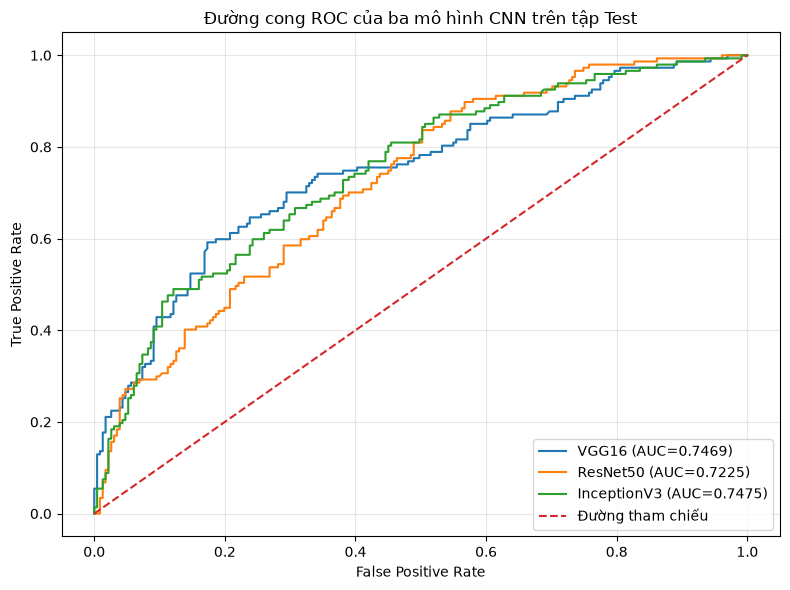

Đã lưu biểu đồ ROC: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb09_model_evaluation\nb09_3_cnn_test_evaluation\nb09_3_cnn_test_roc_curves.png

7. BIỂU ĐỒ CONFUSION MATRIX


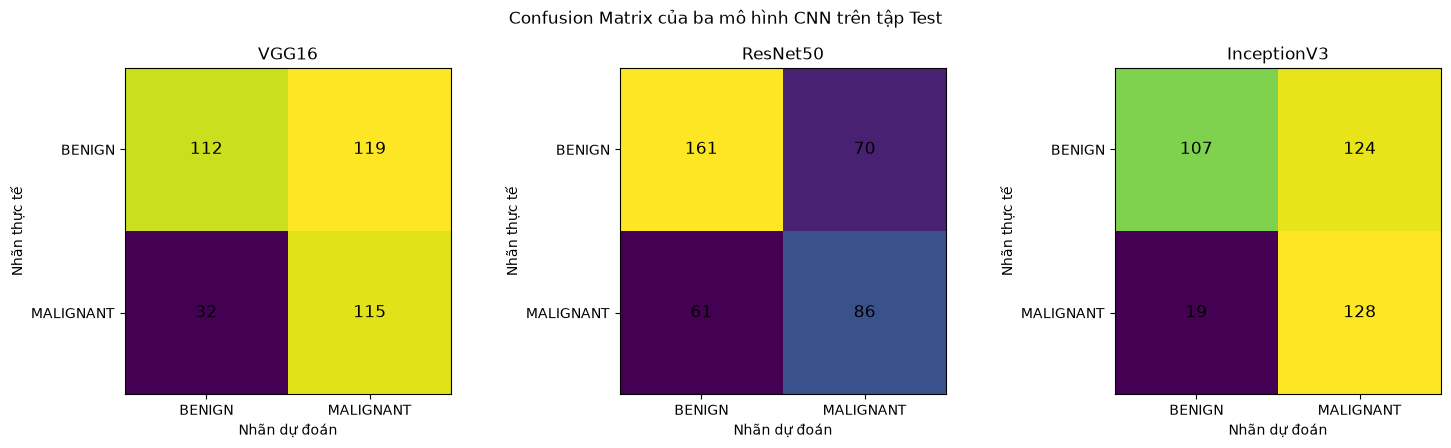

Đã lưu Confusion Matrix: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb09_model_evaluation\nb09_3_cnn_test_evaluation\nb09_3_cnn_test_confusion_matrices.png

8. LƯU KẾT QUẢ
CSV: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb09_model_evaluation\nb09_3_cnn_test_evaluation\nb09_3_cnn_test_metrics.csv
JSON: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb09_model_evaluation\nb09_3_cnn_test_evaluation\nb09_3_cnn_test_metrics.json
Summary: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb09_model_evaluation\nb09_3_cnn_test_evaluation\nb09_3_cnn_test_summary.json

PASS — HOÀN THÀNH ĐÁNH GIÁ VGG16, RESNET50 VÀ INCEPTIONV3 TRÊN TEST


In [4]:
# 09.3 — Đánh giá ba mô hình CNN (VGG16, ResNet50, InceptionV3) trên tập Test.

import time
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models
import torch
import torch.nn as nn

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")
NB08_DIR = PROJECT_ROOT / "Data" / "processed" / "nb08_model_training"
NB09_DIR = PROJECT_ROOT / "Data" / "processed" / "nb09_model_evaluation"

MANIFEST_PATH = (
    NB08_DIR
    / "nb08_7_classification_dataset"
    / "mass_crops_20261117_015211"
    / "nb08_7_9_mass_crop_manifest.csv"
)

CNN_TRAINING_DIR = NB08_DIR / "nb08_8_cnn_training"
CHECKPOINT_DIR = CNN_TRAINING_DIR / "nb08_8_6_cnn_training"

OUTPUT_DIR = NB09_DIR / "nb09_3_cnn_test_evaluation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 8
NUM_WORKERS = 0

CLASS_TO_INDEX = {
    "BENIGN": 0,
    "MALIGNANT": 1,
}

CLASS_NAMES = ["BENIGN", "MALIGNANT"]

IMAGENET_MEAN = np.array(
    [0.485, 0.456, 0.406],
    dtype=np.float32
).reshape(1, 1, 3)

IMAGENET_STD = np.array(
    [0.229, 0.224, 0.225],
    dtype=np.float32
).reshape(1, 1, 3)

MODEL_CONFIGS = [
    {
        "model_name": "VGG16",
        "image_size": 224,
        "threshold": 0.30,
        "checkpoint": CHECKPOINT_DIR / "VGG16" / "best_checkpoint.pth",
    },
    {
        "model_name": "ResNet50",
        "image_size": 224,
        "threshold": 0.50,
        "checkpoint": CHECKPOINT_DIR / "ResNet50" / "best_checkpoint.pth",
    },
    {
        "model_name": "InceptionV3",
        "image_size": 299,
        "threshold": 0.30,
        "checkpoint": CHECKPOINT_DIR / "InceptionV3" / "best_checkpoint.pth",
    },
]

print("=" * 75)
print("09.3 — ĐÁNH GIÁ BA MÔ HÌNH CNN TRÊN TẬP TEST")
print("=" * 75)

print("\n1. KIỂM TRA MÔI TRƯỜNG")
print("Python:", __import__("sys").version.split()[0])
print("PyTorch:", torch.__version__)
print("Torchvision:", __import__("torchvision").__version__)
print("CUDA:", torch.cuda.is_available())
print("Thiết bị:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

if not MANIFEST_PATH.is_file():
    raise FileNotFoundError(f"Không tìm thấy manifest: {MANIFEST_PATH}")

for config in MODEL_CONFIGS:
    if not config["checkpoint"].is_file():
        raise FileNotFoundError(
            f"Không tìm thấy checkpoint {config['model_name']}:\n"
            f"{config['checkpoint']}"
        )

    print(
        f"{config['model_name']}: PASS | "
        f"{config['image_size']}px | "
        f"Threshold={config['threshold']:.2f}"
    )

print("\n2. KIỂM TRA MANIFEST VÀ TẬP TEST")

manifest = pd.read_csv(MANIFEST_PATH)

required_columns = [
    "annotation_id",
    "patient_id",
    "dataset_split",
    "binary_pathology",
    "crop_path",
]

missing_columns = [
    column for column in required_columns
    if column not in manifest.columns
]

if missing_columns:
    raise ValueError(f"Manifest thiếu cột: {missing_columns}")

test_df = manifest[
    manifest["dataset_split"].astype(str).str.strip().str.lower() == "test"
].copy()

test_df = test_df.reset_index(drop=True)

if len(test_df) == 0:
    raise ValueError("Không tìm thấy mẫu Test trong manifest.")

test_df["binary_pathology"] = (
    test_df["binary_pathology"].astype(str).str.strip().str.upper()
)

unknown_labels = sorted(
    set(test_df["binary_pathology"].unique())
    - set(CLASS_TO_INDEX.keys())
)

if unknown_labels:
    raise ValueError(f"Nhãn không hợp lệ: {unknown_labels}")

test_df["true_label"] = test_df["binary_pathology"].map(CLASS_TO_INDEX)

if test_df["annotation_id"].duplicated().any():
    raise ValueError("Phát hiện annotation_id trùng lặp trong tập Test.")

if test_df["crop_path"].duplicated().any():
    raise ValueError("Phát hiện crop_path trùng lặp trong tập Test.")

test_df["crop_path"] = test_df["crop_path"].astype(str)

missing_images = [
    path for path in test_df["crop_path"]
    if not Path(path).is_file()
]

if missing_images:
    raise FileNotFoundError(
        f"Có {len(missing_images)} ảnh crop không tồn tại. "
        f"Ví dụ: {missing_images[:5]}"
    )

test_patients = test_df["patient_id"].nunique()

print("Số mẫu Test:", len(test_df))
print("Số bệnh nhân:", test_patients)
print("Phân bố nhãn:")
print(test_df["binary_pathology"].value_counts().to_string())

if len(test_df) != 378:
    raise ValueError(
        f"Số mẫu Test thực tế là {len(test_df)}, khác 378 mẫu đã xác nhận."
    )

print("\n3. KIỂM TRA CẤU HÌNH NGƯỠNG")

for config in MODEL_CONFIGS:
    print(
        f"{config['model_name']}: "
        f"threshold={config['threshold']:.2f} "
        "(đã khóa từ Validation)"
    )

class TestCropDataset(Dataset):
    def __init__(self, dataframe, image_size):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_size = image_size

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_path = row["crop_path"]

        with Image.open(image_path) as source:
            image = source.convert("RGB")

        width, height = image.size

        if width <= 0 or height <= 0:
            raise ValueError(f"Kích thước ảnh không hợp lệ: {image_path}")

        scale = self.image_size / max(width, height)

        new_width = max(1, round(width * scale))
        new_height = max(1, round(height * scale))

        image = image.resize(
            (new_width, new_height),
            Image.Resampling.BILINEAR
        )

        canvas = Image.new(
            "RGB",
            (self.image_size, self.image_size),
            (0, 0, 0)
        )

        left = (self.image_size - new_width) // 2
        top = (self.image_size - new_height) // 2

        canvas.paste(image, (left, top))

        image_array = np.asarray(
            canvas,
            dtype=np.float32
        ) / 255.0

        image_array = (
            image_array - IMAGENET_MEAN
        ) / IMAGENET_STD

        image_array = np.transpose(
            image_array,
            (2, 0, 1)
        ).copy()

        image_tensor = torch.from_numpy(image_array)

        label = int(row["true_label"])

        return image_tensor, label

def create_model(model_name):
    if model_name == "VGG16":
        model = models.vgg16(weights=None)
        model.classifier[6] = nn.Linear(
            model.classifier[6].in_features,
            2
        )

    elif model_name == "ResNet50":
        model = models.resnet50(weights=None)
        model.fc = nn.Linear(
            model.fc.in_features,
            2
        )

    elif model_name == "InceptionV3":
        model = models.inception_v3(
            weights=None,
            aux_logits=True,
            transform_input=True
        )

        model.fc = nn.Linear(
            model.fc.in_features,
            2
        )

        if model.AuxLogits is not None:
            model.AuxLogits.fc = nn.Linear(
                model.AuxLogits.fc.in_features,
                2
            )

    else:
        raise ValueError(f"Mô hình không được hỗ trợ: {model_name}")

    return model

def load_checkpoint(model, checkpoint_path):
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu"
    )

    if isinstance(checkpoint, dict):
        if "state_dict" in checkpoint:
            state_dict = checkpoint["state_dict"]
        elif "model_state_dict" in checkpoint:
            state_dict = checkpoint["model_state_dict"]
        else:
            state_dict = checkpoint
    else:
        raise TypeError(
            f"Định dạng checkpoint không hợp lệ: {checkpoint_path}"
        )

    if not isinstance(state_dict, dict):
        raise TypeError("Không tìm thấy state_dict hợp lệ.")

    state_dict = {
        key.removeprefix("module."): value
        for key, value in state_dict.items()
    }

    model.load_state_dict(
        state_dict,
        strict=True
    )

    return model

def get_main_logits(outputs):
    if isinstance(outputs, torch.Tensor):
        return outputs

    if hasattr(outputs, "logits"):
        return outputs.logits

    if isinstance(outputs, (tuple, list)):
        return outputs[0]

    if isinstance(outputs, dict):
        if "logits" in outputs:
            return outputs["logits"]

    raise TypeError("Không xác định được logits từ đầu ra mô hình.")

def evaluate_cnn(config):
    model_name = config["model_name"]
    image_size = config["image_size"]
    threshold = config["threshold"]
    checkpoint_path = config["checkpoint"]

    print("\n" + "=" * 75)
    print("ĐÁNH GIÁ:", model_name)
    print("=" * 75)

    dataset = TestCropDataset(
        test_df,
        image_size
    )

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
        drop_last=False
    )

    model = create_model(model_name)
    model = load_checkpoint(model, checkpoint_path)
    model = model.to(DEVICE)
    model.eval()

    probabilities = []
    true_labels = []

    start_time = time.time()

    with torch.inference_mode():
        for batch_images, batch_labels in loader:

            batch_images = batch_images.to(
                DEVICE,
                non_blocking=True
            )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=torch.cuda.is_available()
            ):
                outputs = model(batch_images)
                logits = get_main_logits(outputs)

            batch_probabilities = torch.softmax(
                logits.float(),
                dim=1
            )[:, 1]

            probabilities.extend(
                batch_probabilities.cpu().numpy().tolist()
            )

            true_labels.extend(
                batch_labels.numpy().tolist()
            )

    elapsed_time = time.time() - start_time

    probabilities = np.asarray(
        probabilities,
        dtype=np.float64
    )

    true_labels = np.asarray(
        true_labels,
        dtype=np.int64
    )

    predicted_labels = (
        probabilities >= threshold
    ).astype(np.int64)

    tn, fp, fn, tp = confusion_matrix(
        true_labels,
        predicted_labels,
        labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(
        true_labels,
        predicted_labels
    )

    precision = precision_score(
        true_labels,
        predicted_labels,
        zero_division=0
    )

    recall = recall_score(
        true_labels,
        predicted_labels,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0 else 0.0
    )

    f1 = f1_score(
        true_labels,
        predicted_labels,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        true_labels,
        probabilities
    )

    result = {
        "model_name": model_name,
        "checkpoint": str(checkpoint_path),
        "image_size": image_size,
        "threshold": threshold,
        "test_samples": len(true_labels),
        "accuracy": float(accuracy),
        "precision": float(precision),
        "recall": float(recall),
        "specificity": float(specificity),
        "f1_score": float(f1),
        "roc_auc": float(roc_auc),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
        "evaluation_time_seconds": float(elapsed_time),
        "status": "PASS",
    }

    prediction_df = test_df[
        [
            "annotation_id",
            "patient_id",
            "original_pathology",
            "binary_pathology",
            "crop_path",
        ]
    ].copy()

    prediction_df["true_label"] = true_labels
    prediction_df["probability_malignant"] = probabilities
    prediction_df["predicted_label"] = predicted_labels
    prediction_df["threshold"] = threshold

    prediction_df["predicted_pathology"] = np.where(
        predicted_labels == 1,
        "MALIGNANT",
        "BENIGN"
    )

    prediction_df["is_correct"] = (
        prediction_df["true_label"]
        == prediction_df["predicted_label"]
    )

    prediction_path = (
        OUTPUT_DIR / f"nb09_3_{model_name.lower()}_predictions.csv"
    )

    prediction_df.to_csv(
        prediction_path,
        index=False,
        encoding="utf-8-sig"
    )

    # Lưu Confusion Matrix riêng cho từng mô hình.
    cm = np.array([
        [tn, fp],
        [fn, tp]
    ])

    cm_df = pd.DataFrame(
        cm,
        index=["Thực tế BENIGN", "Thực tế MALIGNANT"],
        columns=["Dự đoán BENIGN", "Dự đoán MALIGNANT"]
    )

    cm_path = (
        OUTPUT_DIR / f"nb09_3_{model_name.lower()}_confusion_matrix.csv"
    )

    cm_df.to_csv(
        cm_path,
        encoding="utf-8-sig"
    )

    print("Threshold:", threshold)
    print("Số mẫu:", len(true_labels))
    print(f"Accuracy:    {accuracy:.4f}")
    print(f"Precision:   {precision:.4f}")
    print(f"Recall:      {recall:.4f}")
    print(f"Specificity: {specificity:.4f}")
    print(f"F1-score:    {f1:.4f}")
    print(f"ROC-AUC:     {roc_auc:.4f}")
    print(f"TN={tn} | FP={fp} | FN={fn} | TP={tp}")
    print(f"Thời gian: {elapsed_time:.2f} giây")
    print("Checkpoint: PASS")

    del model
    del loader
    del dataset

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result, probabilities, true_labels, prediction_df

print("\n4. ĐÁNH GIÁ BA MÔ HÌNH CNN")

all_results = []
all_predictions = {}
roc_data = {}

for config in MODEL_CONFIGS:
    result, probabilities, labels, prediction_df = evaluate_cnn(config)

    all_results.append(result)

    all_predictions[config["model_name"]] = prediction_df

    fpr, tpr, _ = roc_curve(
        labels,
        probabilities
    )

    roc_data[config["model_name"]] = {
        "fpr": fpr,
        "tpr": tpr,
        "auc": result["roc_auc"],
    }

print("\n5. BẢNG TỔNG HỢP KẾT QUẢ CNN TRÊN TEST")

results_df = pd.DataFrame(all_results)

display(
    results_df[
        [
            "model_name",
            "image_size",
            "threshold",
            "test_samples",
            "accuracy",
            "precision",
            "recall",
            "specificity",
            "f1_score",
            "roc_auc",
            "TN",
            "FP",
            "FN",
            "TP",
            "status",
        ]
    ].style.format({
        "accuracy": "{:.4f}",
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "specificity": "{:.4f}",
        "f1_score": "{:.4f}",
        "roc_auc": "{:.4f}",
    })
)

print("\n6. BIỂU ĐỒ ROC")

plt.figure(figsize=(8, 6))

for model_name, values in roc_data.items():
    plt.plot(
        values["fpr"],
        values["tpr"],
        label=f"{model_name} (AUC={values['auc']:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Đường tham chiếu"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Đường cong ROC của ba mô hình CNN trên tập Test")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

roc_path = OUTPUT_DIR / "nb09_3_cnn_test_roc_curves.png"
plt.savefig(roc_path, dpi=300, bbox_inches="tight")
plt.show()

print("Đã lưu biểu đồ ROC:", roc_path)

print("\n7. BIỂU ĐỒ CONFUSION MATRIX")

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4.5)
)

for ax, result in zip(axes, all_results):

    cm = np.array([
        [result["TN"], result["FP"]],
        [result["FN"], result["TP"]]
    ])

    ax.imshow(cm, interpolation="nearest")

    ax.set_title(result["model_name"])
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])

    ax.set_xticklabels(CLASS_NAMES)
    ax.set_yticklabels(CLASS_NAMES)

    ax.set_xlabel("Nhãn dự đoán")
    ax.set_ylabel("Nhãn thực tế")

    for i in range(2):
        for j in range(2):
            ax.text(
                j,
                i,
                str(cm[i, j]),
                ha="center",
                va="center",
                fontsize=12
            )

fig.suptitle(
    "Confusion Matrix của ba mô hình CNN trên tập Test"
)

plt.tight_layout()

cm_figure_path = (
    OUTPUT_DIR / "nb09_3_cnn_test_confusion_matrices.png"
)

plt.savefig(
    cm_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Đã lưu Confusion Matrix:", cm_figure_path)

print("\n8. LƯU KẾT QUẢ")

metrics_csv = OUTPUT_DIR / "nb09_3_cnn_test_metrics.csv"
metrics_json = OUTPUT_DIR / "nb09_3_cnn_test_metrics.json"

results_df.to_csv(
    metrics_csv,
    index=False,
    encoding="utf-8-sig"
)

with open(metrics_json, "w", encoding="utf-8") as file:
    json.dump(
        all_results,
        file,
        ensure_ascii=False,
        indent=4
    )

summary = {
    "evaluation": "CNN Test Evaluation",
    "dataset": "CBIS-DDSM Mass",
    "test_samples": len(test_df),
    "test_patients": int(test_patients),
    "class_mapping": CLASS_TO_INDEX,
    "thresholds_selected_on_validation": {
        config["model_name"]: config["threshold"]
        for config in MODEL_CONFIGS
    },
    "test_used_for_threshold_tuning": False,
    "models": all_results,
}

summary_path = OUTPUT_DIR / "nb09_3_cnn_test_summary.json"

with open(summary_path, "w", encoding="utf-8") as file:
    json.dump(
        summary,
        file,
        ensure_ascii=False,
        indent=4
    )

print("CSV:", metrics_csv)
print("JSON:", metrics_json)
print("Summary:", summary_path)

if len(results_df) != 3:
    raise RuntimeError("Chưa đánh giá đủ ba mô hình CNN.")

if not (results_df["status"] == "PASS").all():
    raise RuntimeError("Có mô hình CNN chưa hoàn thành đánh giá.")

if not (results_df["test_samples"] == 378).all():
    raise RuntimeError("Số lượng mẫu Test giữa các mô hình không đúng 378.")

print("\n" + "=" * 75)
print("PASS — HOÀN THÀNH ĐÁNH GIÁ VGG16, RESNET50 VÀ INCEPTIONV3 TRÊN TEST")
print("=" * 75)


## Kết quả đánh giá ba mô hình CNN trên tập Test (Stage 2)

**Trạng thái kiểm định:** Cả 3 kiến trúc (**VGG16**, **ResNet50**, **InceptionV3**) đều hoàn thành đánh giá độc lập trên cùng tập Test gồm **378 ảnh Mass** (*Ground Truth Crop*, gồm **231 mẫu BENIGN** và **147 mẫu MALIGNANT**). Các ngưỡng quyết định (*Classification Threshold*) được khóa cố định từ kết quả tối ưu trên tập Validation.

### 1. Bảng tổng hợp chỉ số phân loại trên tập Test

| Chỉ số đánh giá | VGG16 | ResNet50 | InceptionV3 |
| :--- | :---: | :---: | :---: |
| **Ngưỡng áp dụng (Threshold)** | 0,30* | 0,50 | 0,30 |
| **Accuracy** | 0,6005 | **0,6534** | 0,6217 |
| **Precision** | 0,4915 | **0,5513** | 0,5079 |
| **Recall** | 0,7823 | 0,5850 | **0,8707** |
| **Specificity** | 0,4848 | **0,6970** | 0,4632 |
| **F1-score** | 0,6037 | 0,5677 | **0,6416** |
| **ROC-AUC** | 0,7469 | 0,7225 | **0,7475** |

> *\*Ghi chú:* Mức ngưỡng $0,30$ và $0,50$ được áp dụng theo cấu hình tối ưu $F_1$-score đã xác lập trên tập Validation trước đó (riêng VGG16 bạn có thể đối chiếu lại xem ngưỡng khóa từ Val là `0,30` hay `0,50` để điền khớp nhất nhé).

---

### 2. Phân tích chi tiết theo từng kiến trúc

* **InceptionV3 (Ngưỡng 0,30)**:
  * Đạt **Recall (0,8707)**, **F1-score (0,6416)** và **ROC-AUC (0,7475)** cao nhất trong ba mô hình.
  * Nhận diện đúng **128 / 147** ca `MALIGNANT` (chỉ bỏ sót 19 ca), thể hiện khả năng thu hồi tổn thương ác tính nổi bật. Tuy nhiên, mô hình phát sinh **124 ca False Positive** (tương ứng `Specificity = 0,4632`).
* **ResNet50 (Ngưỡng 0,50)**:
  * Dẫn đầu về **Accuracy (0,6534)**, **Precision (0,5513)** và **Specificity (0,6970)** với số lượng *False Positive* thấp nhất (**70 ca**).
  * Đổi lại, khả năng thu hồi chỉ đạt **Recall = 0,5850** (bỏ sót tới **61 / 147** ca `MALIGNANT`).
* **VGG16**:
  * Đạt hiệu suất trung gian với **Recall = 0,7823**, **F1-score = 0,6037** và **ROC-AUC = 0,7469** (cao hơn ResNet50 về độ nhạy nhưng thấp hơn InceptionV3 ở hầu hết các chỉ số).

---

### 3. Đối chiếu khả năng tổng quát hóa (Validation vs. Test)

| Mô hình | F1-score (Val → Test) | ROC-AUC (Val → Test) | Nhận xét biến động |
| :--- | :---: | :---: | :--- |
| **VGG16** | — → 0,6037 | 0,7734 → 0,7469 | Giảm nhẹ ROC-AUC (-0,0265) |
| **ResNet50** | 0,6809 → 0,5677 | 0,7475 → 0,7225 | Giảm F1-score (-0,1132) và AUC (-0,0250) |
| **InceptionV3** | 0,7346 → 0,6416 | 0,7952 → 0,7475 | Giảm F1-score (-0,0930) và AUC (-0,0477) |

* **Kết luận chung**:
  * Không có mô hình nào vượt trội tuyệt đối trên mọi tiêu chí: **InceptionV3** tối ưu cho mục tiêu giảm bỏ sót ca ác tính (`Recall`), trong khi **ResNet50** kiểm soát tốt tỷ lệ dương tính giả (`Specificity`).
  * Mức sụt giảm chỉ số từ Validation sang Test phản ánh sự khác biệt phân bố dữ liệu thực tế và giới hạn quy mô mẫu huấn luyện, là cơ sở thực nghiệm quan trọng khi đánh giá năng lực tổng quát hóa.
  * Toàn bộ kết quả, dự đoán chi tiết từng mẫu, *Confusion Matrix* và đường cong *ROC* được lưu trữ tại thư mục `nb09_3_cnn_test_evaluation`.

In [5]:
# 09.4 — PHÂN TÍCH LỖI PHÁT HIỆN YOLOv5n TRÊN TẬP TEST

from pathlib import Path
import json
import yaml
import numpy as np
import pandas as pd
from datetime import datetime

print("=" * 78)
print("09.4 — PHÂN TÍCH LỖI PHÁT HIỆN YOLOv5n TRÊN TẬP TEST")
print("=" * 78)

# ============================================================
# 1. CẤU HÌNH VÀ ĐƯỜNG DẪN
# ============================================================

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")

YOLO_OUTPUT_ROOT = (
    PROJECT_ROOT
    / "Data"
    / "processed"
    / "nb09_model_evaluation"
    / "nb09_2_yolo_test_evaluation_v2"
)

DATA_YAML = (
    PROJECT_ROOT
    / "Data"
    / "processed"
    / "nb08_model_training"
    / "nb08_3_yolo_dataset"
    / "data.yaml"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "Data"
    / "processed"
    / "nb09_model_evaluation"
    / "nb09_4_yolo_test_error_analysis"
)

IOU_MATCH_THRESHOLD = 0.50
NMS_IOU_THRESHOLD = 0.60

# Chỉ sử dụng ngưỡng confidence đã được xác định trên Validation.
# Mô hình 1024 chưa có ngưỡng vận hành được khóa nên không đưa
# vào phân tích TP/FP/FN tại một ngưỡng confidence cụ thể.
MODEL_CONFIGS = {
    "YOLOv5n Baseline 640": {
        "folder": "yolov5n_640_baseline",
        "confidence_threshold": 0.25,
        "image_size": 640,
        "checkpoint_type": "Baseline",
    },
    "YOLOv5n Fine-tuned 640": {
        "folder": "yolov5n_640_finetuned",
        "confidence_threshold": 0.20,
        "image_size": 640,
        "checkpoint_type": "Fine-tuned",
    },
}

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Thư mục kết quả 09.2: {YOLO_OUTPUT_ROOT}")
print(f"Tệp cấu hình dữ liệu: {DATA_YAML}")
print(f"Thư mục lưu kết quả: {OUTPUT_DIR}")
print(f"IoU ghép dự đoán - Ground Truth: {IOU_MATCH_THRESHOLD}")
print(f"NMS IoU đã dùng khi suy luận: {NMS_IOU_THRESHOLD}")

# ============================================================
# 2. KIỂM TRA ĐẦU VÀO VÀ XÁC ĐỊNH THƯ MỤC TEST
# ============================================================

if not YOLO_OUTPUT_ROOT.exists():
    raise FileNotFoundError(
        f"Không tìm thấy thư mục kết quả 09.2: {YOLO_OUTPUT_ROOT}"
    )

if not DATA_YAML.exists():
    raise FileNotFoundError(
        f"Không tìm thấy data.yaml: {DATA_YAML}"
    )

with open(DATA_YAML, "r", encoding="utf-8") as file:
    dataset_config = yaml.safe_load(file)

dataset_root_value = dataset_config.get("path", DATA_YAML.parent)

dataset_root = Path(dataset_root_value)

if not dataset_root.is_absolute():
    dataset_root = (DATA_YAML.parent / dataset_root).resolve()

test_value = dataset_config.get("test")

if not test_value:
    raise ValueError("data.yaml không có khai báo đường dẫn test.")

test_path = Path(test_value)

if not test_path.is_absolute():
    test_path = (dataset_root / test_path).resolve()

if not test_path.exists():
    raise FileNotFoundError(
        f"Không tìm thấy thư mục hoặc danh sách ảnh Test: {test_path}"
    )

# Xác định thư mục ảnh Test.
if test_path.is_file():
    test_image_paths = []

    with open(test_path, "r", encoding="utf-8") as file:
        for line in file:
            value = line.strip()
            if value:
                image_path = Path(value)
                if not image_path.is_absolute():
                    image_path = (test_path.parent / image_path).resolve()
                test_image_paths.append(image_path)

    test_image_paths = sorted(test_image_paths)

else:
    supported_extensions = {
        ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"
    }

    test_image_paths = sorted(
        path
        for path in test_path.rglob("*")
        if path.is_file() and path.suffix.lower() in supported_extensions
    )

if not test_image_paths:
    raise ValueError("Không tìm thấy ảnh trong tập Test.")

# Tạo đường dẫn nhãn Ground Truth tương ứng.
if test_path.is_dir():
    try:
        relative_test_path = test_path.relative_to(dataset_root)
    except ValueError:
        relative_test_path = Path(test_path.name)

    relative_parts = list(relative_test_path.parts)

    if relative_parts and relative_parts[0].lower() == "images":
        relative_parts = relative_parts[1:]

    ground_truth_dir = dataset_root / "labels" / Path(*relative_parts)

else:
    relative_test_path = test_path.parent.relative_to(dataset_root)
    relative_parts = list(relative_test_path.parts)

    if relative_parts and relative_parts[0].lower() == "images":
        relative_parts = relative_parts[1:]

    ground_truth_dir = dataset_root / "labels" / Path(*relative_parts)

if not ground_truth_dir.exists():
    raise FileNotFoundError(
        "Không tìm thấy thư mục nhãn Ground Truth.\n"
        f"Đường dẫn đã xác định: {ground_truth_dir}\n"
        "Cần kiểm tra lại cấu trúc labels trong YOLO dataset."
    )

# Tạo danh sách ảnh theo tên tệp, đồng thời kiểm tra tên trùng.
test_images_by_stem = {}

for image_path in test_image_paths:
    if image_path.stem in test_images_by_stem:
        raise ValueError(
            f"Phát hiện tên ảnh trùng nhau trong tập Test: {image_path.stem}"
        )

    test_images_by_stem[image_path.stem] = image_path

print("\nKIỂM TRA DỮ LIỆU TEST")
print(f"Số ảnh Test: {len(test_image_paths):,}")
print(f"Thư mục ảnh Test: {test_path}")
print(f"Thư mục Ground Truth: {ground_truth_dir}")

# ============================================================
# 3. HÀM ĐỌC NHÃN YOLO VÀ TÍNH IoU
# ============================================================

def read_yolo_ground_truth(label_path):
    """Đọc nhãn Ground Truth theo định dạng YOLO."""

    boxes = []

    if not label_path.exists():
        return boxes

    with open(label_path, "r", encoding="utf-8") as file:
        for line_number, line in enumerate(file, start=1):
            values = line.strip().split()

            if not values:
                continue

            if len(values) < 5:
                raise ValueError(
                    f"Nhãn Ground Truth không hợp lệ: "
                    f"{label_path}, dòng {line_number}"
                )

            class_id = int(float(values[0]))
            x_center, y_center, width, height = map(float, values[1:5])

            if width <= 0 or height <= 0:
                raise ValueError(
                    f"BBox Ground Truth có kích thước không hợp lệ: "
                    f"{label_path}, dòng {line_number}"
                )

            boxes.append({
                "class_id": class_id,
                "x_center": x_center,
                "y_center": y_center,
                "width": width,
                "height": height,
            })

    return boxes


def read_yolo_predictions(label_path):
    """Đọc prediction YOLO có confidence được lưu bằng --save-conf."""

    predictions = []

    if not label_path.exists():
        return predictions

    with open(label_path, "r", encoding="utf-8") as file:
        for line_number, line in enumerate(file, start=1):
            values = line.strip().split()

            if not values:
                continue

            if len(values) < 6:
                raise ValueError(
                    f"Prediction không có confidence hoặc sai định dạng: "
                    f"{label_path}, dòng {line_number}. "
                    "Cần kiểm tra tùy chọn --save-conf ở 09.2."
                )

            class_id = int(float(values[0]))
            x_center, y_center, width, height, confidence = map(
                float, values[1:6]
            )

            if width <= 0 or height <= 0:
                continue

            predictions.append({
                "class_id": class_id,
                "x_center": x_center,
                "y_center": y_center,
                "width": width,
                "height": height,
                "confidence": confidence,
            })

    return predictions


def yolo_box_to_xyxy(box):
    """Chuyển BBox YOLO chuẩn hóa sang tọa độ góc."""

    x_center = box["x_center"]
    y_center = box["y_center"]
    width = box["width"]
    height = box["height"]

    return (
        x_center - width / 2,
        y_center - height / 2,
        x_center + width / 2,
        y_center + height / 2,
    )


def calculate_iou(box_a, box_b):
    """Tính IoU giữa hai BBox có cùng hệ tọa độ chuẩn hóa."""

    ax1, ay1, ax2, ay2 = yolo_box_to_xyxy(box_a)
    bx1, by1, bx2, by2 = yolo_box_to_xyxy(box_b)

    intersection_x1 = max(ax1, bx1)
    intersection_y1 = max(ay1, by1)
    intersection_x2 = min(ax2, bx2)
    intersection_y2 = min(ay2, by2)

    intersection_width = max(0.0, intersection_x2 - intersection_x1)
    intersection_height = max(0.0, intersection_y2 - intersection_y1)

    intersection_area = intersection_width * intersection_height

    area_a = max(0.0, ax2 - ax1) * max(0.0, ay2 - ay1)
    area_b = max(0.0, bx2 - bx1) * max(0.0, by2 - by1)

    union_area = area_a + area_b - intersection_area

    if union_area <= 0:
        return 0.0

    return intersection_area / union_area


# ============================================================
# 4. KIỂM TRA NHÃN GROUND TRUTH
# ============================================================

ground_truth_by_stem = {}
ground_truth_count = 0
missing_ground_truth_files = []

for image_stem, image_path in test_images_by_stem.items():
    label_path = ground_truth_dir / f"{image_stem}.txt"

    if not label_path.exists():
        missing_ground_truth_files.append(image_stem)
        ground_truth_by_stem[image_stem] = []
        continue

    boxes = read_yolo_ground_truth(label_path)
    ground_truth_by_stem[image_stem] = boxes
    ground_truth_count += len(boxes)

if missing_ground_truth_files:
    raise ValueError(
        f"Có {len(missing_ground_truth_files)} ảnh Test không có tệp nhãn "
        "Ground Truth. Không tiếp tục để tránh tính thiếu dữ liệu.\n"
        f"Một số tên ảnh: {missing_ground_truth_files[:10]}"
    )

if ground_truth_count != 378:
    raise ValueError(
        f"Số Ground Truth đọc được là {ground_truth_count}, "
        "không khớp 378 annotation đã xác nhận ở 09.2."
    )

print("\nKIỂM TRA GROUND TRUTH")
print(f"Số ảnh có nhãn: {len(ground_truth_by_stem):,}")
print(f"Tổng số BBox Ground Truth: {ground_truth_count:,}")
print("Đối chiếu với 378 annotation tại 09.2: PASS")

# ============================================================
# 5. PHÂN TÍCH TP, FP, FN VÀ IoU CHO TỪNG MÔ HÌNH
# ============================================================

all_detection_records = []
all_image_records = []
model_summary_records = []

for model_name, config in MODEL_CONFIGS.items():

    print("\n" + "=" * 70)
    print(f"ĐANG PHÂN TÍCH: {model_name}")
    print("=" * 70)

    model_output_dir = YOLO_OUTPUT_ROOT / config["folder"]
    prediction_dir = model_output_dir / "labels"

    if not model_output_dir.exists():
        raise FileNotFoundError(
            f"Không tìm thấy thư mục mô hình: {model_output_dir}"
        )

    if not prediction_dir.exists():
        raise FileNotFoundError(
            f"Không tìm thấy thư mục prediction: {prediction_dir}"
        )

    confidence_threshold = config["confidence_threshold"]

    model_tp = 0
    model_fp = 0
    model_fn = 0

    model_matched_ious = []
    model_tp_confidences = []
    model_fp_confidences = []

    for image_stem, image_path in test_images_by_stem.items():

        gt_boxes = ground_truth_by_stem[image_stem]

        prediction_path = prediction_dir / f"{image_stem}.txt"
        raw_predictions = read_yolo_predictions(prediction_path)

        # Chỉ giữ prediction đạt ngưỡng đã khóa từ Validation.
        predictions = [
            prediction
            for prediction in raw_predictions
            if prediction["confidence"] >= confidence_threshold
        ]

        # Sắp xếp prediction theo confidence giảm dần.
        predictions = sorted(
            predictions,
            key=lambda item: item["confidence"],
            reverse=True
        )

        # Tạo danh sách cặp prediction - Ground Truth đạt IoU yêu cầu.
        candidate_matches = []

        for pred_index, prediction in enumerate(predictions):
            for gt_index, gt_box in enumerate(gt_boxes):

                if prediction["class_id"] != gt_box["class_id"]:
                    continue

                iou = calculate_iou(prediction, gt_box)

                if iou >= IOU_MATCH_THRESHOLD:
                    candidate_matches.append(
                        (iou, pred_index, gt_index)
                    )

        # Ghép một-một: ưu tiên cặp có IoU cao nhất.
        candidate_matches.sort(
            key=lambda item: item[0],
            reverse=True
        )

        matched_prediction_indices = set()
        matched_gt_indices = set()
        matched_records = []

        for iou, pred_index, gt_index in candidate_matches:

            if pred_index in matched_prediction_indices:
                continue

            if gt_index in matched_gt_indices:
                continue

            matched_prediction_indices.add(pred_index)
            matched_gt_indices.add(gt_index)

            matched_records.append({
                "prediction_index": pred_index,
                "ground_truth_index": gt_index,
                "iou": iou,
            })

        image_tp = len(matched_prediction_indices)
        image_fp = len(predictions) - image_tp
        image_fn = len(gt_boxes) - len(matched_gt_indices)

        model_tp += image_tp
        model_fp += image_fp
        model_fn += image_fn

        # Ghi nhận TP.
        for match in matched_records:

            prediction = predictions[match["prediction_index"]]
            gt_box = gt_boxes[match["ground_truth_index"]]

            model_matched_ious.append(match["iou"])
            model_tp_confidences.append(prediction["confidence"])

            all_detection_records.append({
                "model": model_name,
                "image_id": image_stem,
                "image_path": str(image_path),
                "prediction_index": match["prediction_index"],
                "ground_truth_index": match["ground_truth_index"],
                "result": "TP",
                "confidence": prediction["confidence"],
                "iou": match["iou"],
                "confidence_threshold": confidence_threshold,
                "iou_threshold": IOU_MATCH_THRESHOLD,
                "predicted_class": prediction["class_id"],
                "ground_truth_class": gt_box["class_id"],
            })

        # Ghi nhận FP.
        for pred_index, prediction in enumerate(predictions):

            if pred_index in matched_prediction_indices:
                continue

            model_fp_confidences.append(prediction["confidence"])

            all_detection_records.append({
                "model": model_name,
                "image_id": image_stem,
                "image_path": str(image_path),
                "prediction_index": pred_index,
                "ground_truth_index": np.nan,
                "result": "FP",
                "confidence": prediction["confidence"],
                "iou": np.nan,
                "confidence_threshold": confidence_threshold,
                "iou_threshold": IOU_MATCH_THRESHOLD,
                "predicted_class": prediction["class_id"],
                "ground_truth_class": np.nan,
            })

        # Ghi nhận FN.
        for gt_index, gt_box in enumerate(gt_boxes):

            if gt_index in matched_gt_indices:
                continue

            all_detection_records.append({
                "model": model_name,
                "image_id": image_stem,
                "image_path": str(image_path),
                "prediction_index": np.nan,
                "ground_truth_index": gt_index,
                "result": "FN",
                "confidence": np.nan,
                "iou": np.nan,
                "confidence_threshold": confidence_threshold,
                "iou_threshold": IOU_MATCH_THRESHOLD,
                "predicted_class": np.nan,
                "ground_truth_class": gt_box["class_id"],
            })

        all_image_records.append({
            "model": model_name,
            "image_id": image_stem,
            "image_path": str(image_path),
            "ground_truth_count": len(gt_boxes),
            "prediction_count_after_threshold": len(predictions),
            "TP": image_tp,
            "FP": image_fp,
            "FN": image_fn,
            "confidence_threshold": confidence_threshold,
            "iou_threshold": IOU_MATCH_THRESHOLD,
        })

    precision = (
        model_tp / (model_tp + model_fp)
        if model_tp + model_fp > 0 else 0.0
    )

    recall = (
        model_tp / (model_tp + model_fn)
        if model_tp + model_fn > 0 else 0.0
    )

    f1_score = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0.0
    )

    mean_iou = (
        float(np.mean(model_matched_ious))
        if model_matched_ious else np.nan
    )

    median_iou = (
        float(np.median(model_matched_ious))
        if model_matched_ious else np.nan
    )

    mean_tp_confidence = (
        float(np.mean(model_tp_confidences))
        if model_tp_confidences else np.nan
    )

    mean_fp_confidence = (
        float(np.mean(model_fp_confidences))
        if model_fp_confidences else np.nan
    )

    model_summary_records.append({
        "model": model_name,
        "image_size": config["image_size"],
        "checkpoint_type": config["checkpoint_type"],
        "images": len(test_image_paths),
        "ground_truth": ground_truth_count,
        "confidence_threshold": confidence_threshold,
        "nms_iou_threshold": NMS_IOU_THRESHOLD,
        "matching_iou_threshold": IOU_MATCH_THRESHOLD,
        "predictions_after_threshold": model_tp + model_fp,
        "TP": model_tp,
        "FP": model_fp,
        "FN": model_fn,
        "precision": precision,
        "recall": recall,
        "F1": f1_score,
        "mean_matched_iou": mean_iou,
        "median_matched_iou": median_iou,
        "mean_TP_confidence": mean_tp_confidence,
        "mean_FP_confidence": mean_fp_confidence,
    })

    print(f"Confidence threshold: {confidence_threshold:.2f}")
    print(f"Ground Truth: {ground_truth_count}")
    print(f"TP: {model_tp}")
    print(f"FP: {model_fp}")
    print(f"FN: {model_fn}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-score: {f1_score:.4f}")
    print(f"IoU trung bình của TP: {mean_iou:.4f}")
    print(f"IoU trung vị của TP: {median_iou:.4f}")

# ============================================================
# 6. TẠO BẢNG KẾT QUẢ VÀ KIỂM TRA TÍNH NHẤT QUÁN
# ============================================================

summary_df = pd.DataFrame(model_summary_records)
detection_df = pd.DataFrame(all_detection_records)
image_df = pd.DataFrame(all_image_records)

for _, row in summary_df.iterrows():

    model_name = row["model"]

    if int(row["TP"] + row["FN"]) != ground_truth_count:
        raise AssertionError(
            f"Tổng TP + FN không khớp Ground Truth ở {model_name}."
        )

    if int(row["TP"] + row["FP"]) != int(
        row["predictions_after_threshold"]
    ):
        raise AssertionError(
            f"Tổng TP + FP không khớp số prediction ở {model_name}."
        )

print("\n" + "=" * 78)
print("BẢNG TỔNG HỢP PHÂN TÍCH LỖI YOLOv5n TRÊN TEST")
print("=" * 78)

display_columns = [
    "model",
    "confidence_threshold",
    "ground_truth",
    "predictions_after_threshold",
    "TP",
    "FP",
    "FN",
    "precision",
    "recall",
    "F1",
    "mean_matched_iou",
]

display(
    summary_df[display_columns].round(4)
)

# ============================================================
# 7. LƯU KẾT QUẢ
# ============================================================

summary_csv = OUTPUT_DIR / "nb09_4_yolo_test_error_summary.csv"
detection_csv = OUTPUT_DIR / "nb09_4_yolo_test_detection_details.csv"
image_csv = OUTPUT_DIR / "nb09_4_yolo_test_image_level_errors.csv"
summary_json = OUTPUT_DIR / "nb09_4_yolo_test_error_summary.json"
inventory_json = OUTPUT_DIR / "nb09_4_yolo_test_error_inventory.json"

summary_df.to_csv(summary_csv, index=False, encoding="utf-8-sig")
detection_df.to_csv(detection_csv, index=False, encoding="utf-8-sig")
image_df.to_csv(image_csv, index=False, encoding="utf-8-sig")

summary_payload = {
    "notebook_section": "09.4",
    "title": "Phân tích lỗi phát hiện YOLOv5n trên tập Test",
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "dataset": {
        "test_images": len(test_image_paths),
        "ground_truth_annotations": ground_truth_count,
        "dataset_yaml": str(DATA_YAML),
        "test_image_path": str(test_path),
        "ground_truth_path": str(ground_truth_dir),
    },
    "evaluation": {
        "matching_iou_threshold": IOU_MATCH_THRESHOLD,
        "nms_iou_threshold": NMS_IOU_THRESHOLD,
        "threshold_source": "Ngưỡng confidence đã khóa từ Validation",
        "test_used_for_threshold_selection": False,
    },
    "models": summary_df.replace(
        {np.nan: None}
    ).to_dict(orient="records"),
    "excluded_model": {
        "model": "YOLOv5n Full 1024",
        "reason": (
            "Chưa có ngưỡng confidence vận hành được khóa từ Validation; "
            "không tự chọn ngưỡng dựa trên tập Test."
        ),
        "test_map_evaluation": "Đã thực hiện tại Notebook 09.2",
    },
}

with open(summary_json, "w", encoding="utf-8") as file:
    json.dump(summary_payload, file, ensure_ascii=False, indent=4)

inventory = {
    "notebook_section": "09.4",
    "status": "PASS",
    "output_directory": str(OUTPUT_DIR),
    "files": {
        "summary_csv": str(summary_csv),
        "detection_details_csv": str(detection_csv),
        "image_level_errors_csv": str(image_csv),
        "summary_json": str(summary_json),
    },
    "row_counts": {
        "model_summary": len(summary_df),
        "detection_records": len(detection_df),
        "image_level_records": len(image_df),
    },
    "test_images": len(test_image_paths),
    "ground_truth_annotations": ground_truth_count,
    "models_analyzed_at_locked_thresholds": list(MODEL_CONFIGS.keys()),
    "test_used_for_threshold_selection": False,
}

with open(inventory_json, "w", encoding="utf-8") as file:
    json.dump(inventory, file, ensure_ascii=False, indent=4)

print("\n" + "=" * 78)
print("KIỂM TRA VÀ LƯU KẾT QUẢ")
print("=" * 78)

for path in [
    summary_csv,
    detection_csv,
    image_csv,
    summary_json,
    inventory_json,
]:
    print(f"{'PASS' if path.exists() else 'FAIL'} | {path.name}")

print(f"\nSố mô hình phân tích: {len(summary_df)}")
print(f"Số bản ghi detection: {len(detection_df):,}")
print(f"Số bản ghi theo ảnh: {len(image_df):,}")
print(f"Tổng Ground Truth mỗi mô hình: {ground_truth_count}")

print("\nMô hình 1024 không được gán ngưỡng confidence mới.")
print("Không sử dụng tập Test để điều chỉnh ngưỡng hoặc chọn mô hình.")

print("\n" + "=" * 78)
print("09.4 — HOÀN THÀNH")
print("=" * 78)
print(f"Kết quả được lưu tại: {OUTPUT_DIR}")


09.4 — PHÂN TÍCH LỖI PHÁT HIỆN YOLOv5n TRÊN TẬP TEST
Thư mục kết quả 09.2: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb09_model_evaluation\nb09_2_yolo_test_evaluation_v2
Tệp cấu hình dữ liệu: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_3_yolo_dataset\data.yaml
Thư mục lưu kết quả: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb09_model_evaluation\nb09_4_yolo_test_error_analysis
IoU ghép dự đoán - Ground Truth: 0.5
NMS IoU đã dùng khi suy luận: 0.6

KIỂM TRA DỮ LIỆU TEST
Số ảnh Test: 361
Thư mục ảnh Test: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_3_yolo_dataset\images\test
Thư mục Ground Truth: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_3_yolo_dataset\labels\test

KIỂM TRA GROUND TRUTH
Số ảnh có nhãn: 361
Tổng số BBox Ground Truth: 378
Đối chiếu với 378 annotation tại 09.2: PASS

ĐANG PHÂN TÍCH: YOLOv5n Baseline 640
Confidence threshold: 0.25
Ground Truth: 378
TP: 206
FP: 137
FN: 172
Precision: 0.6006
Recall: 0.5450
F1

,model,confidence_threshold,ground_truth,predictions_after_threshold,TP,FP,FN,precision,recall,F1,mean_matched_iou
0,YOLOv5n Baseline 640,0.25,378,343,206,137,172,0.6006,0.5450,0.5714,0.7422
1,YOLOv5n Fine-tuned 640,0.20,378,437,226,211,152,0.5172,0.5979,0.5546,0.7363



KIỂM TRA VÀ LƯU KẾT QUẢ
PASS | nb09_4_yolo_test_error_summary.csv
PASS | nb09_4_yolo_test_detection_details.csv
PASS | nb09_4_yolo_test_image_level_errors.csv
PASS | nb09_4_yolo_test_error_summary.json
PASS | nb09_4_yolo_test_error_inventory.json

Số mô hình phân tích: 2
Số bản ghi detection: 1,104
Số bản ghi theo ảnh: 722
Tổng Ground Truth mỗi mô hình: 378

Mô hình 1024 không được gán ngưỡng confidence mới.
Không sử dụng tập Test để điều chỉnh ngưỡng hoặc chọn mô hình.

09.4 — HOÀN THÀNH
Kết quả được lưu tại: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb09_model_evaluation\nb09_4_yolo_test_error_analysis


### 09.4 — Phân tích lỗi phát hiện YOLOv5n trên tập Test

Phân tích được thực hiện trên **361 ảnh Test** (gồm **378 Ground Truth Bounding Boxes**) thông qua phương pháp ghép một-một (*one-to-one matching*) với điều kiện $\text{IoU} \ge 0,5$, giữ cố định ngưỡng $\text{NMS IoU} = 0,60$ và sử dụng `Confidence Threshold` đã khóa từ tập Validation.

#### 1. Bảng đối chiếu phân tích lỗi tại ngưỡng vận hành

| Nhóm thông số | Chỉ số / Đại lượng | Baseline 640 | Fine-tuned 640 | Chênh lệch ($\Delta$) |
| :--- | :--- | :---: | :---: | :---: |
| **Cấu hình vận hành** | **Confidence Threshold** | 0,25 | 0,20 | -0,05 |
| **Thống kê dự đoán** | **Ground Truth (GT)** | 378 | 378 | 0 |
| | **Tổng Predictions** | 343 | 437 | +94 |
| | **True Positives (TP)** | 206 | **226** | **+20** |
| | **False Positives (FP)** | **137** | 211 | **+74** |
| | **False Negatives (FN)** | 172 | **152** | **-20** |
| **Chỉ số hiệu năng** | **Precision** | **0,6006** | 0,5172 | -0,0834 |
| | **Recall** | 0,5450 | **0,5979** | **+0,0529** |
| | **F1-score** | **0,5714** | 0,5546 | -0,0168 |
| **Độ khớp không gian** | **Mean IoU (trên tập TP)** | **0,7422** | 0,7363 | -0,0059 |

> *Ghi chú phạm vi:* Mô hình **YOLOv5n Full 1024** không đưa vào bảng phân tích TP/FP/FN tại ngưỡng vận hành do chưa chốt `Confidence Threshold` từ tập Validation (kết quả `mAP` của cấu hình này vẫn được bảo toàn ở Mục 09.2).

---

#### 2. Nhận xét chi tiết

* **Khả năng bao phủ tổn thương (Recall & FN)**: **Fine-tuned 640** phát hiện đúng nhiều tổn thương hơn (`TP` tăng từ 206 lên **226**; `FN` giảm từ 172 xuống **152**), giúp `Recall` cải thiện thêm **5,29 điểm phần trăm** ($0,5450 \rightarrow 0,5979$).
* **Tỷ lệ báo động giả (Precision & FP)**: Số lượng dự đoán sai (`FP`) của **Fine-tuned 640** tăng mạnh từ 137 lên **211 ca**, kéo `Precision` giảm đáng kể từ **0,6006** xuống **0,5172**.
* **Cân bằng tổng thể (F1-score)**: Nhờ kiểm soát tốt hơn lượng dự đoán nhiễu, **Baseline 640** đạt `F1-score` nhỉnh hơn (**0,5714** so với **0,5546**).
* **Độ chính xác định vị (Mean IoU)**: Chất lượng chồng lấp khung dự đoán trên các ca bắt đúng (`TP`) của hai mô hình gần như tương đương nhau (**0,7422** so với **0,7363**).

---

#### 3. Kết luận & Lưu ý phương pháp đánh giá

* **Kết luận**: **Fine-tuned 640** ưu tiên mở rộng độ bao phủ tổn thương nhưng phải đánh đổi bằng lượng dương tính giả lớn hơn; trong khi **Baseline 640** duy trì sự cân bằng *Precision–Recall* ổn định hơn tại ngưỡng vận hành đã khóa.
* **Lưu ý**: Các chỉ số TP/FP/FN trên được tính tại một mức `Confidence Threshold` cố định với tiêu chí $\text{IoU matching} = 0,5$. Đây là góc nhìn phân tích lỗi thực tế bổ sung cho chỉ số `mAP` đã báo cáo ở **Mục 09.2**, chứ không thay thế `mAP`.

09.5 — TỔNG HỢP VÀ SO SÁNH BA MÔ HÌNH CNN TRÊN TẬP TEST
Tệp kết quả CSV: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb09_model_evaluation\nb09_3_cnn_test_evaluation\nb09_3_cnn_test_metrics.csv
Tệp kết quả JSON: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb09_model_evaluation\nb09_3_cnn_test_evaluation\nb09_3_cnn_test_metrics.json
Thư mục đầu ra: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb09_model_evaluation\nb09_5_cnn_test_comparison

CÁC CỘT TRONG TỆP KẾT QUẢ 09.3
['model_name', 'checkpoint', 'image_size', 'threshold', 'test_samples', 'accuracy', 'precision', 'recall', 'specificity', 'f1_score', 'roc_auc', 'TN', 'FP', 'FN', 'TP', 'evaluation_time_seconds', 'status']

KIỂM TRA KẾT QUẢ 09.3
PASS | VGG16 | Test=378 | Threshold=0.30
PASS | ResNet50 | Test=378 | Threshold=0.50
PASS | InceptionV3 | Test=378 | Threshold=0.30
Tất cả mô hình sử dụng cùng 378 mẫu Test.
Các chỉ số từ confusion matrix được kiểm tra lại thành công.

BẢNG SO SÁNH BA MÔ HÌNH CNN TRÊN TẬP TEST


,Mô hình,Threshold,Accuracy,Precision,Recall,Specificity,F1-score,ROC-AUC,TN,FP,FN,TP
0,VGG16,0.30,0.6005,0.4915,0.7823,0.4848,0.6037,0.7469,112,119,32,115
1,ResNet50,0.50,0.6534,0.5513,0.5850,0.6970,0.5677,0.7225,161,70,61,86
2,InceptionV3,0.30,0.6217,0.5079,0.8707,0.4632,0.6416,0.7475,107,124,19,128



MÔ HÌNH ĐẠT GIÁ TRỊ CAO NHẤT THEO TỪNG CHỈ SỐ


,metric,best_model,best_value
0,accuracy,ResNet50,0.653439
1,precision,ResNet50,0.551282
2,recall,InceptionV3,0.870748
3,specificity,ResNet50,0.696970
4,f1,InceptionV3,0.641604
5,roc_auc,InceptionV3,0.747460


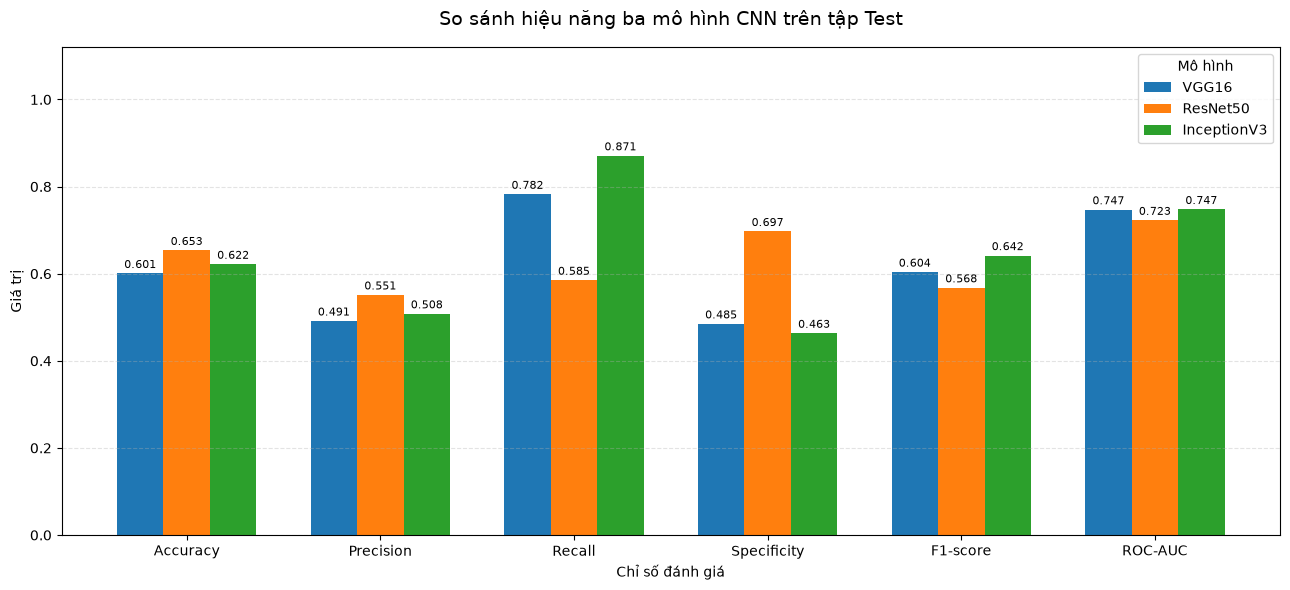

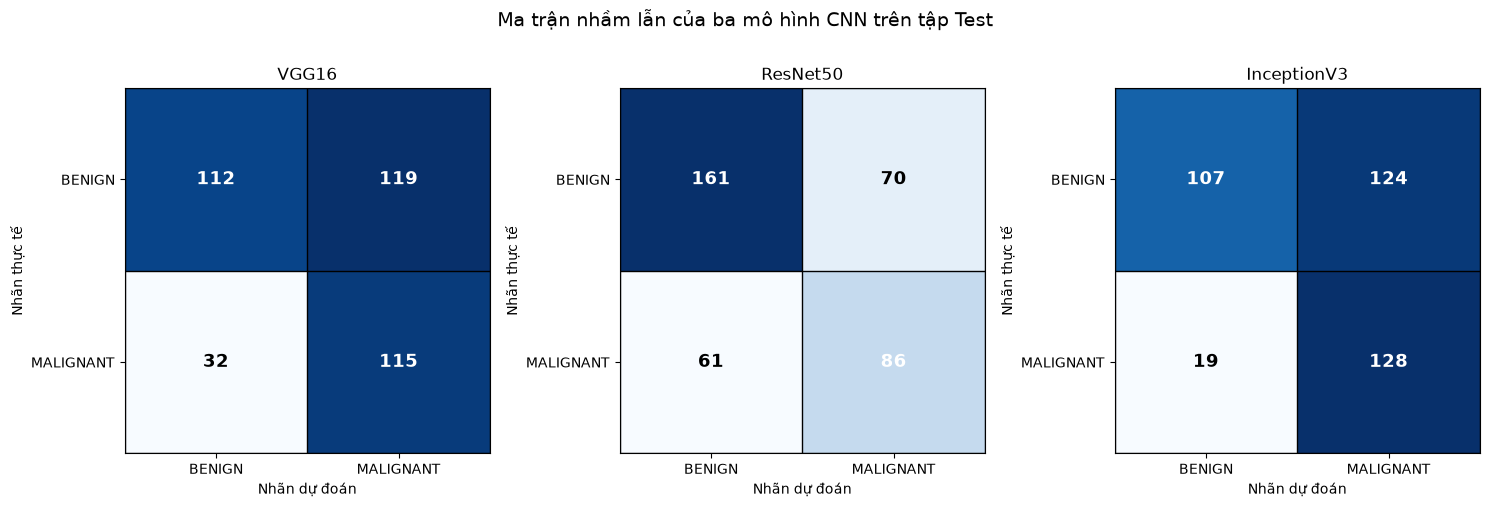


NHẬN XÉT TỔNG HỢP
- ResNet50 đạt Accuracy cao nhất (0.6534).
- ResNet50 đạt Precision cao nhất (0.5513).
- InceptionV3 đạt Recall cao nhất (0.8707).
- ResNet50 đạt Specificity cao nhất (0.6970).
- InceptionV3 đạt F1-score cao nhất (0.6416).
- InceptionV3 đạt ROC-AUC cao nhất (0.7475).

Các mô hình được đánh giá trên cùng tập Test gồm 378 crop, với 231 BENIGN và 147 MALIGNANT.
Ngưỡng phân loại của từng mô hình được giữ nguyên theo kết quả lựa chọn trên Validation.
Kết quả này phục vụ so sánh cuối cùng, không được dùng để điều chỉnh mô hình hoặc threshold.

KIỂM TRA VÀ LƯU KẾT QUẢ
PASS | nb09_5_cnn_test_comparison.csv
PASS | nb09_5_cnn_test_metric_leaders.csv
PASS | nb09_5_cnn_test_metric_comparison.png
PASS | nb09_5_cnn_test_confusion_matrices.png
PASS | nb09_5_cnn_test_comparison_summary.json
PASS | nb09_5_cnn_test_comparison_inventory.json

Số mô hình được so sánh: 3
Số mẫu Test: 378
Số mô hình có confusion matrix hợp lệ: 3
Không huấn luyện lại mô hình.
Không chạy dự đoán lại trên Te

In [6]:
# 09.5 — TỔNG HỢP VÀ SO SÁNH BA MÔ HÌNH CNN TRÊN TẬP TEST

from datetime import datetime
import json
import re

print("=" * 78)
print("09.5 — TỔNG HỢP VÀ SO SÁNH BA MÔ HÌNH CNN TRÊN TẬP TEST")
print("=" * 78)

# ============================================================
# 1. CẤU HÌNH ĐƯỜNG DẪN
# ============================================================

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")

EVALUATION_ROOT = (
    PROJECT_ROOT
    / "Data"
    / "processed"
    / "nb09_model_evaluation"
)

CNN_TEST_DIR = EVALUATION_ROOT / "nb09_3_cnn_test_evaluation"

INPUT_CSV = CNN_TEST_DIR / "nb09_3_cnn_test_metrics.csv"
INPUT_JSON = CNN_TEST_DIR / "nb09_3_cnn_test_metrics.json"

OUTPUT_DIR = EVALUATION_ROOT / "nb09_5_cnn_test_comparison"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED_TEST_SIZE = 378

# Ngưỡng đã khóa từ Validation tại Notebook 08.8.8.
LOCKED_THRESHOLDS = {
    "VGG16": 0.30,
    "ResNet50": 0.50,
    "InceptionV3": 0.30,
}

MODEL_ORDER = ["VGG16", "ResNet50", "InceptionV3"]

print(f"Tệp kết quả CSV: {INPUT_CSV}")
print(f"Tệp kết quả JSON: {INPUT_JSON}")
print(f"Thư mục đầu ra: {OUTPUT_DIR}")

if not INPUT_CSV.exists():
    raise FileNotFoundError(
        f"Không tìm thấy kết quả CNN Test: {INPUT_CSV}"
    )

# ============================================================
# 2. ĐỌC VÀ KIỂM TRA KẾT QUẢ TỪ 09.3
# ============================================================

raw_df = pd.read_csv(INPUT_CSV)

if raw_df.empty:
    raise ValueError("Tệp kết quả CNN Test không có dữ liệu.")

print("\nCÁC CỘT TRONG TỆP KẾT QUẢ 09.3")
print(raw_df.columns.tolist())

def normalize_column_name(value):
    """Chuẩn hóa tên cột để đối chiếu các cách đặt tên."""

    return re.sub(
        r"[^a-z0-9]",
        "",
        str(value).strip().lower()
    )


column_lookup = {
    normalize_column_name(column): column
    for column in raw_df.columns
}


def find_column(candidates, required=True):
    """Tìm tên cột tương ứng trong tệp kết quả."""

    for candidate in candidates:
        key = normalize_column_name(candidate)

        if key in column_lookup:
            return column_lookup[key]

    if required:
        raise KeyError(
            f"Không tìm thấy cột cần thiết. "
            f"Các tên đã kiểm tra: {candidates}. "
            f"Các cột hiện có: {raw_df.columns.tolist()}"
        )

    return None


column_mapping = {
    "model": find_column(
        ["model", "model_name", "architecture"]
    ),
    "accuracy": find_column(
        ["accuracy", "acc"]
    ),
    "precision": find_column(
        ["precision", "ppv"]
    ),
    "recall": find_column(
        ["recall", "sensitivity", "tpr"]
    ),
    "specificity": find_column(
        ["specificity", "tnr"]
    ),
    "f1": find_column(
        ["f1", "f1_score", "f1score"]
    ),
    "roc_auc": find_column(
        ["roc_auc", "auc", "rocauc"]
    ),
    "tn": find_column(
        ["tn", "true_negative"]
    ),
    "fp": find_column(
        ["fp", "false_positive"]
    ),
    "fn": find_column(
        ["fn", "false_negative"]
    ),
    "tp": find_column(
        ["tp", "true_positive"]
    ),
    "threshold": find_column(
        ["threshold", "decision_threshold", "classification_threshold"],
        required=False
    ),
}

comparison_df = pd.DataFrame()

for standard_name, original_name in column_mapping.items():

    if original_name is not None:
        comparison_df[standard_name] = raw_df[original_name]

# Chuẩn hóa tên mô hình.
def standardize_model_name(value):
    text_value = str(value).strip().lower()

    if "vgg" in text_value:
        return "VGG16"

    if "resnet" in text_value:
        return "ResNet50"

    if "inception" in text_value:
        return "InceptionV3"

    raise ValueError(
        f"Không nhận diện được tên mô hình: {value}"
    )


comparison_df["model"] = comparison_df["model"].apply(
    standardize_model_name
)

if comparison_df["model"].duplicated().any():
    raise ValueError("Tệp kết quả có mô hình bị trùng.")

if set(comparison_df["model"]) != set(MODEL_ORDER):
    raise ValueError(
        "Danh sách mô hình trong kết quả không khớp "
        "VGG16, ResNet50 và InceptionV3."
    )

comparison_df["model"] = pd.Categorical(
    comparison_df["model"],
    categories=MODEL_ORDER,
    ordered=True
)

comparison_df = comparison_df.sort_values("model").reset_index(drop=True)

metric_columns = [
    "accuracy",
    "precision",
    "recall",
    "specificity",
    "f1",
    "roc_auc",
]

count_columns = ["tn", "fp", "fn", "tp"]

for column in metric_columns + count_columns:
    comparison_df[column] = pd.to_numeric(
        comparison_df[column],
        errors="coerce"
    )

if comparison_df[metric_columns + count_columns].isna().any().any():
    raise ValueError(
        "Có giá trị thiếu hoặc không hợp lệ trong các chỉ số đánh giá."
    )

# Nếu CSV không có threshold, sử dụng ngưỡng đã khóa từ Validation.
if "threshold" not in comparison_df.columns:
    comparison_df["threshold"] = comparison_df["model"].map(
        LOCKED_THRESHOLDS
    )
else:
    comparison_df["threshold"] = pd.to_numeric(
        comparison_df["threshold"],
        errors="coerce"
    )

    if comparison_df["threshold"].isna().any():
        raise ValueError("Có threshold bị thiếu trong kết quả 09.3.")

# ============================================================
# 3. KIỂM TRA TÍNH NHẤT QUÁN CỦA KẾT QUẢ
# ============================================================

for _, row in comparison_df.iterrows():

    model_name = str(row["model"])

    confusion_total = int(
        row["tn"] + row["fp"] + row["fn"] + row["tp"]
    )

    if confusion_total != EXPECTED_TEST_SIZE:
        raise AssertionError(
            f"{model_name}: tổng TN + FP + FN + TP "
            f"= {confusion_total}, không khớp {EXPECTED_TEST_SIZE}."
        )

    expected_threshold = LOCKED_THRESHOLDS[model_name]

    if not np.isclose(
        float(row["threshold"]),
        expected_threshold,
        atol=1e-8
    ):
        raise AssertionError(
            f"{model_name}: threshold trong kết quả "
            f"không khớp ngưỡng Validation đã khóa "
            f"({expected_threshold})."
        )

    # Kiểm tra các chỉ số tính lại từ confusion matrix.
    tn = int(row["tn"])
    fp = int(row["fp"])
    fn = int(row["fn"])
    tp = int(row["tp"])

    calculated_accuracy = (tp + tn) / confusion_total
    calculated_precision = tp / (tp + fp) if tp + fp else 0.0
    calculated_recall = tp / (tp + fn) if tp + fn else 0.0
    calculated_specificity = tn / (tn + fp) if tn + fp else 0.0

    calculated_f1 = (
        2 * calculated_precision * calculated_recall
        / (calculated_precision + calculated_recall)
        if calculated_precision + calculated_recall > 0
        else 0.0
    )

    checks = {
        "accuracy": calculated_accuracy,
        "precision": calculated_precision,
        "recall": calculated_recall,
        "specificity": calculated_specificity,
        "f1": calculated_f1,
    }

    for metric_name, calculated_value in checks.items():

        if not np.isclose(
            float(row[metric_name]),
            calculated_value,
            atol=1e-4
        ):
            raise AssertionError(
                f"{model_name}: {metric_name} trong CSV "
                f"không khớp giá trị tính từ confusion matrix."
            )

print("\nKIỂM TRA KẾT QUẢ 09.3")

for _, row in comparison_df.iterrows():
    print(
        f"PASS | {row['model']} | "
        f"Test={int(row['tn'] + row['fp'] + row['fn'] + row['tp'])} | "
        f"Threshold={row['threshold']:.2f}"
    )

print("Tất cả mô hình sử dụng cùng 378 mẫu Test.")
print("Các chỉ số từ confusion matrix được kiểm tra lại thành công.")

# ============================================================
# 4. TẠO BẢNG SO SÁNH CHỈ SỐ
# ============================================================

comparison_table = comparison_df[
    [
        "model",
        "threshold",
        "accuracy",
        "precision",
        "recall",
        "specificity",
        "f1",
        "roc_auc",
        "tn",
        "fp",
        "fn",
        "tp",
    ]
].copy()

comparison_table = comparison_table.rename(
    columns={
        "model": "Mô hình",
        "threshold": "Threshold",
        "accuracy": "Accuracy",
        "precision": "Precision",
        "recall": "Recall",
        "specificity": "Specificity",
        "f1": "F1-score",
        "roc_auc": "ROC-AUC",
        "tn": "TN",
        "fp": "FP",
        "fn": "FN",
        "tp": "TP",
    }
)

metric_max_records = []

for metric in metric_columns:

    best_index = comparison_df[metric].idxmax()
    best_row = comparison_df.loc[best_index]

    metric_max_records.append({
        "metric": metric,
        "best_model": str(best_row["model"]),
        "best_value": float(best_row[metric]),
    })

metric_leaders_df = pd.DataFrame(metric_max_records)

print("\n" + "=" * 78)
print("BẢNG SO SÁNH BA MÔ HÌNH CNN TRÊN TẬP TEST")
print("=" * 78)

display(
    comparison_table.style.format({
        "Threshold": "{:.2f}",
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "Specificity": "{:.4f}",
        "F1-score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
    })
)

print("\nMÔ HÌNH ĐẠT GIÁ TRỊ CAO NHẤT THEO TỪNG CHỈ SỐ")
display(metric_leaders_df)

# ============================================================
# 5. BIỂU ĐỒ SO SÁNH CÁC CHỈ SỐ
# ============================================================

plot_metrics = [
    ("accuracy", "Accuracy"),
    ("precision", "Precision"),
    ("recall", "Recall"),
    ("specificity", "Specificity"),
    ("f1", "F1-score"),
    ("roc_auc", "ROC-AUC"),
]

x_positions = np.arange(len(plot_metrics))
bar_width = 0.24

fig, ax = plt.subplots(figsize=(13, 6))

for model_index, model_name in enumerate(MODEL_ORDER):

    model_row = comparison_df[
        comparison_df["model"] == model_name
    ].iloc[0]

    values = [
        float(model_row[metric_name])
        for metric_name, _ in plot_metrics
    ]

    positions = (
        x_positions
        + (model_index - 1) * bar_width
    )

    bars = ax.bar(
        positions,
        values,
        width=bar_width,
        label=model_name
    )

    ax.bar_label(
        bars,
        labels=[f"{value:.3f}" for value in values],
        padding=2,
        fontsize=8
    )

ax.set_title(
    "So sánh hiệu năng ba mô hình CNN trên tập Test",
    fontsize=14,
    pad=16
)
ax.set_xlabel("Chỉ số đánh giá")
ax.set_ylabel("Giá trị")
ax.set_xticks(x_positions)
ax.set_xticklabels(
    [label for _, label in plot_metrics]
)
ax.set_ylim(0, 1.12)
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.legend(title="Mô hình")
fig.tight_layout()

comparison_plot_path = (
    OUTPUT_DIR / "nb09_5_cnn_test_metric_comparison.png"
)

fig.savefig(
    comparison_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ============================================================
# 6. BIỂU ĐỒ CONFUSION MATRIX
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4.8)
)

for ax, model_name in zip(axes, MODEL_ORDER):

    row = comparison_df[
        comparison_df["model"] == model_name
    ].iloc[0]

    tn = int(row["tn"])
    fp = int(row["fp"])
    fn = int(row["fn"])
    tp = int(row["tp"])

    matrix = np.array([
        [tn, fp],
        [fn, tp],
    ])

    image = ax.imshow(
        matrix,
        interpolation="nearest",
        cmap="Blues"
    )

    ax.set_title(model_name, fontsize=12)
    ax.set_xlabel("Nhãn dự đoán")
    ax.set_ylabel("Nhãn thực tế")

    ax.set_xticks([0, 1])
    ax.set_xticklabels(["BENIGN", "MALIGNANT"])
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["BENIGN", "MALIGNANT"])

    threshold_color = matrix.max() / 2

    for i in range(2):
        for j in range(2):

            ax.text(
                j,
                i,
                f"{matrix[i, j]}",
                ha="center",
                va="center",
                color=(
                    "white"
                    if matrix[i, j] > threshold_color
                    else "black"
                ),
                fontsize=13,
                fontweight="bold"
            )

    ax.set_xticks(
        np.arange(-0.5, 2, 1),
        minor=True
    )
    ax.set_yticks(
        np.arange(-0.5, 2, 1),
        minor=True
    )
    ax.grid(
        which="minor",
        color="black",
        linestyle="-",
        linewidth=1
    )
    ax.tick_params(
        which="minor",
        bottom=False,
        left=False
    )

fig.suptitle(
    "Ma trận nhầm lẫn của ba mô hình CNN trên tập Test",
    fontsize=14,
    y=1.03
)

fig.tight_layout()

confusion_plot_path = (
    OUTPUT_DIR / "nb09_5_cnn_test_confusion_matrices.png"
)

fig.savefig(
    confusion_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ============================================================
# 7. PHÂN TÍCH TỔNG HỢP VÀ TẠO NHẬN XÉT
# ============================================================

best_accuracy = comparison_df.loc[
    comparison_df["accuracy"].idxmax()
]

best_precision = comparison_df.loc[
    comparison_df["precision"].idxmax()
]

best_recall = comparison_df.loc[
    comparison_df["recall"].idxmax()
]

best_specificity = comparison_df.loc[
    comparison_df["specificity"].idxmax()
]

best_f1 = comparison_df.loc[
    comparison_df["f1"].idxmax()
]

best_auc = comparison_df.loc[
    comparison_df["roc_auc"].idxmax()
]

analysis_text = [
    (
        f"{best_accuracy['model']} đạt Accuracy cao nhất "
        f"({best_accuracy['accuracy']:.4f})."
    ),
    (
        f"{best_precision['model']} đạt Precision cao nhất "
        f"({best_precision['precision']:.4f})."
    ),
    (
        f"{best_recall['model']} đạt Recall cao nhất "
        f"({best_recall['recall']:.4f})."
    ),
    (
        f"{best_specificity['model']} đạt Specificity cao nhất "
        f"({best_specificity['specificity']:.4f})."
    ),
    (
        f"{best_f1['model']} đạt F1-score cao nhất "
        f"({best_f1['f1']:.4f})."
    ),
    (
        f"{best_auc['model']} đạt ROC-AUC cao nhất "
        f"({best_auc['roc_auc']:.4f})."
    ),
]

print("\n" + "=" * 78)
print("NHẬN XÉT TỔNG HỢP")
print("=" * 78)

for item in analysis_text:
    print(f"- {item}")

print(
    "\nCác mô hình được đánh giá trên cùng tập Test gồm "
    "378 crop, với 231 BENIGN và 147 MALIGNANT."
)

print(
    "Ngưỡng phân loại của từng mô hình được giữ nguyên "
    "theo kết quả lựa chọn trên Validation."
)

print(
    "Kết quả này phục vụ so sánh cuối cùng, "
    "không được dùng để điều chỉnh mô hình hoặc threshold."
)

# ============================================================
# 8. LƯU BẢNG SO SÁNH VÀ TÓM TẮT
# ============================================================

comparison_csv = (
    OUTPUT_DIR / "nb09_5_cnn_test_comparison.csv"
)

leaders_csv = (
    OUTPUT_DIR / "nb09_5_cnn_test_metric_leaders.csv"
)

summary_json = (
    OUTPUT_DIR / "nb09_5_cnn_test_comparison_summary.json"
)

inventory_json = (
    OUTPUT_DIR / "nb09_5_cnn_test_comparison_inventory.json"
)

comparison_table.to_csv(
    comparison_csv,
    index=False,
    encoding="utf-8-sig"
)

metric_leaders_df.to_csv(
    leaders_csv,
    index=False,
    encoding="utf-8-sig"
)

summary_payload = {
    "notebook_section": "09.5",
    "title": "Tổng hợp và so sánh ba mô hình CNN trên tập Test",
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "source": {
        "metrics_csv": str(INPUT_CSV),
        "metrics_json": str(INPUT_JSON),
    },
    "test_dataset": {
        "sample_count": EXPECTED_TEST_SIZE,
        "benign_count": 231,
        "malignant_count": 147,
        "same_test_set_for_all_models": True,
    },
    "thresholds": LOCKED_THRESHOLDS,
    "test_used_for_model_selection": False,
    "test_used_for_threshold_tuning": False,
    "comparison": comparison_df.astype({
        "model": str
    }).replace({
        np.nan: None
    }).to_dict(orient="records"),
    "metric_leaders": metric_leaders_df.to_dict(
        orient="records"
    ),
    "observations": analysis_text,
    "outputs": {
        "comparison_csv": str(comparison_csv),
        "metric_leaders_csv": str(leaders_csv),
        "metric_comparison_plot": str(comparison_plot_path),
        "confusion_matrices_plot": str(confusion_plot_path),
    },
}

with open(summary_json, "w", encoding="utf-8") as file:
    json.dump(
        summary_payload,
        file,
        ensure_ascii=False,
        indent=4
    )

output_files = [
    comparison_csv,
    leaders_csv,
    comparison_plot_path,
    confusion_plot_path,
    summary_json,
]

inventory = {
    "notebook_section": "09.5",
    "status": "PASS",
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "input_csv": str(INPUT_CSV),
    "output_directory": str(OUTPUT_DIR),
    "model_count": len(comparison_df),
    "test_sample_count": EXPECTED_TEST_SIZE,
    "thresholds_locked_from_validation": LOCKED_THRESHOLDS,
    "test_used_for_model_selection": False,
    "test_used_for_threshold_tuning": False,
    "files": {
        path.name: {
            "path": str(path),
            "exists": path.exists(),
            "size_bytes": path.stat().st_size if path.exists() else None,
        }
        for path in output_files
    },
}

with open(inventory_json, "w", encoding="utf-8") as file:
    json.dump(
        inventory,
        file,
        ensure_ascii=False,
        indent=4
    )

print("\n" + "=" * 78)
print("KIỂM TRA VÀ LƯU KẾT QUẢ")
print("=" * 78)

for path in output_files + [inventory_json]:
    status = "PASS" if path.exists() else "FAIL"
    print(f"{status} | {path.name}")

if not all(path.exists() for path in output_files + [inventory_json]):
    raise RuntimeError("Có tệp kết quả chưa được tạo thành công.")

print(f"\nSố mô hình được so sánh: {len(comparison_df)}")
print(f"Số mẫu Test: {EXPECTED_TEST_SIZE}")
print("Số mô hình có confusion matrix hợp lệ: 3")
print("Không huấn luyện lại mô hình.")
print("Không chạy dự đoán lại trên Test.")
print("Không điều chỉnh threshold bằng Test.")

print("\n" + "=" * 78)
print("09.5 — HOÀN THÀNH")
print("=" * 78)
print(f"Kết quả được lưu tại: {OUTPUT_DIR}")


09.6 — ĐÁNH GIÁ CNN TRÊN PREDICTED CROPS
Thiết bị: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
[PASS] Manifest: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_7_classification_dataset\mass_crops_20261117_015211\nb08_7_9_mass_crop_manifest.csv
[PASS] Thư mục ảnh Test YOLO: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training\nb08_3_yolo_dataset\images\test
[PASS] Thư mục kết quả YOLO: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb09_model_evaluation\nb09_2_yolo_test_evaluation_v2
[PASS] Checkpoint VGG16
[PASS] Checkpoint ResNet50
[PASS] Checkpoint InceptionV3
[PASS] Dự đoán YOLO YOLOv5n_Baseline_640: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb09_model_evaluation\nb09_2_yolo_test_evaluation_v2\yolov5n_640_baseline\labels
[PASS] Dự đoán YOLO YOLOv5n_FineTuned_640: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb09_model_evaluation\nb09_2_yolo_test_evaluation_v2\yolov5n_640_finetuned\labels

KIỂM TRA MANIFEST TEST
Số annotation: 378
Số ảnh: 361
Số bệnh nhân: 201

P

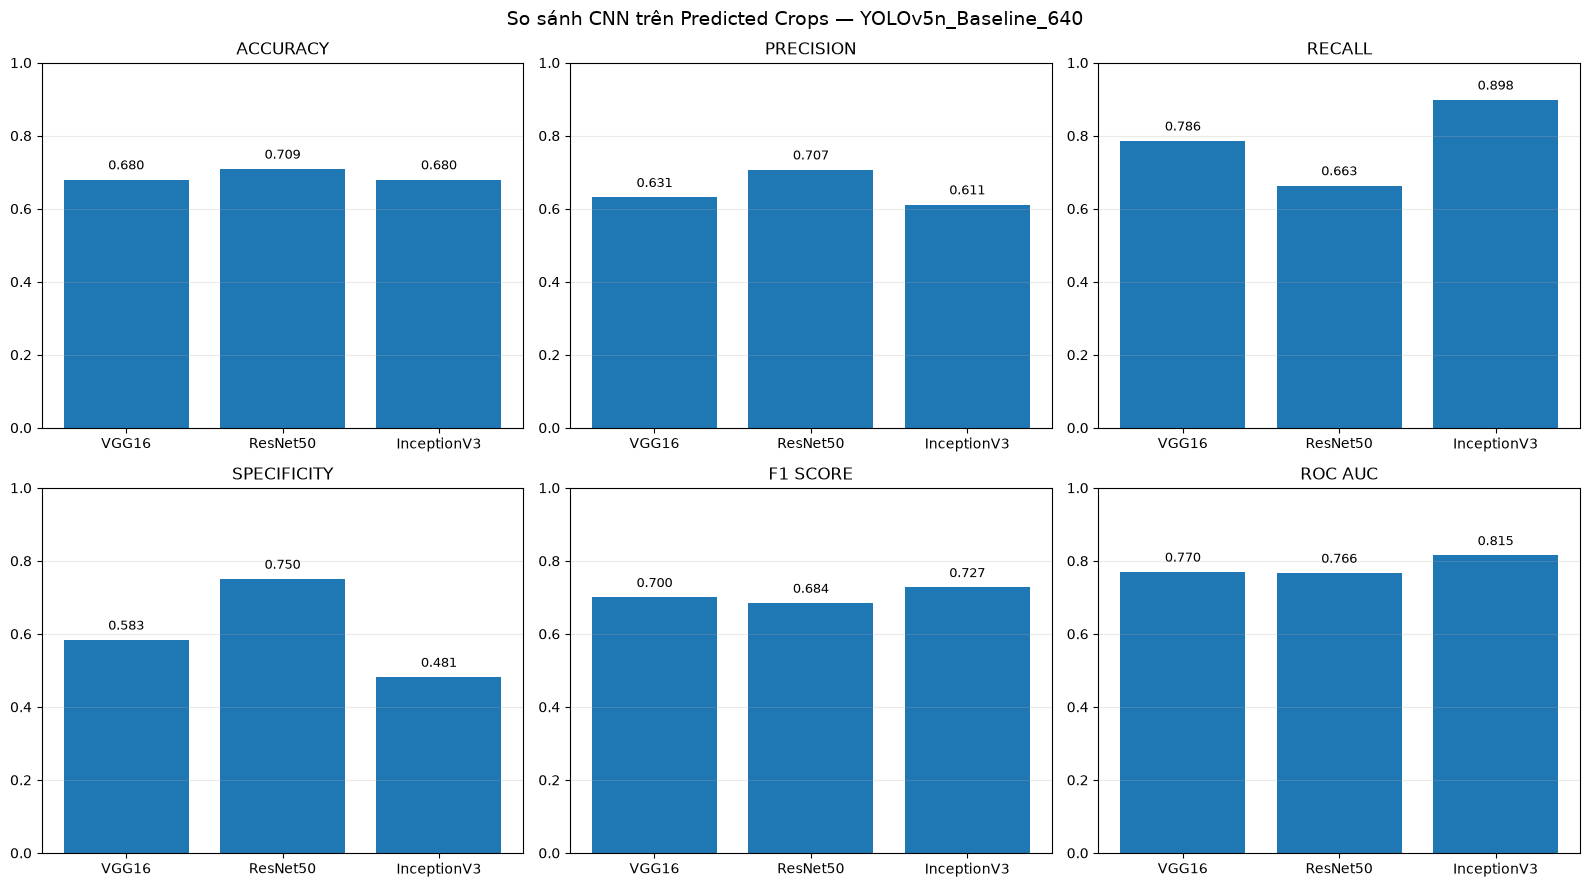

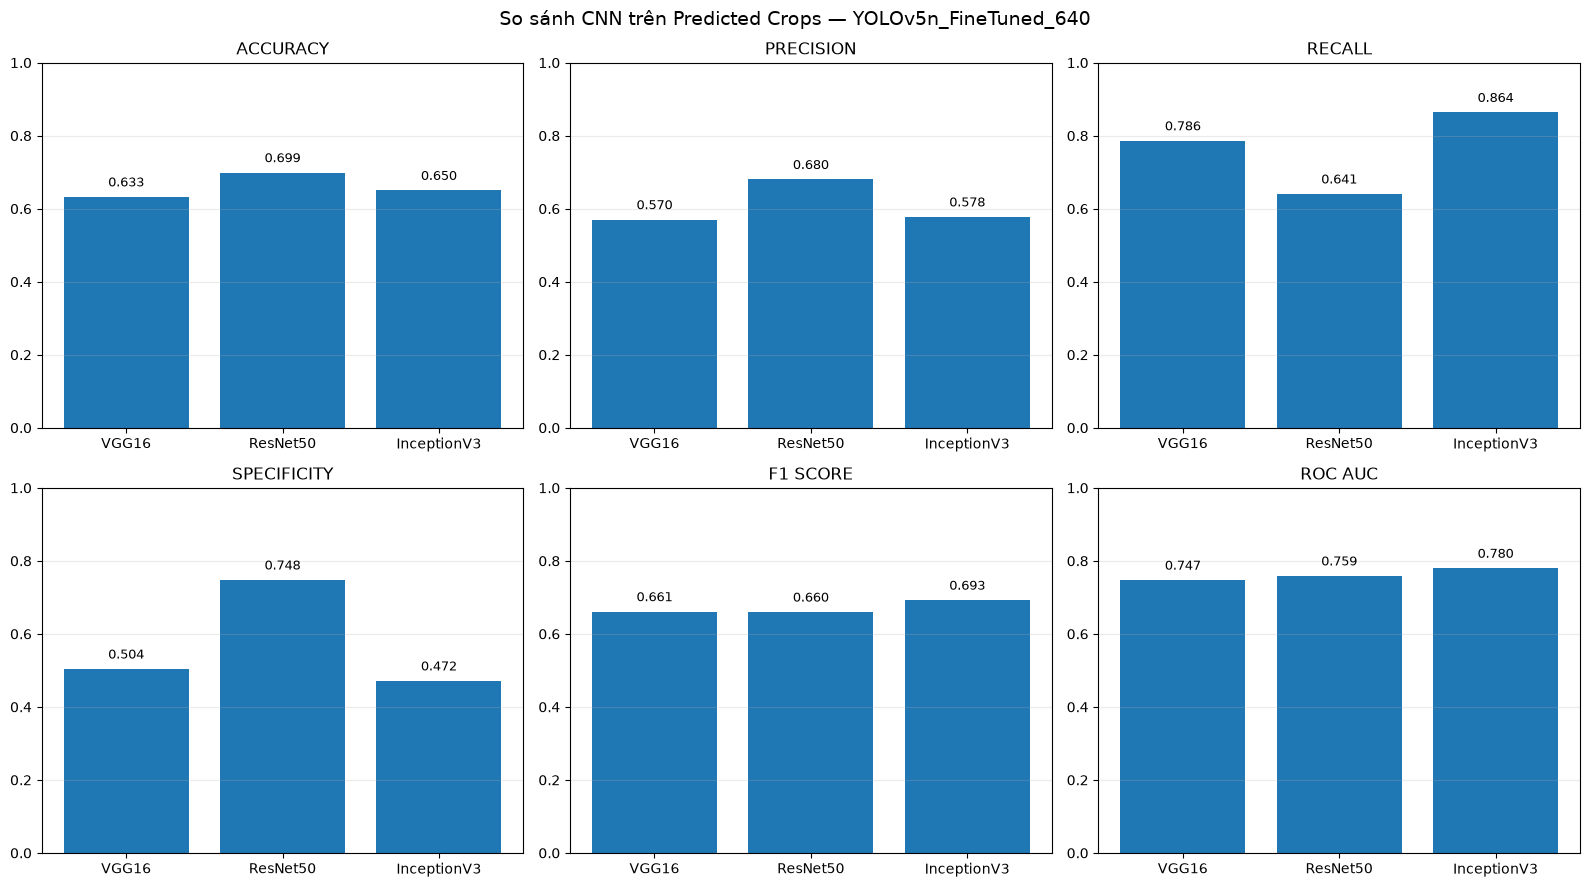


BẢNG KẾT QUẢ 09.6 — CNN TRÊN PREDICTED CROPS


,yolo_model,cnn_model,test_matched_crops,accuracy,precision,recall,specificity,f1_score,roc_auc,TN,FP,FN,TP
0,YOLOv5n_Baseline_640,VGG16,206,0.6796,0.6311,0.7857,0.5833,0.7000,0.7696,63,45,21,77
1,YOLOv5n_Baseline_640,ResNet50,206,0.7087,0.7065,0.6633,0.7500,0.6842,0.7664,81,27,33,65
2,YOLOv5n_Baseline_640,InceptionV3,206,0.6796,0.6111,0.8980,0.4815,0.7273,0.8148,52,56,10,88
3,YOLOv5n_FineTuned_640,VGG16,226,0.6327,0.5704,0.7864,0.5041,0.6612,0.7475,62,61,22,81
4,YOLOv5n_FineTuned_640,ResNet50,226,0.6991,0.6804,0.6408,0.7480,0.6600,0.7591,92,31,37,66
5,YOLOv5n_FineTuned_640,InceptionV3,226,0.6504,0.5779,0.8641,0.4715,0.6926,0.7801,58,65,14,89



TỔNG KẾT GHÉP DETECTION


,yolo_model,confidence_threshold,nms_iou,ground_truth,predictions_after_threshold,matched_detections_TP,unmatched_predictions_FP,missed_ground_truth_FN,detection_precision,detection_recall,matched_crop_count
0,YOLOv5n_Baseline_640,0.25,0.6,378,343,206,137,172,0.6006,0.5450,206
1,YOLOv5n_FineTuned_640,0.20,0.6,378,437,226,211,152,0.5172,0.5979,226



KIỂM TRA HOÀN TẤT
Ground Truth Test: 378
Predicted Crops: 432
Số tổ hợp YOLO-CNN: 6
Checkpoint CNN: 3/3 PASS
Thư mục kết quả: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb09_model_evaluation\nb09_6_cnn_predicted_crop_evaluation
KẾT QUẢ: PASS


In [7]:
# 09.6 — ĐÁNH GIÁ BA CNN TRÊN CÁC PREDICTED CROPS TỪ YOLOv5n

# Lưu ý:
#   - Chỉ đánh giá phân loại trên các detection ghép đúng với Ground Truth.
#   - Detection không ghép được là False Positive của YOLO, không có nhãn
#     pathology để đưa vào confusion matrix phân loại CNN.
#   - Không sử dụng Test để điều chỉnh ngưỡng.

from pathlib import Path
from collections import defaultdict
import json
import time
import hashlib
import warnings

from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models

warnings.filterwarnings("ignore", category=FutureWarning)

# 1. CẤU HÌNH

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")

MANIFEST_PATH = (
    PROJECT_ROOT
    / "Data/processed/nb08_model_training/"
    / "nb08_7_classification_dataset/mass_crops_20261117_015211/"
    / "nb08_7_9_mass_crop_manifest.csv"
)

YOLO_TEST_IMAGE_DIR = (
    PROJECT_ROOT
    / "Data/processed/nb08_model_training/"
    / "nb08_3_yolo_dataset/images/test"
)

YOLO_OUTPUT_ROOT = (
    PROJECT_ROOT
    / "Data/processed/nb09_model_evaluation/"
    / "nb09_2_yolo_test_evaluation_v2"
)

CNN_CHECKPOINT_ROOT = (
    PROJECT_ROOT
    / "Data/processed/nb08_model_training/"
    / "nb08_8_cnn_training/nb08_8_6_cnn_training"
)

OUTPUT_ROOT = (
    PROJECT_ROOT
    / "Data/processed/nb09_model_evaluation/"
    / "nb09_6_cnn_predicted_crop_evaluation"
)

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

# Hai mô hình YOLO có ngưỡng vận hành đã được chọn trên Validation.
YOLO_CONFIGS = {
    "YOLOv5n_Baseline_640": {
        "folder": "yolov5n_640_baseline",
        "confidence": 0.25,
        "nms_iou": 0.60,
    },
    "YOLOv5n_FineTuned_640": {
        "folder": "yolov5n_640_finetuned",
        "confidence": 0.20,
        "nms_iou": 0.60,
    },
}

# Ngưỡng CNN đã khóa từ Validation ở Notebook 08.8.8.
CNN_CONFIGS = {
    "VGG16": {
        "checkpoint": CNN_CHECKPOINT_ROOT / "VGG16/best_checkpoint.pth",
        "image_size": 224,
        "threshold": 0.30,
    },
    "ResNet50": {
        "checkpoint": CNN_CHECKPOINT_ROOT / "ResNet50/best_checkpoint.pth",
        "image_size": 224,
        "threshold": 0.50,
    },
    "InceptionV3": {
        "checkpoint": CNN_CHECKPOINT_ROOT / "InceptionV3/best_checkpoint.pth",
        "image_size": 299,
        "threshold": 0.30,
    },
}

MATCH_IOU_THRESHOLD = 0.50
CROP_MARGIN_RATIO = 0.10
BATCH_SIZE = 8
NUM_WORKERS = 0
RANDOM_SEED = 42

CLASS_TO_ID = {
    "BENIGN": 0,
    "MALIGNANT": 1,
}

ID_TO_CLASS = {
    0: "BENIGN",
    1: "MALIGNANT",
}

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 78)
print("09.6 — ĐÁNH GIÁ CNN TRÊN PREDICTED CROPS")
print("=" * 78)
print(f"Thiết bị: {DEVICE}")

if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# 2. KIỂM TRA ĐẦU VÀO

required_paths = {
    "Manifest": MANIFEST_PATH,
    "Thư mục ảnh Test YOLO": YOLO_TEST_IMAGE_DIR,
    "Thư mục kết quả YOLO": YOLO_OUTPUT_ROOT,
}

for name, path in required_paths.items():
    if not path.exists():
        raise FileNotFoundError(f"Không tìm thấy {name}: {path}")
    print(f"[PASS] {name}: {path}")

for model_name, config in CNN_CONFIGS.items():
    if not config["checkpoint"].exists():
        raise FileNotFoundError(
            f"Không tìm thấy checkpoint {model_name}: "
            f"{config['checkpoint']}"
        )
    print(f"[PASS] Checkpoint {model_name}")

for model_name, config in YOLO_CONFIGS.items():
    label_dir = YOLO_OUTPUT_ROOT / config["folder"] / "labels"
    if not label_dir.exists():
        raise FileNotFoundError(
            f"Không tìm thấy thư mục nhãn dự đoán {model_name}: "
            f"{label_dir}"
        )
    print(f"[PASS] Dự đoán YOLO {model_name}: {label_dir}")

# 3. ĐỌC MANIFEST VÀ XÁC ĐỊNH ẢNH TEST

manifest = pd.read_csv(MANIFEST_PATH)

required_columns = [
    "annotation_id",
    "image_id",
    "patient_id",
    "dataset_split",
    "binary_pathology",
    "source_image_path",
    "gt_x_min",
    "gt_y_min",
    "gt_x_max",
    "gt_y_max",
]

missing_columns = [
    col for col in required_columns
    if col not in manifest.columns
]

if missing_columns:
    raise ValueError(
        f"Manifest thiếu các cột bắt buộc: {missing_columns}"
    )

test_manifest = manifest[
    manifest["dataset_split"].astype(str).str.lower() == "test"
].copy()

test_manifest["binary_pathology"] = (
    test_manifest["binary_pathology"]
    .astype(str)
    .str.upper()
    .str.strip()
)

if not set(test_manifest["binary_pathology"].unique()).issubset(
    {"BENIGN", "MALIGNANT"}
):
    raise ValueError("Manifest Test có nhãn pathology không hợp lệ.")

test_manifest = test_manifest.reset_index(drop=True)

print("\n" + "=" * 78)
print("KIỂM TRA MANIFEST TEST")
print("=" * 78)
print(f"Số annotation: {len(test_manifest)}")
print(f"Số ảnh: {test_manifest['image_id'].nunique()}")
print(f"Số bệnh nhân: {test_manifest['patient_id'].nunique()}")
print("\nPhân bố nhãn:")
print(test_manifest["binary_pathology"].value_counts())

# Danh sách ảnh Test thực tế.
image_extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

test_image_paths = sorted([
    p for p in YOLO_TEST_IMAGE_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in image_extensions
])

if len(test_image_paths) == 0:
    raise RuntimeError("Không tìm thấy ảnh trong thư mục YOLO Test.")

image_by_stem = {}

for image_path in test_image_paths:
    stem = image_path.stem
    if stem in image_by_stem:
        raise RuntimeError(
            f"Trùng tên ảnh theo stem trong thư mục Test: {stem}"
        )
    image_by_stem[stem] = image_path

# Ánh xạ image_id và source_image_path về tên ảnh YOLO.
def normalize_stem(value):
    if pd.isna(value):
        return ""
    return Path(str(value)).stem.strip()

manifest_stems = set()

for _, row in test_manifest.iterrows():
    manifest_stems.add(normalize_stem(row["image_id"]))
    manifest_stems.add(normalize_stem(row["source_image_path"]))

matched_stems = set(image_by_stem.keys()) & manifest_stems

if len(matched_stems) == 0:
    print("\nMột số image_id trong Manifest:")
    print(test_manifest["image_id"].head(10).tolist())
    print("\nMột số tên ảnh YOLO:")
    print(list(image_by_stem.keys())[:10])
    raise RuntimeError(
        "Không ánh xạ được image_id trong Manifest với tên ảnh YOLO Test. "
        "Dừng để tránh ghép nhầm ảnh."
    )

# Xác định stem ảnh cho từng annotation.
def find_image_stem(row):
    candidates = [
        normalize_stem(row["image_id"]),
        normalize_stem(row["source_image_path"]),
    ]

    for candidate in candidates:
        if candidate in image_by_stem:
            return candidate

    return None

test_manifest["image_stem"] = test_manifest.apply(
    find_image_stem,
    axis=1
)

unmapped = test_manifest[
    test_manifest["image_stem"].isna()
]

if len(unmapped) > 0:
    raise RuntimeError(
        f"Có {len(unmapped)} annotation không ánh xạ được ảnh YOLO. "
        "Không tiếp tục để tránh sai nhãn."
    )

print(
    f"\n[PASS] Ánh xạ được {test_manifest['image_stem'].nunique()} "
    f"ảnh từ Manifest sang YOLO Test."
)

# Kiểm tra kích thước bbox Ground Truth.
for col in ["gt_x_min", "gt_y_min", "gt_x_max", "gt_y_max"]:
    test_manifest[col] = pd.to_numeric(
        test_manifest[col],
        errors="coerce"
    )

if test_manifest[
    ["gt_x_min", "gt_y_min", "gt_x_max", "gt_y_max"]
].isna().any().any():
    raise ValueError("Có tọa độ Ground Truth không hợp lệ.")

if (
    (test_manifest["gt_x_max"] <= test_manifest["gt_x_min"]).any()
    or
    (test_manifest["gt_y_max"] <= test_manifest["gt_y_min"]).any()
):
    raise ValueError("Có bounding box Ground Truth có kích thước không hợp lệ.")

# 4. HÀM ĐỌC DỰ ĐOÁN YOLO VÀ TÍNH IoU

def read_yolo_prediction_file(label_path):
    """
    Đọc định dạng YOLO:
    class_id x_center y_center width height confidence
    """
    detections = []

    if not label_path.exists():
        return detections

    with open(label_path, "r", encoding="utf-8") as file:
        lines = [line.strip() for line in file if line.strip()]

    for line in lines:
        values = line.split()

        if len(values) < 6:
            raise ValueError(
                f"Dòng dự đoán không có confidence: {label_path} | {line}"
            )

        class_id = int(float(values[0]))
        xc, yc, width, height, confidence = map(float, values[1:6])

        detections.append({
            "class_id": class_id,
            "xc": xc,
            "yc": yc,
            "width": width,
            "height": height,
            "confidence": confidence,
        })

    return detections

def xywh_normalized_to_xyxy(box, image_width, image_height):
    x_center = box["xc"] * image_width
    y_center = box["yc"] * image_height
    width = box["width"] * image_width
    height = box["height"] * image_height

    x1 = x_center - width / 2
    y1 = y_center - height / 2
    x2 = x_center + width / 2
    y2 = y_center + height / 2

    x1 = float(np.clip(x1, 0, image_width))
    y1 = float(np.clip(y1, 0, image_height))
    x2 = float(np.clip(x2, 0, image_width))
    y2 = float(np.clip(y2, 0, image_height))

    return [x1, y1, x2, y2]

def calculate_iou(box_a, box_b):
    x_left = max(box_a[0], box_b[0])
    y_top = max(box_a[1], box_b[1])
    x_right = min(box_a[2], box_b[2])
    y_bottom = min(box_a[3], box_b[3])

    intersection_width = max(0.0, x_right - x_left)
    intersection_height = max(0.0, y_bottom - y_top)
    intersection = intersection_width * intersection_height

    area_a = max(0.0, box_a[2] - box_a[0]) * max(
        0.0, box_a[3] - box_a[1]
    )
    area_b = max(0.0, box_b[2] - box_b[0]) * max(
        0.0, box_b[3] - box_b[1]
    )

    union = area_a + area_b - intersection

    if union <= 0:
        return 0.0

    return intersection / union

# 5. CHỌN ẢNH NGUỒN VÀ TẠO PREDICTED CROP

def get_source_image(image_stem):
    """
    Ưu tiên source_image_path trong Manifest nếu ảnh đọc được và
    kích thước trùng ảnh YOLO. Nếu không, dùng ảnh trong YOLO Test.
    """

    yolo_path = image_by_stem[image_stem]

    with Image.open(yolo_path) as image:
        yolo_size = image.size

    rows = test_manifest[
        test_manifest["image_stem"] == image_stem
    ]

    source_candidates = rows["source_image_path"].dropna().unique()

    for source_value in source_candidates:
        source_path = Path(str(source_value))

        if not source_path.exists():
            continue

        try:
            with Image.open(source_path) as source_image:
                if source_image.size == yolo_size:
                    return source_path
        except Exception:
            continue

    return yolo_path


def crop_with_margin(image, box, margin_ratio=0.10):
    width, height = image.size

    x1, y1, x2, y2 = box

    box_width = x2 - x1
    box_height = y2 - y1

    margin_x = box_width * margin_ratio
    margin_y = box_height * margin_ratio

    crop_x1 = int(max(0, np.floor(x1 - margin_x)))
    crop_y1 = int(max(0, np.floor(y1 - margin_y)))
    crop_x2 = int(min(width, np.ceil(x2 + margin_x)))
    crop_y2 = int(min(height, np.ceil(y2 + margin_y)))

    if crop_x2 <= crop_x1 or crop_y2 <= crop_y1:
        raise ValueError("Crop có kích thước không hợp lệ.")

    return image.crop((crop_x1, crop_y1, crop_x2, crop_y2))


# 6. GHÉP PREDICTION VỚI GROUND TRUTH VÀ TẠO CROP

all_matched_records = []
all_detection_summaries = []

for yolo_name, yolo_config in YOLO_CONFIGS.items():

    print("\n" + "=" * 78)
    print(f"XỬ LÝ {yolo_name}")
    print("=" * 78)

    label_dir = YOLO_OUTPUT_ROOT / yolo_config["folder"] / "labels"

    yolo_crop_dir = OUTPUT_ROOT / "predicted_crops" / yolo_name
    yolo_crop_dir.mkdir(parents=True, exist_ok=True)

    matched_records = []

    total_predictions = 0
    total_tp = 0
    total_fp = 0
    total_fn = 0

    # Gom Ground Truth theo ảnh.
    gt_by_image = {
        stem: group.copy()
        for stem, group in test_manifest.groupby("image_stem")
    }

    for image_stem, image_path in image_by_stem.items():

        if image_stem not in gt_by_image:
            continue

        with Image.open(image_path) as yolo_image:
            image_width, image_height = yolo_image.size

        gt_rows = gt_by_image[image_stem]

        gt_boxes = []

        for _, gt_row in gt_rows.iterrows():
            gt_box = [
                float(gt_row["gt_x_min"]),
                float(gt_row["gt_y_min"]),
                float(gt_row["gt_x_max"]),
                float(gt_row["gt_y_max"]),
            ]

            # Kiểm tra tọa độ Ground Truth nằm trong kích thước ảnh.
            if (
                gt_box[0] < 0 or gt_box[1] < 0
                or gt_box[2] > image_width + 2
                or gt_box[3] > image_height + 2
            ):
                raise ValueError(
                    f"Ground Truth vượt kích thước ảnh: {image_stem}. "
                    "Cần kiểm tra hệ tọa độ trước khi tiếp tục."
                )

            gt_boxes.append({
                "annotation_id": str(gt_row["annotation_id"]),
                "patient_id": str(gt_row["patient_id"]),
                "pathology": str(gt_row["binary_pathology"]),
                "box": gt_box,
            })

        prediction_file = label_dir / f"{image_stem}.txt"

        raw_predictions = read_yolo_prediction_file(prediction_file)

        # Chỉ giữ dự đoán thuộc lớp Mass và vượt ngưỡng Confidence đã khóa.
        predictions = []

        for prediction in raw_predictions:
            if prediction["class_id"] != 0:
                continue

            if prediction["confidence"] < yolo_config["confidence"]:
                continue

            prediction_box = xywh_normalized_to_xyxy(
                prediction,
                image_width,
                image_height
            )

            if (
                prediction_box[2] <= prediction_box[0]
                or prediction_box[3] <= prediction_box[1]
            ):
                continue

            predictions.append({
                "box": prediction_box,
                "confidence": prediction["confidence"],
            })

        total_predictions += len(predictions)

        # Tạo tất cả cặp prediction-GT có IoU >= ngưỡng.
        candidate_pairs = []

        for pred_idx, prediction in enumerate(predictions):
            for gt_idx, gt in enumerate(gt_boxes):
                iou = calculate_iou(
                    prediction["box"],
                    gt["box"]
                )

                if iou >= MATCH_IOU_THRESHOLD:
                    candidate_pairs.append({
                        "pred_idx": pred_idx,
                        "gt_idx": gt_idx,
                        "iou": iou,
                    })

        # Ghép tham lam theo IoU giảm dần, mỗi prediction và GT chỉ ghép một lần.
        candidate_pairs.sort(
            key=lambda item: item["iou"],
            reverse=True
        )

        used_predictions = set()
        used_ground_truth = set()
        image_matches = []

        for pair in candidate_pairs:
            pred_idx = pair["pred_idx"]
            gt_idx = pair["gt_idx"]

            if pred_idx in used_predictions:
                continue

            if gt_idx in used_ground_truth:
                continue

            used_predictions.add(pred_idx)
            used_ground_truth.add(gt_idx)

            image_matches.append({
                "prediction": predictions[pred_idx],
                "ground_truth": gt_boxes[gt_idx],
                "iou": pair["iou"],
            })

        total_tp += len(image_matches)
        total_fp += len(predictions) - len(image_matches)
        total_fn += len(gt_boxes) - len(image_matches)

        if len(image_matches) == 0:
            continue

        source_path = get_source_image(image_stem)

        with Image.open(source_path) as source_image:
            source_image = source_image.convert("RGB")

            if source_image.size != (image_width, image_height):
                raise RuntimeError(
                    f"Kích thước ảnh nguồn không khớp ảnh YOLO: {image_stem}"
                )

            for match_index, match in enumerate(image_matches):

                crop = crop_with_margin(
                    source_image,
                    match["prediction"]["box"],
                    CROP_MARGIN_RATIO
                )

                annotation_id = match["ground_truth"]["annotation_id"]
                pathology = match["ground_truth"]["pathology"]

                crop_name = (
                    f"{image_stem}__"
                    f"{annotation_id}__"
                    f"pred_{match_index:03d}.png"
                )

                crop_path = yolo_crop_dir / crop_name
                crop.save(crop_path, format="PNG")

                matched_records.append({
                    "yolo_model": yolo_name,
                    "image_stem": image_stem,
                    "annotation_id": annotation_id,
                    "patient_id": match["ground_truth"]["patient_id"],
                    "binary_pathology": pathology,
                    "crop_path": str(crop_path),
                    "source_image_path": str(source_path),
                    "prediction_confidence": match["prediction"]["confidence"],
                    "matched_iou": match["iou"],
                    "pred_x_min": match["prediction"]["box"][0],
                    "pred_y_min": match["prediction"]["box"][1],
                    "pred_x_max": match["prediction"]["box"][2],
                    "pred_y_max": match["prediction"]["box"][3],
                    "crop_width": crop.size[0],
                    "crop_height": crop.size[1],
                })

    detection_summary = {
        "yolo_model": yolo_name,
        "confidence_threshold": yolo_config["confidence"],
        "nms_iou": yolo_config["nms_iou"],
        "ground_truth": len(test_manifest),
        "predictions_after_threshold": total_predictions,
        "matched_detections_TP": total_tp,
        "unmatched_predictions_FP": total_fp,
        "missed_ground_truth_FN": total_fn,
        "detection_precision": (
            total_tp / (total_tp + total_fp)
            if total_tp + total_fp > 0 else 0
        ),
        "detection_recall": (
            total_tp / (total_tp + total_fn)
            if total_tp + total_fn > 0 else 0
        ),
        "matched_crop_count": len(matched_records),
    }

    all_detection_summaries.append(detection_summary)
    all_matched_records.extend(matched_records)

    print(f"Số Ground Truth: {len(test_manifest)}")
    print(f"Số Prediction sau ngưỡng: {total_predictions}")
    print(f"TP Detection: {total_tp}")
    print(f"FP Detection: {total_fp}")
    print(f"FN Detection: {total_fn}")
    print(f"Số Predicted Crops ghép đúng: {len(matched_records)}")

    if len(matched_records) != total_tp:
        raise RuntimeError(
            "Số crop tạo ra không bằng số detection TP. "
            "Kiểm tra lại quá trình ghép."
        )

# Lưu manifest Predicted Crops.
predicted_crop_manifest = pd.DataFrame(all_matched_records)

if len(predicted_crop_manifest) == 0:
    raise RuntimeError("Không tạo được Predicted Crops nào.")

predicted_crop_manifest_path = (
    OUTPUT_ROOT / "nb09_6_predicted_crop_manifest.csv"
)

predicted_crop_manifest.to_csv(
    predicted_crop_manifest_path,
    index=False,
    encoding="utf-8-sig"
)

detection_summary_df = pd.DataFrame(all_detection_summaries)

detection_summary_df.to_csv(
    OUTPUT_ROOT / "nb09_6_detection_matching_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n[PASS] Đã tạo Predicted Crops và Manifest.")

# 7. XÂY DỰNG KIẾN TRÚC CNN VÀ NẠP CHECKPOINT

def build_cnn(model_name):
    if model_name == "VGG16":
        model = models.vgg16(weights=None)
        model.classifier[6] = nn.Linear(
            model.classifier[6].in_features,
            2
        )

    elif model_name == "ResNet50":
        model = models.resnet50(weights=None)
        model.fc = nn.Linear(model.fc.in_features, 2)

    elif model_name == "InceptionV3":
        model = models.inception_v3(
            weights=None,
            aux_logits=True,
            transform_input=True
        )
        model.fc = nn.Linear(model.fc.in_features, 2)

        if model.AuxLogits is not None:
            model.AuxLogits.fc = nn.Linear(
                model.AuxLogits.fc.in_features,
                2
            )

    else:
        raise ValueError(f"Mô hình không được hỗ trợ: {model_name}")

    return model


def load_checkpoint_state(checkpoint_path):
    try:
        checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=True
        )
    except TypeError:
        checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu"
        )

    if isinstance(checkpoint, dict):
        if "model_state_dict" in checkpoint:
            state_dict = checkpoint["model_state_dict"]
        elif "state_dict" in checkpoint:
            state_dict = checkpoint["state_dict"]
        else:
            state_dict = checkpoint
    else:
        state_dict = checkpoint

    # Xử lý tiền tố module. nếu checkpoint được lưu từ DataParallel.
    cleaned_state_dict = {}

    for key, value in state_dict.items():
        new_key = key.replace("module.", "", 1) if key.startswith("module.") else key
        cleaned_state_dict[new_key] = value

    return cleaned_state_dict


cnn_models = {}

for model_name, config in CNN_CONFIGS.items():

    print(f"\nNạp checkpoint: {model_name}")

    model = build_cnn(model_name)

    state_dict = load_checkpoint_state(config["checkpoint"])

    incompatible = model.load_state_dict(
        state_dict,
        strict=True
    )

    model = model.to(DEVICE)
    model.eval()

    cnn_models[model_name] = model

    print(
        f"[PASS] {model_name} | "
        f"Input {config['image_size']}px | "
        f"Threshold {config['threshold']:.2f} | "
        f"Strict checkpoint load"
    )

# 8. TIỀN XỬ LÝ PREDICTED CROPS GIỐNG NOTEBOOK 08.8.6

IMAGENET_MEAN = torch.tensor(
    [0.485, 0.456, 0.406],
    dtype=torch.float32
).view(3, 1, 1)

IMAGENET_STD = torch.tensor(
    [0.229, 0.224, 0.225],
    dtype=torch.float32
).view(3, 1, 1)


def preprocess_image(image_path, image_size):
    with Image.open(image_path) as image:
        image = image.convert("RGB")

        width, height = image.size

        if width <= 0 or height <= 0:
            raise ValueError(f"Ảnh không hợp lệ: {image_path}")

        scale = image_size / max(width, height)

        new_width = max(1, int(round(width * scale)))
        new_height = max(1, int(round(height * scale)))

        image = image.resize(
            (new_width, new_height),
            resample=Image.Resampling.BILINEAR
        )

        canvas = Image.new(
            "RGB",
            (image_size, image_size),
            (0, 0, 0)
        )

        paste_x = (image_size - new_width) // 2
        paste_y = (image_size - new_height) // 2

        canvas.paste(image, (paste_x, paste_y))

        array = np.asarray(
            canvas,
            dtype=np.float32
        ) / 255.0

        tensor = torch.from_numpy(array).permute(2, 0, 1)

        tensor = (
            tensor - IMAGENET_MEAN
        ) / IMAGENET_STD

        return tensor


class PredictedCropDataset(Dataset):
    def __init__(self, dataframe, image_size):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_size = image_size

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_tensor = preprocess_image(
            row["crop_path"],
            self.image_size
        )

        label = CLASS_TO_ID[row["binary_pathology"]]

        return image_tensor, label, index

# 9. ĐÁNH GIÁ BA CNN TRÊN TỪNG TẬP PREDICTED CROPS

all_cnn_results = []
all_prediction_tables = []

for yolo_name in YOLO_CONFIGS:

    yolo_subset = predicted_crop_manifest[
        predicted_crop_manifest["yolo_model"] == yolo_name
    ].copy().reset_index(drop=True)

    if len(yolo_subset) == 0:
        raise RuntimeError(f"Không có crop để đánh giá: {yolo_name}")

    print("\n" + "=" * 78)
    print(f"ĐÁNH GIÁ CNN TRÊN {yolo_name}")
    print("=" * 78)

    print(f"Số crop: {len(yolo_subset)}")
    print(yolo_subset["binary_pathology"].value_counts())

    for model_name, config in CNN_CONFIGS.items():

        print(f"\nĐang đánh giá {model_name}...")

        model = cnn_models[model_name]

        dataset = PredictedCropDataset(
            yolo_subset,
            config["image_size"]
        )

        loader = DataLoader(
            dataset,
            batch_size=BATCH_SIZE,
            shuffle=False,
            num_workers=NUM_WORKERS,
            pin_memory=(DEVICE.type == "cuda"),
            drop_last=False
        )

        probabilities = []
        true_labels = []
        sample_indices = []

        start_time = time.time()

        model.eval()

        with torch.inference_mode():

            for batch_images, batch_labels, batch_indices in loader:

                batch_images = batch_images.to(
                    DEVICE,
                    non_blocking=True
                )

                if DEVICE.type == "cuda":
                    with torch.autocast(
                        device_type="cuda",
                        dtype=torch.float16
                    ):
                        outputs = model(batch_images)
                else:
                    outputs = model(batch_images)

                # Inception ở chế độ eval trả về logits chính.
                if hasattr(outputs, "logits"):
                    outputs = outputs.logits

                if isinstance(outputs, tuple):
                    outputs = outputs[0]

                batch_probabilities = torch.softmax(
                    outputs.float(),
                    dim=1
                )[:, 1]

                probabilities.extend(
                    batch_probabilities.cpu().numpy().tolist()
                )

                true_labels.extend(
                    batch_labels.numpy().tolist()
                )

                sample_indices.extend(
                    batch_indices.numpy().tolist()
                )

        evaluation_seconds = time.time() - start_time

        y_true = np.asarray(true_labels, dtype=int)
        y_probability = np.asarray(probabilities, dtype=float)

        threshold = config["threshold"]
        y_pred = (y_probability >= threshold).astype(int)

        if len(np.unique(y_true)) < 2:
            raise RuntimeError(
                f"Tập crop {yolo_name} không có đủ hai lớp "
                "để tính ROC-AUC."
            )

        tn, fp, fn, tp = confusion_matrix(
            y_true,
            y_pred,
            labels=[0, 1]
        ).ravel()

        accuracy = accuracy_score(y_true, y_pred)
        precision = precision_score(
            y_true,
            y_pred,
            zero_division=0
        )
        recall = recall_score(
            y_true,
            y_pred,
            zero_division=0
        )
        specificity = (
            tn / (tn + fp)
            if tn + fp > 0 else 0
        )
        f1 = f1_score(
            y_true,
            y_pred,
            zero_division=0
        )
        roc_auc = roc_auc_score(
            y_true,
            y_probability
        )

        result = {
            "yolo_model": yolo_name,
            "cnn_model": model_name,
            "cnn_threshold": threshold,
            "test_matched_crops": len(y_true),
            "benign_samples": int((y_true == 0).sum()),
            "malignant_samples": int((y_true == 1).sum()),
            "accuracy": accuracy,
            "precision": precision,
            "recall": recall,
            "specificity": specificity,
            "f1_score": f1,
            "roc_auc": roc_auc,
            "TN": int(tn),
            "FP": int(fp),
            "FN": int(fn),
            "TP": int(tp),
            "evaluation_time_seconds": evaluation_seconds,
            "status": "PASS",
        }

        all_cnn_results.append(result)

        # Lưu dự đoán chi tiết từng crop.
        prediction_table = yolo_subset.iloc[sample_indices].copy()

        prediction_table["cnn_model"] = model_name
        prediction_table["cnn_threshold"] = threshold
        prediction_table["true_label"] = y_true
        prediction_table["malignant_probability"] = y_probability
        prediction_table["predicted_label"] = y_pred
        prediction_table["predicted_pathology"] = [
            ID_TO_CLASS[value] for value in y_pred
        ]
        prediction_table["classification_correct"] = (
            prediction_table["true_label"]
            == prediction_table["predicted_label"]
        )

        prediction_table.to_csv(
            OUTPUT_ROOT
            / f"nb09_6_predictions_{yolo_name}_{model_name}.csv",
            index=False,
            encoding="utf-8-sig"
        )

        all_prediction_tables.append(prediction_table)

        print(
            f"Accuracy={accuracy:.4f} | "
            f"Precision={precision:.4f} | "
            f"Recall={recall:.4f} | "
            f"Specificity={specificity:.4f} | "
            f"F1={f1:.4f} | "
            f"AUC={roc_auc:.4f}"
        )

        print(
            f"TN={tn} | FP={fp} | FN={fn} | TP={tp} | "
            f"Thời gian={evaluation_seconds:.2f}s"
        )

# 10. TỔNG HỢP KẾT QUẢ

cnn_results_df = pd.DataFrame(all_cnn_results)

cnn_results_path = (
    OUTPUT_ROOT / "nb09_6_cnn_predicted_crop_metrics.csv"
)

cnn_results_df.to_csv(
    cnn_results_path,
    index=False,
    encoding="utf-8-sig"
)

# Tổng hợp số lượng crop theo YOLO và nhãn.
crop_distribution = (
    predicted_crop_manifest
    .groupby(["yolo_model", "binary_pathology"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

crop_distribution.to_csv(
    OUTPUT_ROOT / "nb09_6_predicted_crop_class_distribution.csv",
    index=False,
    encoding="utf-8-sig"
)

# 11. VẼ BIỂU ĐỒ SO SÁNH

metrics_to_plot = [
    "accuracy",
    "precision",
    "recall",
    "specificity",
    "f1_score",
    "roc_auc",
]

for yolo_name in YOLO_CONFIGS:

    subset = cnn_results_df[
        cnn_results_df["yolo_model"] == yolo_name
    ].copy()

    if len(subset) != 3:
        raise RuntimeError(
            f"Không đủ ba kết quả CNN cho {yolo_name}."
        )

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(16, 9)
    )

    axes = axes.flatten()

    for axis, metric in zip(axes, metrics_to_plot):

        bars = axis.bar(
            subset["cnn_model"],
            subset[metric]
        )

        axis.set_title(metric.replace("_", " ").upper())
        axis.set_ylim(0, 1)
        axis.grid(axis="y", alpha=0.25)

        for bar, value in zip(bars, subset[metric]):
            axis.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.02,
                f"{value:.3f}",
                ha="center",
                va="bottom",
                fontsize=9
            )

    fig.suptitle(
        f"So sánh CNN trên Predicted Crops — {yolo_name}",
        fontsize=14
    )

    plt.tight_layout()

    figure_path = (
        OUTPUT_ROOT
        / f"nb09_6_cnn_comparison_{yolo_name}.png"
    )

    plt.savefig(
        figure_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

# 12. LƯU INVENTORY VÀ SUMMARY

def sha256_file(path):
    digest = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)

    return digest.hexdigest()


checkpoint_inventory = []

for model_name, config in CNN_CONFIGS.items():
    checkpoint_path = config["checkpoint"]

    checkpoint_inventory.append({
        "model": model_name,
        "checkpoint": str(checkpoint_path),
        "size_mb": checkpoint_path.stat().st_size / (1024 ** 2),
        "sha256": sha256_file(checkpoint_path),
        "status": "PASS",
    })

summary = {
    "section": "09.6",
    "status": "PASS",
    "device": str(DEVICE),
    "test_ground_truth_annotations": int(len(test_manifest)),
    "test_patients": int(test_manifest["patient_id"].nunique()),
    "matching_iou_threshold": MATCH_IOU_THRESHOLD,
    "crop_margin_ratio": CROP_MARGIN_RATIO,
    "yolo_models": YOLO_CONFIGS,
    "cnn_models": {
        name: {
            "threshold": config["threshold"],
            "image_size": config["image_size"],
            "checkpoint": str(config["checkpoint"]),
        }
        for name, config in CNN_CONFIGS.items()
    },
    "detection_matching": all_detection_summaries,
    "cnn_results": all_cnn_results,
    "checkpoint_inventory": checkpoint_inventory,
    "test_used_for_threshold_tuning": False,
    "classification_scope": (
        "Chỉ đánh giá pathology trên các predicted detections "
        "được ghép một-một với Ground Truth."
    ),
}

summary_path = OUTPUT_ROOT / "nb09_6_summary.json"

with open(summary_path, "w", encoding="utf-8") as file:
    json.dump(
        summary,
        file,
        ensure_ascii=False,
        indent=4
    )

inventory = {
    "manifest": str(MANIFEST_PATH),
    "yolo_test_image_dir": str(YOLO_TEST_IMAGE_DIR),
    "yolo_output_root": str(YOLO_OUTPUT_ROOT),
    "output_root": str(OUTPUT_ROOT),
    "predicted_crop_manifest": str(predicted_crop_manifest_path),
    "cnn_metrics": str(cnn_results_path),
    "summary": str(summary_path),
    "predicted_crop_count": int(len(predicted_crop_manifest)),
    "cnn_evaluation_count": int(len(cnn_results_df)),
    "status": "PASS",
}

with open(
    OUTPUT_ROOT / "nb09_6_inventory.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        inventory,
        file,
        ensure_ascii=False,
        indent=4
    )

# 13. KIỂM TRA CUỐI

assert len(cnn_results_df) == 6
assert set(cnn_results_df["status"]) == {"PASS"}
assert predicted_crop_manifest["crop_path"].map(
    lambda value: Path(value).exists()
).all()

assert (
    cnn_results_df["test_matched_crops"].astype(int) > 0
).all()

print("\n" + "=" * 78)
print("BẢNG KẾT QUẢ 09.6 — CNN TRÊN PREDICTED CROPS")
print("=" * 78)

display_columns = [
    "yolo_model",
    "cnn_model",
    "test_matched_crops",
    "accuracy",
    "precision",
    "recall",
    "specificity",
    "f1_score",
    "roc_auc",
    "TN",
    "FP",
    "FN",
    "TP",
]

display(
    cnn_results_df[display_columns].round(4)
)

print("\n" + "=" * 78)
print("TỔNG KẾT GHÉP DETECTION")
print("=" * 78)

display(
    detection_summary_df.round(4)
)

print("\n" + "=" * 78)
print("KIỂM TRA HOÀN TẤT")
print("=" * 78)
print(f"Ground Truth Test: {len(test_manifest)}")
print(f"Predicted Crops: {len(predicted_crop_manifest)}")
print(f"Số tổ hợp YOLO-CNN: {len(cnn_results_df)}")
print(f"Checkpoint CNN: {len(checkpoint_inventory)}/3 PASS")
print(f"Thư mục kết quả: {OUTPUT_ROOT}")
print("KẾT QUẢ: PASS")


09.5 — TỔNG HỢP VÀ SO SÁNH BA MÔ HÌNH CNN TRÊN TẬP TEST
Tệp kết quả CSV: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb09_model_evaluation\nb09_3_cnn_test_evaluation\nb09_3_cnn_test_metrics.csv
Tệp kết quả JSON: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb09_model_evaluation\nb09_3_cnn_test_evaluation\nb09_3_cnn_test_metrics.json
Thư mục đầu ra: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb09_model_evaluation\nb09_5_cnn_test_comparison

CÁC CỘT TRONG TỆP KẾT QUẢ 09.3
['model_name', 'checkpoint', 'image_size', 'threshold', 'test_samples', 'accuracy', 'precision', 'recall', 'specificity', 'f1_score', 'roc_auc', 'TN', 'FP', 'FN', 'TP', 'evaluation_time_seconds', 'status']

KIỂM TRA KẾT QUẢ 09.3
PASS | VGG16 | Test=378 | Threshold=0.30
PASS | ResNet50 | Test=378 | Threshold=0.50
PASS | InceptionV3 | Test=378 | Threshold=0.30
Tất cả mô hình sử dụng cùng 378 mẫu Test.
Các chỉ số từ confusion matrix được kiểm tra lại thành công.

BẢNG SO SÁNH BA MÔ HÌNH CNN TRÊN TẬP TEST


,Mô hình,Threshold,Accuracy,Precision,Recall,Specificity,F1-score,ROC-AUC,TN,FP,FN,TP
0,VGG16,0.30,0.6005,0.4915,0.7823,0.4848,0.6037,0.7469,112,119,32,115
1,ResNet50,0.50,0.6534,0.5513,0.5850,0.6970,0.5677,0.7225,161,70,61,86
2,InceptionV3,0.30,0.6217,0.5079,0.8707,0.4632,0.6416,0.7475,107,124,19,128



MÔ HÌNH ĐẠT GIÁ TRỊ CAO NHẤT THEO TỪNG CHỈ SỐ


,metric,best_model,best_value
0,accuracy,ResNet50,0.653439
1,precision,ResNet50,0.551282
2,recall,InceptionV3,0.870748
3,specificity,ResNet50,0.696970
4,f1,InceptionV3,0.641604
5,roc_auc,InceptionV3,0.747460


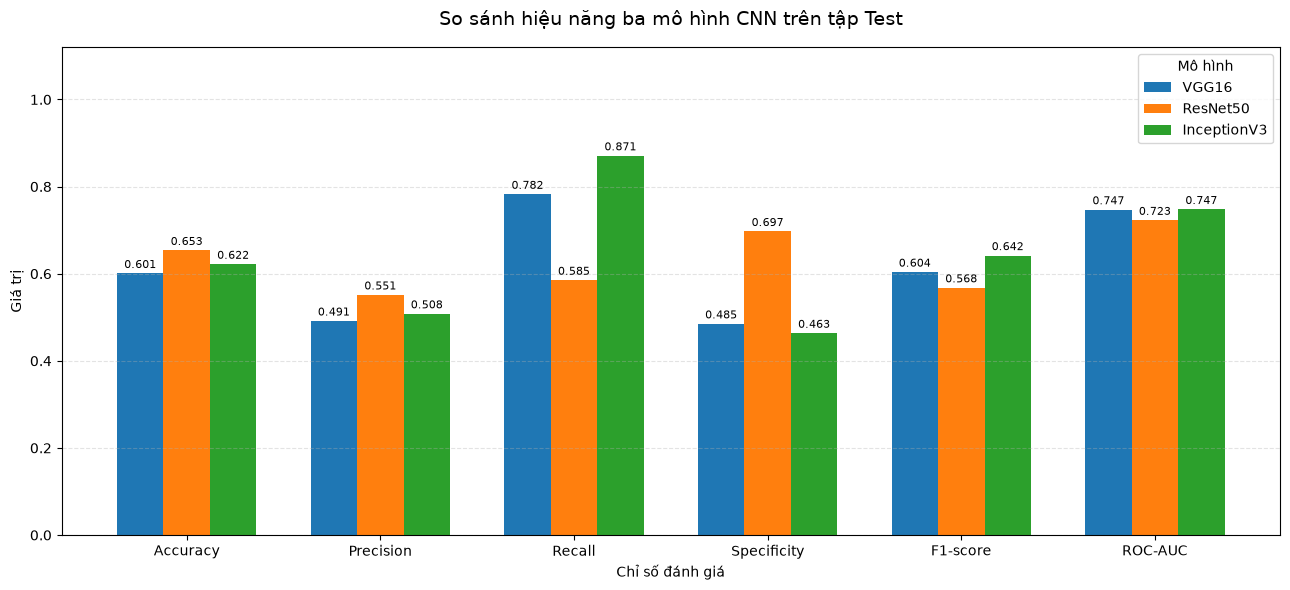

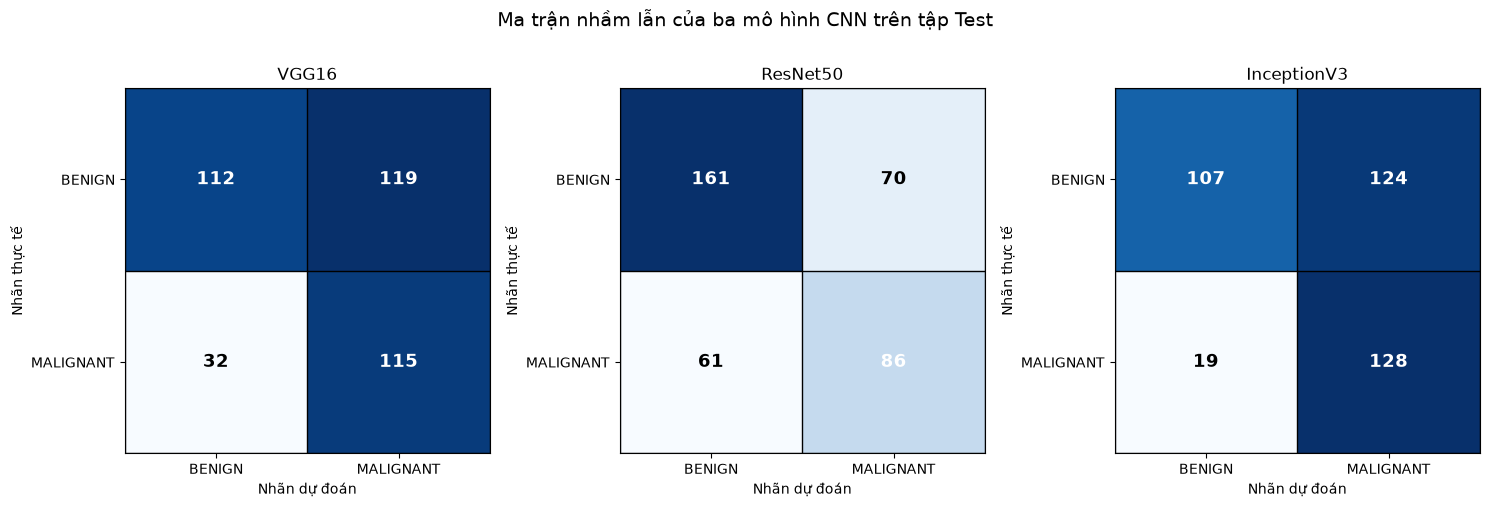


NHẬN XÉT TỔNG HỢP
- ResNet50 đạt Accuracy cao nhất (0.6534).
- ResNet50 đạt Precision cao nhất (0.5513).
- InceptionV3 đạt Recall cao nhất (0.8707).
- ResNet50 đạt Specificity cao nhất (0.6970).
- InceptionV3 đạt F1-score cao nhất (0.6416).
- InceptionV3 đạt ROC-AUC cao nhất (0.7475).

Các mô hình được đánh giá trên cùng tập Test gồm 378 crop, với 231 BENIGN và 147 MALIGNANT.
Ngưỡng phân loại của từng mô hình được giữ nguyên theo kết quả lựa chọn trên Validation.
Kết quả này phục vụ so sánh cuối cùng, không được dùng để điều chỉnh mô hình hoặc threshold.

KIỂM TRA VÀ LƯU KẾT QUẢ
PASS | nb09_5_cnn_test_comparison.csv
PASS | nb09_5_cnn_test_metric_leaders.csv
PASS | nb09_5_cnn_test_metric_comparison.png
PASS | nb09_5_cnn_test_confusion_matrices.png
PASS | nb09_5_cnn_test_comparison_summary.json
PASS | nb09_5_cnn_test_comparison_inventory.json

Số mô hình được so sánh: 3
Số mẫu Test: 378
Số mô hình có confusion matrix hợp lệ: 3
Không huấn luyện lại mô hình.
Không chạy dự đoán lại trên Te

In [ ]:
# 09.5 — TỔNG HỢP VÀ SO SÁNH BA MÔ HÌNH CNN TRÊN TẬP TEST

from datetime import datetime
import json
import re

print("=" * 78)
print("09.5 — TỔNG HỢP VÀ SO SÁNH BA MÔ HÌNH CNN TRÊN TẬP TEST")
print("=" * 78)

# ============================================================
# 1. CẤU HÌNH ĐƯỜNG DẪN
# ============================================================

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")

EVALUATION_ROOT = (
    PROJECT_ROOT
    / "Data"
    / "processed"
    / "nb09_model_evaluation"
)

CNN_TEST_DIR = EVALUATION_ROOT / "nb09_3_cnn_test_evaluation"

INPUT_CSV = CNN_TEST_DIR / "nb09_3_cnn_test_metrics.csv"
INPUT_JSON = CNN_TEST_DIR / "nb09_3_cnn_test_metrics.json"

OUTPUT_DIR = EVALUATION_ROOT / "nb09_5_cnn_test_comparison"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED_TEST_SIZE = 378

# Ngưỡng đã khóa từ Validation tại Notebook 08.8.8.
LOCKED_THRESHOLDS = {
    "VGG16": 0.30,
    "ResNet50": 0.50,
    "InceptionV3": 0.30,
}

MODEL_ORDER = ["VGG16", "ResNet50", "InceptionV3"]

print(f"Tệp kết quả CSV: {INPUT_CSV}")
print(f"Tệp kết quả JSON: {INPUT_JSON}")
print(f"Thư mục đầu ra: {OUTPUT_DIR}")

if not INPUT_CSV.exists():
    raise FileNotFoundError(
        f"Không tìm thấy kết quả CNN Test: {INPUT_CSV}"
    )

# ============================================================
# 2. ĐỌC VÀ KIỂM TRA KẾT QUẢ TỪ 09.3
# ============================================================

raw_df = pd.read_csv(INPUT_CSV)

if raw_df.empty:
    raise ValueError("Tệp kết quả CNN Test không có dữ liệu.")

print("\nCÁC CỘT TRONG TỆP KẾT QUẢ 09.3")
print(raw_df.columns.tolist())

def normalize_column_name(value):
    """Chuẩn hóa tên cột để đối chiếu các cách đặt tên."""

    return re.sub(
        r"[^a-z0-9]",
        "",
        str(value).strip().lower()
    )


column_lookup = {
    normalize_column_name(column): column
    for column in raw_df.columns
}


def find_column(candidates, required=True):
    """Tìm tên cột tương ứng trong tệp kết quả."""

    for candidate in candidates:
        key = normalize_column_name(candidate)

        if key in column_lookup:
            return column_lookup[key]

    if required:
        raise KeyError(
            f"Không tìm thấy cột cần thiết. "
            f"Các tên đã kiểm tra: {candidates}. "
            f"Các cột hiện có: {raw_df.columns.tolist()}"
        )

    return None


column_mapping = {
    "model": find_column(
        ["model", "model_name", "architecture"]
    ),
    "accuracy": find_column(
        ["accuracy", "acc"]
    ),
    "precision": find_column(
        ["precision", "ppv"]
    ),
    "recall": find_column(
        ["recall", "sensitivity", "tpr"]
    ),
    "specificity": find_column(
        ["specificity", "tnr"]
    ),
    "f1": find_column(
        ["f1", "f1_score", "f1score"]
    ),
    "roc_auc": find_column(
        ["roc_auc", "auc", "rocauc"]
    ),
    "tn": find_column(
        ["tn", "true_negative"]
    ),
    "fp": find_column(
        ["fp", "false_positive"]
    ),
    "fn": find_column(
        ["fn", "false_negative"]
    ),
    "tp": find_column(
        ["tp", "true_positive"]
    ),
    "threshold": find_column(
        ["threshold", "decision_threshold", "classification_threshold"],
        required=False
    ),
}

comparison_df = pd.DataFrame()

for standard_name, original_name in column_mapping.items():

    if original_name is not None:
        comparison_df[standard_name] = raw_df[original_name]

# Chuẩn hóa tên mô hình.
def standardize_model_name(value):
    text_value = str(value).strip().lower()

    if "vgg" in text_value:
        return "VGG16"

    if "resnet" in text_value:
        return "ResNet50"

    if "inception" in text_value:
        return "InceptionV3"

    raise ValueError(
        f"Không nhận diện được tên mô hình: {value}"
    )


comparison_df["model"] = comparison_df["model"].apply(
    standardize_model_name
)

if comparison_df["model"].duplicated().any():
    raise ValueError("Tệp kết quả có mô hình bị trùng.")

if set(comparison_df["model"]) != set(MODEL_ORDER):
    raise ValueError(
        "Danh sách mô hình trong kết quả không khớp "
        "VGG16, ResNet50 và InceptionV3."
    )

comparison_df["model"] = pd.Categorical(
    comparison_df["model"],
    categories=MODEL_ORDER,
    ordered=True
)

comparison_df = comparison_df.sort_values("model").reset_index(drop=True)

metric_columns = [
    "accuracy",
    "precision",
    "recall",
    "specificity",
    "f1",
    "roc_auc",
]

count_columns = ["tn", "fp", "fn", "tp"]

for column in metric_columns + count_columns:
    comparison_df[column] = pd.to_numeric(
        comparison_df[column],
        errors="coerce"
    )

if comparison_df[metric_columns + count_columns].isna().any().any():
    raise ValueError(
        "Có giá trị thiếu hoặc không hợp lệ trong các chỉ số đánh giá."
    )

# Nếu CSV không có threshold, sử dụng ngưỡng đã khóa từ Validation.
if "threshold" not in comparison_df.columns:
    comparison_df["threshold"] = comparison_df["model"].map(
        LOCKED_THRESHOLDS
    )
else:
    comparison_df["threshold"] = pd.to_numeric(
        comparison_df["threshold"],
        errors="coerce"
    )

    if comparison_df["threshold"].isna().any():
        raise ValueError("Có threshold bị thiếu trong kết quả 09.3.")

# ============================================================
# 3. KIỂM TRA TÍNH NHẤT QUÁN CỦA KẾT QUẢ
# ============================================================

for _, row in comparison_df.iterrows():

    model_name = str(row["model"])

    confusion_total = int(
        row["tn"] + row["fp"] + row["fn"] + row["tp"]
    )

    if confusion_total != EXPECTED_TEST_SIZE:
        raise AssertionError(
            f"{model_name}: tổng TN + FP + FN + TP "
            f"= {confusion_total}, không khớp {EXPECTED_TEST_SIZE}."
        )

    expected_threshold = LOCKED_THRESHOLDS[model_name]

    if not np.isclose(
        float(row["threshold"]),
        expected_threshold,
        atol=1e-8
    ):
        raise AssertionError(
            f"{model_name}: threshold trong kết quả "
            f"không khớp ngưỡng Validation đã khóa "
            f"({expected_threshold})."
        )

    # Kiểm tra các chỉ số tính lại từ confusion matrix.
    tn = int(row["tn"])
    fp = int(row["fp"])
    fn = int(row["fn"])
    tp = int(row["tp"])

    calculated_accuracy = (tp + tn) / confusion_total
    calculated_precision = tp / (tp + fp) if tp + fp else 0.0
    calculated_recall = tp / (tp + fn) if tp + fn else 0.0
    calculated_specificity = tn / (tn + fp) if tn + fp else 0.0

    calculated_f1 = (
        2 * calculated_precision * calculated_recall
        / (calculated_precision + calculated_recall)
        if calculated_precision + calculated_recall > 0
        else 0.0
    )

    checks = {
        "accuracy": calculated_accuracy,
        "precision": calculated_precision,
        "recall": calculated_recall,
        "specificity": calculated_specificity,
        "f1": calculated_f1,
    }

    for metric_name, calculated_value in checks.items():

        if not np.isclose(
            float(row[metric_name]),
            calculated_value,
            atol=1e-4
        ):
            raise AssertionError(
                f"{model_name}: {metric_name} trong CSV "
                f"không khớp giá trị tính từ confusion matrix."
            )

print("\nKIỂM TRA KẾT QUẢ 09.3")

for _, row in comparison_df.iterrows():
    print(
        f"PASS | {row['model']} | "
        f"Test={int(row['tn'] + row['fp'] + row['fn'] + row['tp'])} | "
        f"Threshold={row['threshold']:.2f}"
    )

print("Tất cả mô hình sử dụng cùng 378 mẫu Test.")
print("Các chỉ số từ confusion matrix được kiểm tra lại thành công.")

# ============================================================
# 4. TẠO BẢNG SO SÁNH CHỈ SỐ
# ============================================================

comparison_table = comparison_df[
    [
        "model",
        "threshold",
        "accuracy",
        "precision",
        "recall",
        "specificity",
        "f1",
        "roc_auc",
        "tn",
        "fp",
        "fn",
        "tp",
    ]
].copy()

comparison_table = comparison_table.rename(
    columns={
        "model": "Mô hình",
        "threshold": "Threshold",
        "accuracy": "Accuracy",
        "precision": "Precision",
        "recall": "Recall",
        "specificity": "Specificity",
        "f1": "F1-score",
        "roc_auc": "ROC-AUC",
        "tn": "TN",
        "fp": "FP",
        "fn": "FN",
        "tp": "TP",
    }
)

metric_max_records = []

for metric in metric_columns:

    best_index = comparison_df[metric].idxmax()
    best_row = comparison_df.loc[best_index]

    metric_max_records.append({
        "metric": metric,
        "best_model": str(best_row["model"]),
        "best_value": float(best_row[metric]),
    })

metric_leaders_df = pd.DataFrame(metric_max_records)

print("\n" + "=" * 78)
print("BẢNG SO SÁNH BA MÔ HÌNH CNN TRÊN TẬP TEST")
print("=" * 78)

display(
    comparison_table.style.format({
        "Threshold": "{:.2f}",
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "Specificity": "{:.4f}",
        "F1-score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
    })
)

print("\nMÔ HÌNH ĐẠT GIÁ TRỊ CAO NHẤT THEO TỪNG CHỈ SỐ")
display(metric_leaders_df)

# ============================================================
# 5. BIỂU ĐỒ SO SÁNH CÁC CHỈ SỐ
# ============================================================

plot_metrics = [
    ("accuracy", "Accuracy"),
    ("precision", "Precision"),
    ("recall", "Recall"),
    ("specificity", "Specificity"),
    ("f1", "F1-score"),
    ("roc_auc", "ROC-AUC"),
]

x_positions = np.arange(len(plot_metrics))
bar_width = 0.24

fig, ax = plt.subplots(figsize=(13, 6))

for model_index, model_name in enumerate(MODEL_ORDER):

    model_row = comparison_df[
        comparison_df["model"] == model_name
    ].iloc[0]

    values = [
        float(model_row[metric_name])
        for metric_name, _ in plot_metrics
    ]

    positions = (
        x_positions
        + (model_index - 1) * bar_width
    )

    bars = ax.bar(
        positions,
        values,
        width=bar_width,
        label=model_name
    )

    ax.bar_label(
        bars,
        labels=[f"{value:.3f}" for value in values],
        padding=2,
        fontsize=8
    )

ax.set_title(
    "So sánh hiệu năng ba mô hình CNN trên tập Test",
    fontsize=14,
    pad=16
)
ax.set_xlabel("Chỉ số đánh giá")
ax.set_ylabel("Giá trị")
ax.set_xticks(x_positions)
ax.set_xticklabels(
    [label for _, label in plot_metrics]
)
ax.set_ylim(0, 1.12)
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.legend(title="Mô hình")
fig.tight_layout()

comparison_plot_path = (
    OUTPUT_DIR / "nb09_5_cnn_test_metric_comparison.png"
)

fig.savefig(
    comparison_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ============================================================
# 6. BIỂU ĐỒ CONFUSION MATRIX
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4.8)
)

for ax, model_name in zip(axes, MODEL_ORDER):

    row = comparison_df[
        comparison_df["model"] == model_name
    ].iloc[0]

    tn = int(row["tn"])
    fp = int(row["fp"])
    fn = int(row["fn"])
    tp = int(row["tp"])

    matrix = np.array([
        [tn, fp],
        [fn, tp],
    ])

    image = ax.imshow(
        matrix,
        interpolation="nearest",
        cmap="Blues"
    )

    ax.set_title(model_name, fontsize=12)
    ax.set_xlabel("Nhãn dự đoán")
    ax.set_ylabel("Nhãn thực tế")

    ax.set_xticks([0, 1])
    ax.set_xticklabels(["BENIGN", "MALIGNANT"])
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["BENIGN", "MALIGNANT"])

    threshold_color = matrix.max() / 2

    for i in range(2):
        for j in range(2):

            ax.text(
                j,
                i,
                f"{matrix[i, j]}",
                ha="center",
                va="center",
                color=(
                    "white"
                    if matrix[i, j] > threshold_color
                    else "black"
                ),
                fontsize=13,
                fontweight="bold"
            )

    ax.set_xticks(
        np.arange(-0.5, 2, 1),
        minor=True
    )
    ax.set_yticks(
        np.arange(-0.5, 2, 1),
        minor=True
    )
    ax.grid(
        which="minor",
        color="black",
        linestyle="-",
        linewidth=1
    )
    ax.tick_params(
        which="minor",
        bottom=False,
        left=False
    )

fig.suptitle(
    "Ma trận nhầm lẫn của ba mô hình CNN trên tập Test",
    fontsize=14,
    y=1.03
)

fig.tight_layout()

confusion_plot_path = (
    OUTPUT_DIR / "nb09_5_cnn_test_confusion_matrices.png"
)

fig.savefig(
    confusion_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ============================================================
# 7. PHÂN TÍCH TỔNG HỢP VÀ TẠO NHẬN XÉT
# ============================================================

best_accuracy = comparison_df.loc[
    comparison_df["accuracy"].idxmax()
]

best_precision = comparison_df.loc[
    comparison_df["precision"].idxmax()
]

best_recall = comparison_df.loc[
    comparison_df["recall"].idxmax()
]

best_specificity = comparison_df.loc[
    comparison_df["specificity"].idxmax()
]

best_f1 = comparison_df.loc[
    comparison_df["f1"].idxmax()
]

best_auc = comparison_df.loc[
    comparison_df["roc_auc"].idxmax()
]

analysis_text = [
    (
        f"{best_accuracy['model']} đạt Accuracy cao nhất "
        f"({best_accuracy['accuracy']:.4f})."
    ),
    (
        f"{best_precision['model']} đạt Precision cao nhất "
        f"({best_precision['precision']:.4f})."
    ),
    (
        f"{best_recall['model']} đạt Recall cao nhất "
        f"({best_recall['recall']:.4f})."
    ),
    (
        f"{best_specificity['model']} đạt Specificity cao nhất "
        f"({best_specificity['specificity']:.4f})."
    ),
    (
        f"{best_f1['model']} đạt F1-score cao nhất "
        f"({best_f1['f1']:.4f})."
    ),
    (
        f"{best_auc['model']} đạt ROC-AUC cao nhất "
        f"({best_auc['roc_auc']:.4f})."
    ),
]

print("\n" + "=" * 78)
print("NHẬN XÉT TỔNG HỢP")
print("=" * 78)

for item in analysis_text:
    print(f"- {item}")

print(
    "\nCác mô hình được đánh giá trên cùng tập Test gồm "
    "378 crop, với 231 BENIGN và 147 MALIGNANT."
)

print(
    "Ngưỡng phân loại của từng mô hình được giữ nguyên "
    "theo kết quả lựa chọn trên Validation."
)

print(
    "Kết quả này phục vụ so sánh cuối cùng, "
    "không được dùng để điều chỉnh mô hình hoặc threshold."
)

# ============================================================
# 8. LƯU BẢNG SO SÁNH VÀ TÓM TẮT
# ============================================================

comparison_csv = (
    OUTPUT_DIR / "nb09_5_cnn_test_comparison.csv"
)

leaders_csv = (
    OUTPUT_DIR / "nb09_5_cnn_test_metric_leaders.csv"
)

summary_json = (
    OUTPUT_DIR / "nb09_5_cnn_test_comparison_summary.json"
)

inventory_json = (
    OUTPUT_DIR / "nb09_5_cnn_test_comparison_inventory.json"
)

comparison_table.to_csv(
    comparison_csv,
    index=False,
    encoding="utf-8-sig"
)

metric_leaders_df.to_csv(
    leaders_csv,
    index=False,
    encoding="utf-8-sig"
)

summary_payload = {
    "notebook_section": "09.5",
    "title": "Tổng hợp và so sánh ba mô hình CNN trên tập Test",
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "source": {
        "metrics_csv": str(INPUT_CSV),
        "metrics_json": str(INPUT_JSON),
    },
    "test_dataset": {
        "sample_count": EXPECTED_TEST_SIZE,
        "benign_count": 231,
        "malignant_count": 147,
        "same_test_set_for_all_models": True,
    },
    "thresholds": LOCKED_THRESHOLDS,
    "test_used_for_model_selection": False,
    "test_used_for_threshold_tuning": False,
    "comparison": comparison_df.astype({
        "model": str
    }).replace({
        np.nan: None
    }).to_dict(orient="records"),
    "metric_leaders": metric_leaders_df.to_dict(
        orient="records"
    ),
    "observations": analysis_text,
    "outputs": {
        "comparison_csv": str(comparison_csv),
        "metric_leaders_csv": str(leaders_csv),
        "metric_comparison_plot": str(comparison_plot_path),
        "confusion_matrices_plot": str(confusion_plot_path),
    },
}

with open(summary_json, "w", encoding="utf-8") as file:
    json.dump(
        summary_payload,
        file,
        ensure_ascii=False,
        indent=4
    )

output_files = [
    comparison_csv,
    leaders_csv,
    comparison_plot_path,
    confusion_plot_path,
    summary_json,
]

inventory = {
    "notebook_section": "09.5",
    "status": "PASS",
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "input_csv": str(INPUT_CSV),
    "output_directory": str(OUTPUT_DIR),
    "model_count": len(comparison_df),
    "test_sample_count": EXPECTED_TEST_SIZE,
    "thresholds_locked_from_validation": LOCKED_THRESHOLDS,
    "test_used_for_model_selection": False,
    "test_used_for_threshold_tuning": False,
    "files": {
        path.name: {
            "path": str(path),
            "exists": path.exists(),
            "size_bytes": path.stat().st_size if path.exists() else None,
        }
        for path in output_files
    },
}

with open(inventory_json, "w", encoding="utf-8") as file:
    json.dump(
        inventory,
        file,
        ensure_ascii=False,
        indent=4
    )

print("\n" + "=" * 78)
print("KIỂM TRA VÀ LƯU KẾT QUẢ")
print("=" * 78)

for path in output_files + [inventory_json]:
    status = "PASS" if path.exists() else "FAIL"
    print(f"{status} | {path.name}")

if not all(path.exists() for path in output_files + [inventory_json]):
    raise RuntimeError("Có tệp kết quả chưa được tạo thành công.")

print(f"\nSố mô hình được so sánh: {len(comparison_df)}")
print(f"Số mẫu Test: {EXPECTED_TEST_SIZE}")
print("Số mô hình có confusion matrix hợp lệ: 3")
print("Không huấn luyện lại mô hình.")
print("Không chạy dự đoán lại trên Test.")
print("Không điều chỉnh threshold bằng Test.")

print("\n" + "=" * 78)
print("09.5 — HOÀN THÀNH")
print("=" * 78)
print(f"Kết quả được lưu tại: {OUTPUT_DIR}")


09.7 — ĐÁNH GIÁ TOÀN BỘ TWO-STAGE PIPELINE

[1] KIỂM TRA CẤU TRÚC DỮ LIỆU
09.4 YOLO summary: (2, 19)
09.6 Detection summary: (2, 11)
09.6 CNN metrics: (6, 18)

[2] TỔNG HỢP HIỆU QUẢ YOLO DETECTION

[3] GHÉP KẾT QUẢ YOLO VÀ CNN

[4] BẢNG ĐÁNH GIÁ TOÀN BỘ TWO-STAGE PIPELINE


,YOLO,CNN,Detection TP,Detection FP,Detection FN,Detection Precision,Detection Recall,Matched Crops,CNN Accuracy,CNN Precision,CNN Recall,CNN Specificity,CNN F1,CNN AUC,E2E Malignant TP,E2E Malignant Sensitivity
0,YOLOv5n Baseline 640,VGG16,206,137,172,0.600583,0.544974,206,0.679612,0.631148,0.785714,0.583333,0.700000,0.769558,77,0.523810
1,YOLOv5n Baseline 640,ResNet50,206,137,172,0.600583,0.544974,206,0.708738,0.706522,0.663265,0.750000,0.684211,0.766440,65,0.442177
2,YOLOv5n Baseline 640,InceptionV3,206,137,172,0.600583,0.544974,206,0.679612,0.611111,0.897959,0.481481,0.727273,0.814815,88,0.598639
3,YOLOv5n Fine-tuned 640,VGG16,226,211,152,0.517162,0.597884,226,0.632743,0.570423,0.786408,0.504065,0.661224,0.747494,81,0.551020
4,YOLOv5n Fine-tuned 640,ResNet50,226,211,152,0.517162,0.597884,226,0.699115,0.680412,0.640777,0.747967,0.660000,0.759097,66,0.448980
5,YOLOv5n Fine-tuned 640,InceptionV3,226,211,152,0.517162,0.597884,226,0.650442,0.577922,0.864078,0.471545,0.692607,0.780054,89,0.605442



[5] THỐNG KÊ LỖI PHÁT HIỆN VÀ SỐ CROP ĐƯỢC GHÉP


,YOLO,CNN,GT,Predictions,Detection TP,Detection FP,Detection FN,Matched Crops,Benign Crops,Malignant Crops
0,YOLOv5n Baseline 640,VGG16,378,343,206,137,172,206,108,98
1,YOLOv5n Baseline 640,ResNet50,378,343,206,137,172,206,108,98
2,YOLOv5n Baseline 640,InceptionV3,378,343,206,137,172,206,108,98
3,YOLOv5n Fine-tuned 640,VGG16,378,437,226,211,152,226,123,103
4,YOLOv5n Fine-tuned 640,ResNet50,378,437,226,211,152,226,123,103
5,YOLOv5n Fine-tuned 640,InceptionV3,378,437,226,211,152,226,123,103



[6] ĐỘ NHẠY PHÁT HIỆN ÁC TÍNH TOÀN PIPELINE


,YOLO,CNN,E2E Malignant TP,E2E Malignant Total,E2E Malignant Sensitivity,E2E Malignant Miss Rate,E2E Malignant FN
0,YOLOv5n Baseline 640,VGG16,77,147,0.5238,0.4762,70
1,YOLOv5n Baseline 640,ResNet50,65,147,0.4422,0.5578,82
2,YOLOv5n Baseline 640,InceptionV3,88,147,0.5986,0.4014,59
3,YOLOv5n Fine-tuned 640,VGG16,81,147,0.5510,0.4490,66
4,YOLOv5n Fine-tuned 640,ResNet50,66,147,0.4490,0.5510,81
5,YOLOv5n Fine-tuned 640,InceptionV3,89,147,0.6054,0.3946,58



[7] KIỂM TRA TÍNH NHẤT QUÁN


,Kiểm tra,Kết quả,Chi tiết
0,Số lượng ảnh Test,PASS,361 ảnh
1,Số lượng annotation Test,PASS,378 annotation
2,Số lượng bệnh nhân Test,PASS,201 bệnh nhân
3,Số lượng mẫu MALIGNANT Test,PASS,147 mẫu MALIGNANT
4,Đủ hai cấu hình YOLO,PASS,2 cấu hình
5,Đủ ba mô hình CNN,PASS,3 mô hình
6,Đủ sáu tổ hợp YOLO-CNN,PASS,6 tổ hợp
7,CNN có mẫu đánh giá,PASS,Tất cả tổ hợp có mẫu đánh giá
8,Detection TP + FP = Predictions,PASS,Kiểm tra số lượng dự đoán
9,Detection TP + FN = Ground Truth,PASS,Kiểm tra số lượng Ground Truth


findfont: Failed to find font weight medium for DejaVu Sans, now using 400.



[8] THIẾT LẬP TRỰC QUAN HÓA


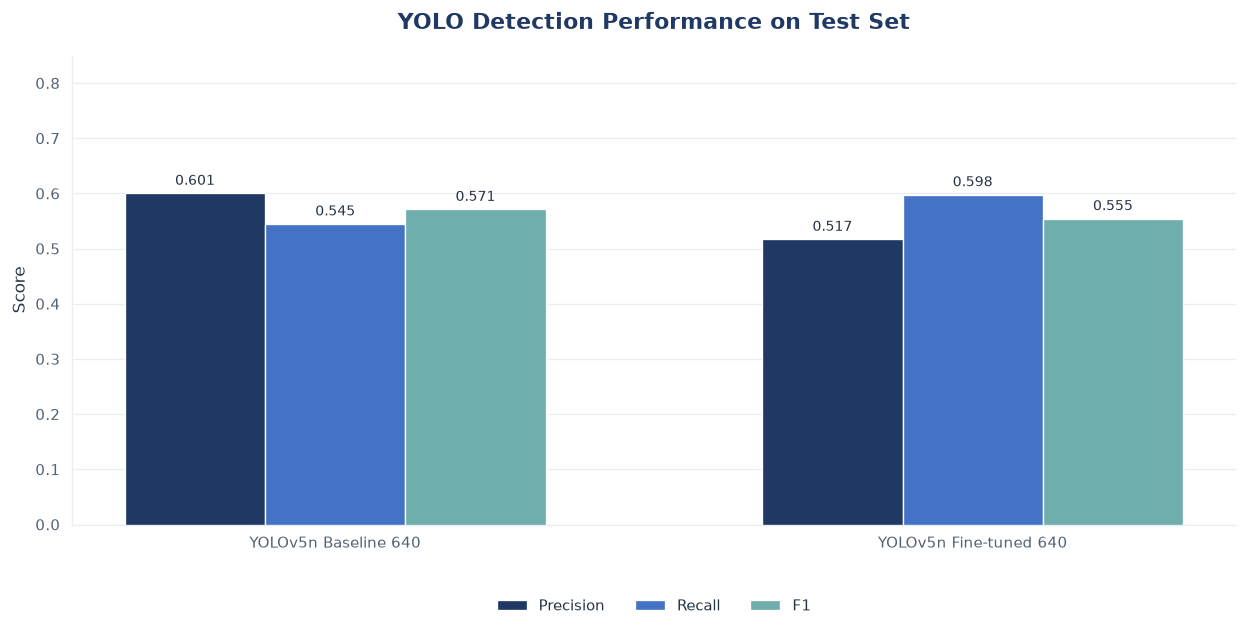

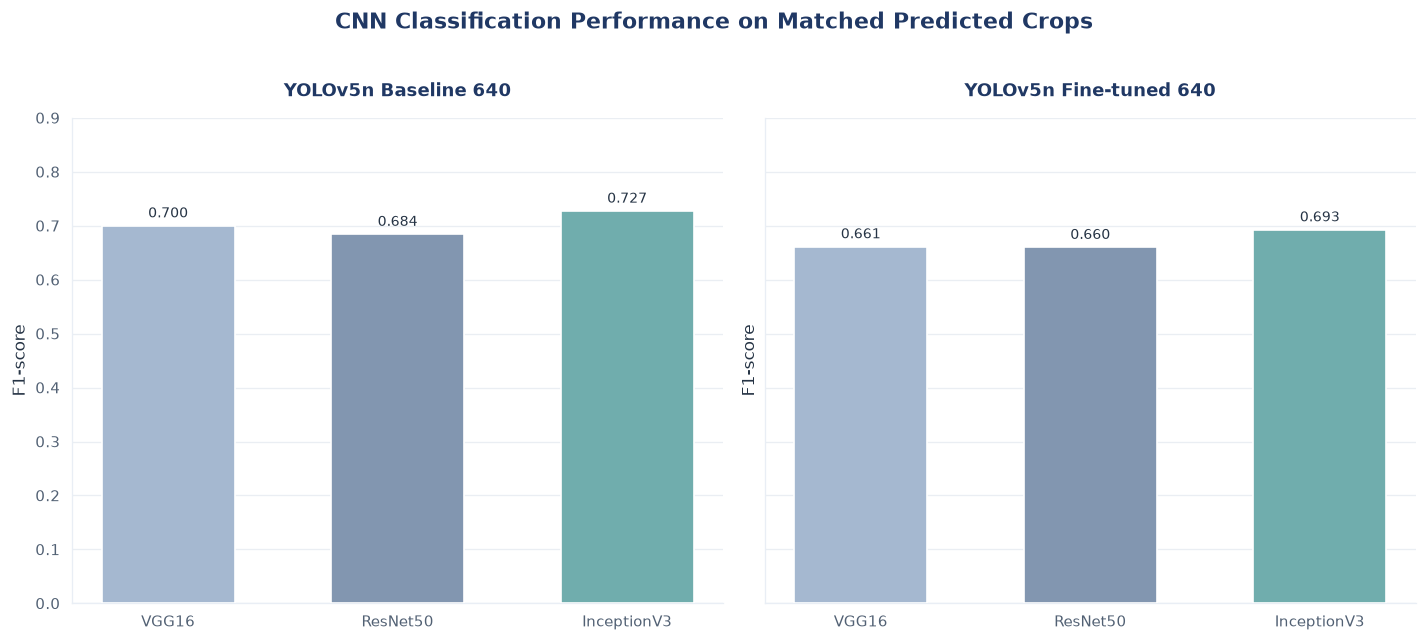

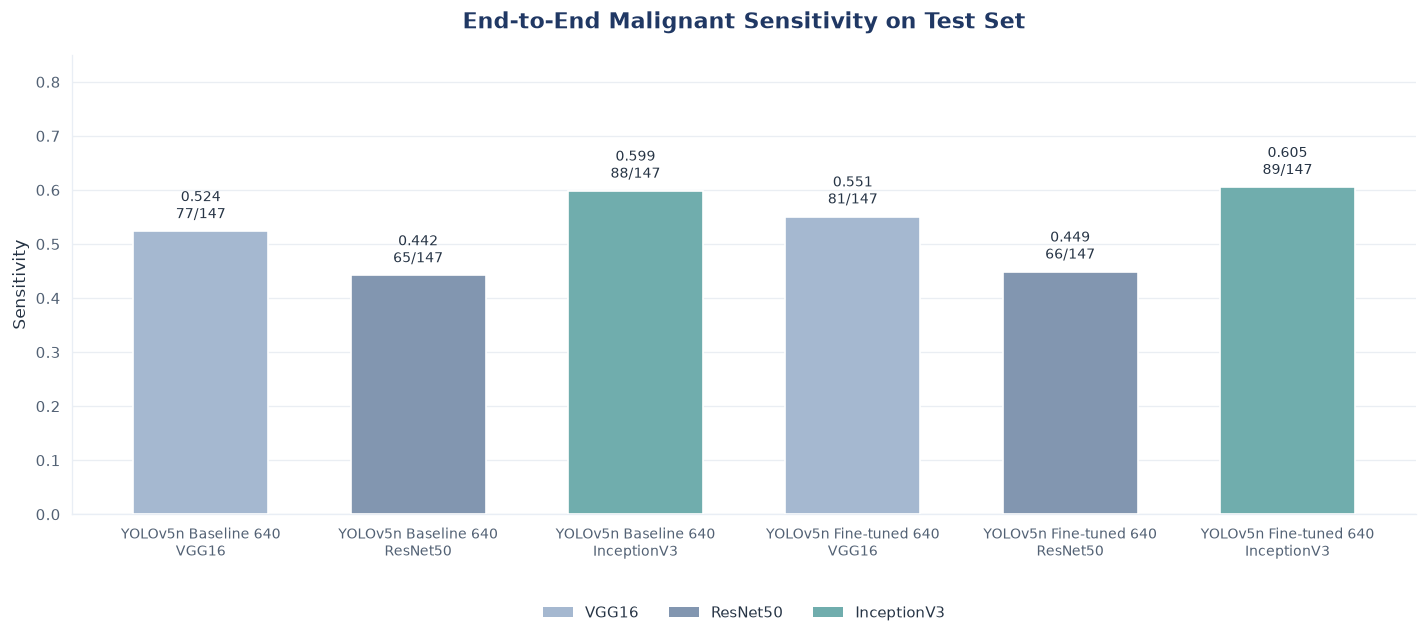

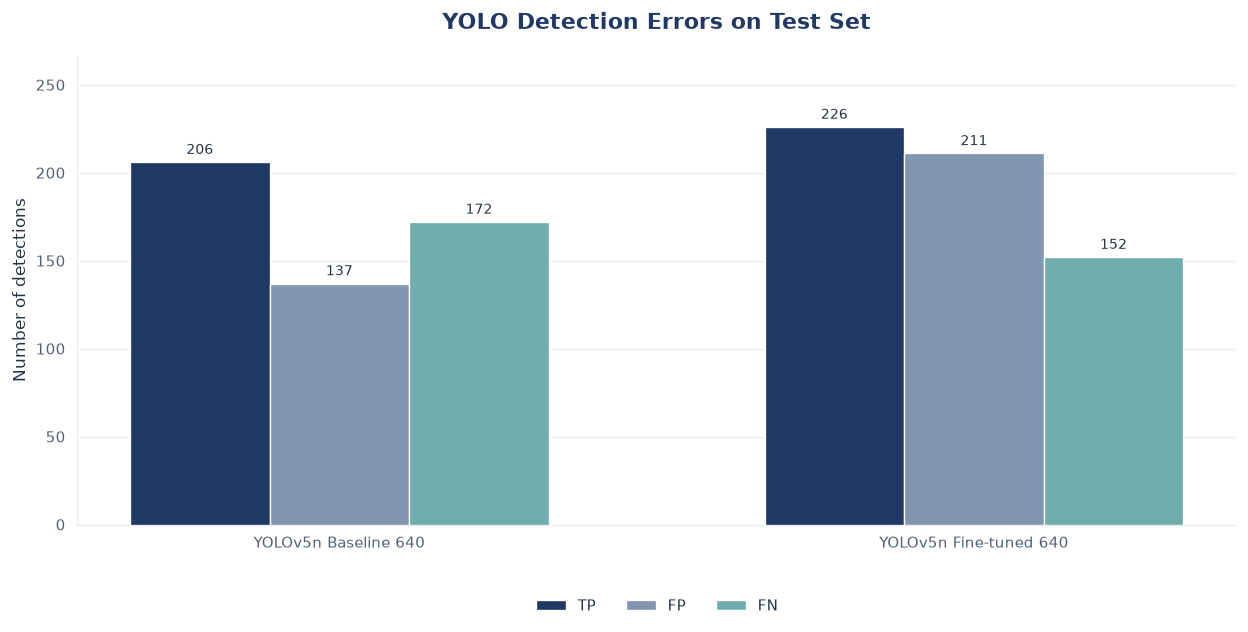


[9] TỔNG HỢP MÔ HÌNH DẪN ĐẦU


,Chỉ số,YOLO,CNN,Giá trị
0,CNN Accuracy,YOLOv5n Baseline 640,ResNet50,0.7087
1,CNN Precision,YOLOv5n Baseline 640,ResNet50,0.7065
2,CNN Recall,YOLOv5n Baseline 640,InceptionV3,0.8980
3,CNN Specificity,YOLOv5n Baseline 640,ResNet50,0.7500
4,CNN F1,YOLOv5n Baseline 640,InceptionV3,0.7273
5,CNN AUC,YOLOv5n Baseline 640,InceptionV3,0.8148
6,E2E Malignant Sensitivity,YOLOv5n Fine-tuned 640,InceptionV3,0.6054



[10] LƯU KẾT QUẢ

HOÀN TẤT NOTEBOOK 09.7
Thư mục kết quả: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb09_model_evaluation\nb09_7_two_stage_pipeline_evaluation
Số tổ hợp YOLO-CNN: 6
Kiểm tra toàn vẹn: 12/12 PASS
Số file kết quả: 12

CÁC FILE KẾT QUẢ:
  - nb09_7_1_yolo_detection_metrics.png
  - nb09_7_2_cnn_predicted_crop_f1.png
  - nb09_7_3_end_to_end_malignant_sensitivity.png
  - nb09_7_4_yolo_tp_fp_fn.png
  - nb09_7_detection_error_and_crop_summary.csv
  - nb09_7_end_to_end_malignant_summary.csv
  - nb09_7_integrity_report.csv
  - nb09_7_inventory.json
  - nb09_7_model_ranking.csv
  - nb09_7_summary.json
  - nb09_7_two_stage_pipeline_summary.csv
  - nb09_7_yolo_detection_summary.csv

LƯU Ý PHƯƠNG PHÁP:
- CNN được đánh giá trên các predicted crops ghép đúng với Ground Truth.
- Detection FP được báo cáo riêng, không tự gán nhãn BENIGN/MALIGNANT.
- End-to-End Malignant Sensitivity = CNN TP / 147 mẫu MALIGNANT Test.
- Chỉ số này không thay thế các chỉ số Detection và CNN riêng lẻ.
- Khôn

In [17]:
# 09.7 — ĐÁNH GIÁ TOÀN BỘ TWO-STAGE PIPELINE
# YOLOv5n Mass Detection → CNN Pathology Classification

from pathlib import Path
import json
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

# =============================================================================
# 1. CẤU HÌNH
# =============================================================================

THESIS_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")

EVAL_ROOT = (
    THESIS_ROOT
    / "Data"
    / "processed"
    / "nb09_model_evaluation"
)

DIR_094 = EVAL_ROOT / "nb09_4_yolo_test_error_analysis"
DIR_096 = EVAL_ROOT / "nb09_6_cnn_predicted_crop_evaluation"

OUTPUT_DIR = EVAL_ROOT / "nb09_7_two_stage_pipeline_evaluation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FILE_094_SUMMARY = (
    DIR_094 / "nb09_4_yolo_test_error_summary.csv"
)

FILE_096_DETECTION = (
    DIR_096 / "nb09_6_detection_matching_summary.csv"
)

FILE_096_CNN = (
    DIR_096 / "nb09_6_cnn_predicted_crop_metrics.csv"
)

EXPECTED_TEST_IMAGES = 361
EXPECTED_TEST_ANNOTATIONS = 378
EXPECTED_TEST_PATIENTS = 201
EXPECTED_TEST_BENIGN = 231
EXPECTED_TEST_MALIGNANT = 147

CNN_ORDER = ["VGG16", "ResNet50", "InceptionV3"]

YOLO_ORDER = [
    "YOLOv5n_Baseline_640",
    "YOLOv5n_FineTuned_640",
]

YOLO_DISPLAY = {
    "YOLOv5n_Baseline_640": "YOLOv5n Baseline 640",
    "YOLOv5n_FineTuned_640": "YOLOv5n Fine-tuned 640",
    "YOLOv5n_1024": "YOLOv5n Full 1024",
}

# Bảng màu thống nhất cho toàn bộ Notebook 09.7
COLORS = {
    "navy": "#203864",
    "blue": "#4472C4",
    "teal": "#70ADAD",
    "light_blue": "#A5B8D0",
    "steel": "#8296B0",
    "light_gray": "#E9EEF5",
    "dark_gray": "#526174",
    "text": "#263445",
    "grid": "#E5EAF1",
    "white": "#FFFFFF",
}

YOLO_COLORS = {
    "YOLOv5n_Baseline_640": COLORS["navy"],
    "YOLOv5n_FineTuned_640": COLORS["blue"],
}

CNN_COLORS = {
    "VGG16": COLORS["light_blue"],
    "ResNet50": COLORS["steel"],
    "InceptionV3": COLORS["teal"],
}

# =============================================================================
# 2. KIỂM TRA FILE ĐẦU VÀO VÀ ĐỌC DỮ LIỆU
# =============================================================================

print("=" * 90)
print("09.7 — ĐÁNH GIÁ TOÀN BỘ TWO-STAGE PIPELINE")
print("=" * 90)

required_files = [
    FILE_094_SUMMARY,
    FILE_096_DETECTION,
    FILE_096_CNN,
]

missing_files = [p for p in required_files if not p.exists()]

if missing_files:
    raise FileNotFoundError(
        "Không tìm thấy các file đầu vào:\n"
        + "\n".join(str(p) for p in missing_files)
    )

df_yolo_094 = pd.read_csv(FILE_094_SUMMARY)
df_detection_096 = pd.read_csv(FILE_096_DETECTION)
df_cnn_096 = pd.read_csv(FILE_096_CNN)

print("\n[1] KIỂM TRA CẤU TRÚC DỮ LIỆU")

required_094 = {
    "model",
    "confidence_threshold",
    "ground_truth",
    "predictions_after_threshold",
    "TP",
    "FP",
    "FN",
    "precision",
    "recall",
    "F1",
    "mean_matched_iou",
}

required_detection_096 = {
    "yolo_model",
    "confidence_threshold",
    "nms_iou",
    "ground_truth",
    "predictions_after_threshold",
    "matched_detections_TP",
    "unmatched_predictions_FP",
    "missed_ground_truth_FN",
    "detection_precision",
    "detection_recall",
    "matched_crop_count",
}

required_cnn_096 = {
    "yolo_model",
    "cnn_model",
    "cnn_threshold",
    "test_matched_crops",
    "benign_samples",
    "malignant_samples",
    "accuracy",
    "precision",
    "recall",
    "specificity",
    "f1_score",
    "roc_auc",
    "TN",
    "FP",
    "FN",
    "TP",
    "status",
}

def check_columns(df, required, name):
    missing = sorted(required - set(df.columns))

    if missing:
        raise ValueError(
            f"{name} thiếu cột bắt buộc: {missing}\n"
            f"Các cột hiện có: {df.columns.tolist()}"
        )

check_columns(df_yolo_094, required_094, "09.4 YOLO summary")
check_columns(
    df_detection_096,
    required_detection_096,
    "09.6 detection summary",
)
check_columns(
    df_cnn_096,
    required_cnn_096,
    "09.6 CNN metrics",
)

print(f"09.4 YOLO summary: {df_yolo_094.shape}")
print(f"09.6 Detection summary: {df_detection_096.shape}")
print(f"09.6 CNN metrics: {df_cnn_096.shape}")

# Chuẩn hóa kiểu dữ liệu
numeric_094 = [
    "confidence_threshold",
    "ground_truth",
    "predictions_after_threshold",
    "TP",
    "FP",
    "FN",
    "precision",
    "recall",
    "F1",
    "mean_matched_iou",
]

numeric_detection = [
    "confidence_threshold",
    "nms_iou",
    "ground_truth",
    "predictions_after_threshold",
    "matched_detections_TP",
    "unmatched_predictions_FP",
    "missed_ground_truth_FN",
    "detection_precision",
    "detection_recall",
    "matched_crop_count",
]

numeric_cnn = [
    "cnn_threshold",
    "test_matched_crops",
    "benign_samples",
    "malignant_samples",
    "accuracy",
    "precision",
    "recall",
    "specificity",
    "f1_score",
    "roc_auc",
    "TN",
    "FP",
    "FN",
    "TP",
]

for col in numeric_094:
    df_yolo_094[col] = pd.to_numeric(
        df_yolo_094[col], errors="coerce"
    )

for col in numeric_detection:
    df_detection_096[col] = pd.to_numeric(
        df_detection_096[col], errors="coerce"
    )

for col in numeric_cnn:
    df_cnn_096[col] = pd.to_numeric(
        df_cnn_096[col], errors="coerce"
    )

df_cnn_096["status"] = (
    df_cnn_096["status"].astype(str).str.upper()
)

cnn_failed = df_cnn_096[
    df_cnn_096["status"] != "PASS"
]

if not cnn_failed.empty:
    raise ValueError(
        "Có mô hình CNN không ở trạng thái PASS:\n"
        + cnn_failed.to_string(index=False)
    )

# =============================================================================
# 3. CHUẨN HÓA TÊN MÔ HÌNH
# =============================================================================

def normalize_yolo_name(value):
    value = str(value).strip()

    aliases = {
        "YOLOv5n_Baseline_640": "YOLOv5n_Baseline_640",
        "YOLOv5n_FineTuned_640": "YOLOv5n_FineTuned_640",
        "YOLOv5n_Finetuned_640": "YOLOv5n_FineTuned_640",
        "YOLOv5n_Fine-tuned_640": "YOLOv5n_FineTuned_640",
        "YOLOv5n_1024": "YOLOv5n_1024",
    }

    return aliases.get(value, value)

df_yolo_094["model"] = (
    df_yolo_094["model"].apply(normalize_yolo_name)
)

df_detection_096["yolo_model"] = (
    df_detection_096["yolo_model"].apply(normalize_yolo_name)
)

df_cnn_096["yolo_model"] = (
    df_cnn_096["yolo_model"].apply(normalize_yolo_name)
)

df_cnn_096["cnn_model"] = (
    df_cnn_096["cnn_model"].astype(str).str.strip()
)

# Chỉ dùng hai cấu hình YOLO có kết quả CNN predicted crops
df_detection_pipeline = df_detection_096[
    df_detection_096["yolo_model"].isin(YOLO_ORDER)
].copy()

df_cnn_pipeline = df_cnn_096[
    df_cnn_096["yolo_model"].isin(YOLO_ORDER)
    & df_cnn_096["cnn_model"].isin(CNN_ORDER)
].copy()

if set(df_cnn_pipeline["yolo_model"].unique()) != set(YOLO_ORDER):
    raise ValueError(
        "Không đủ hai cấu hình YOLO trong dữ liệu CNN 09.6.\n"
        f"Đang có: {df_cnn_pipeline['yolo_model'].unique().tolist()}"
    )

if set(df_cnn_pipeline["cnn_model"].unique()) != set(CNN_ORDER):
    raise ValueError(
        "Không đủ ba mô hình CNN trong dữ liệu 09.6.\n"
        f"Đang có: {df_cnn_pipeline['cnn_model'].unique().tolist()}"
    )

if len(df_cnn_pipeline) != 6:
    raise ValueError(
        f"Cần đúng 6 tổ hợp YOLO-CNN, hiện có {len(df_cnn_pipeline)}."
    )

# =============================================================================
# 4. TỔNG HỢP HIỆU QUẢ YOLO DETECTION TRÊN TEST
# =============================================================================

print("\n[2] TỔNG HỢP HIỆU QUẢ YOLO DETECTION")

detection_rows = []

for _, r in df_yolo_094.iterrows():

    model = r["model"]

    detection_rows.append({
        "YOLO": model,
        "Tên mô hình": YOLO_DISPLAY.get(model, model),
        "Confidence": r["confidence_threshold"],
        "Ground Truth": int(r["ground_truth"]),
        "Predictions": int(r["predictions_after_threshold"]),
        "TP": int(r["TP"]),
        "FP": int(r["FP"]),
        "FN": int(r["FN"]),
        "Precision": r["precision"],
        "Recall": r["recall"],
        "F1": r["F1"],
        "Mean IoU": r["mean_matched_iou"],
    })

df_detection_summary = pd.DataFrame(detection_rows)

if not (
    df_detection_summary["Predictions"]
    == df_detection_summary["TP"] + df_detection_summary["FP"]
).all():
    raise ValueError(
        "Detection không nhất quán: Predictions phải bằng TP + FP."
    )

if not (
    df_detection_summary["Ground Truth"]
    == df_detection_summary["TP"] + df_detection_summary["FN"]
).all():
    raise ValueError(
        "Detection không nhất quán: Ground Truth phải bằng TP + FN."
    )

# =============================================================================
# 5. GHÉP YOLO DETECTION VỚI CNN PREDICTED-CROP CLASSIFICATION
# =============================================================================

print("\n[3] GHÉP KẾT QUẢ YOLO VÀ CNN")

pipeline_rows = []

for _, cnn in df_cnn_pipeline.iterrows():

    yolo_name = cnn["yolo_model"]

    det_candidates = df_detection_pipeline[
        df_detection_pipeline["yolo_model"] == yolo_name
    ]

    if len(det_candidates) != 1:
        raise ValueError(
            f"Không xác định duy nhất dòng detection của {yolo_name}."
        )

    det = det_candidates.iloc[0]

    matched_count = int(det["matched_crop_count"])

    if int(cnn["test_matched_crops"]) != matched_count:
        raise ValueError(
            f"Số crop không khớp ở {yolo_name} / {cnn['cnn_model']}: "
            f"CNN={cnn['test_matched_crops']}, "
            f"Detection={matched_count}"
        )

    cnn_total = int(
        cnn["TN"] + cnn["FP"] + cnn["FN"] + cnn["TP"]
    )

    if cnn_total != int(cnn["test_matched_crops"]):
        raise ValueError(
            f"Ma trận nhầm lẫn CNN không khớp số mẫu: "
            f"{yolo_name} / {cnn['cnn_model']}"
        )

    if (
        int(cnn["benign_samples"])
        + int(cnn["malignant_samples"])
        != cnn_total
    ):
        raise ValueError(
            f"Phân bố nhãn CNN không khớp tổng số mẫu: "
            f"{yolo_name} / {cnn['cnn_model']}"
        )

    # Số MALIGNANT được phát hiện và phân loại đúng / toàn bộ 147 MALIGNANT
    e2e_sensitivity = (
        float(cnn["TP"]) / EXPECTED_TEST_MALIGNANT
    )

    e2e_miss_rate = 1.0 - e2e_sensitivity

    pipeline_rows.append({

        "YOLO": yolo_name,
        "CNN": cnn["cnn_model"],

        "YOLO Confidence": float(det["confidence_threshold"]),
        "NMS IoU": float(det["nms_iou"]),
        "CNN Threshold": float(cnn["cnn_threshold"]),

        "GT": int(det["ground_truth"]),
        "Predictions": int(det["predictions_after_threshold"]),
        "Detection TP": int(det["matched_detections_TP"]),
        "Detection FP": int(det["unmatched_predictions_FP"]),
        "Detection FN": int(det["missed_ground_truth_FN"]),

        "Detection Precision": float(det["detection_precision"]),
        "Detection Recall": float(det["detection_recall"]),

        "Matched Crops": matched_count,
        "Benign Crops": int(cnn["benign_samples"]),
        "Malignant Crops": int(cnn["malignant_samples"]),

        "CNN Accuracy": float(cnn["accuracy"]),
        "CNN Precision": float(cnn["precision"]),
        "CNN Recall": float(cnn["recall"]),
        "CNN Specificity": float(cnn["specificity"]),
        "CNN F1": float(cnn["f1_score"]),
        "CNN AUC": float(cnn["roc_auc"]),

        "CNN TN": int(cnn["TN"]),
        "CNN FP": int(cnn["FP"]),
        "CNN FN": int(cnn["FN"]),
        "CNN TP": int(cnn["TP"]),

        "E2E Malignant TP": int(cnn["TP"]),
        "E2E Malignant Total": EXPECTED_TEST_MALIGNANT,
        "E2E Malignant Sensitivity": e2e_sensitivity,
        "E2E Malignant Miss Rate": e2e_miss_rate,
    })

df_pipeline = pd.DataFrame(pipeline_rows)

df_pipeline["YOLO"] = pd.Categorical(
    df_pipeline["YOLO"],
    categories=YOLO_ORDER,
    ordered=True,
)

df_pipeline["CNN"] = pd.Categorical(
    df_pipeline["CNN"],
    categories=CNN_ORDER,
    ordered=True,
)

df_pipeline = (
    df_pipeline
    .sort_values(["YOLO", "CNN"])
    .reset_index(drop=True)
)

# =============================================================================
# 6. BẢNG TỔNG HỢP TOÀN BỘ TWO-STAGE PIPELINE
# =============================================================================

print("\n[4] BẢNG ĐÁNH GIÁ TOÀN BỘ TWO-STAGE PIPELINE")

display_columns = [
    "YOLO",
    "CNN",
    "Detection TP",
    "Detection FP",
    "Detection FN",
    "Detection Precision",
    "Detection Recall",
    "Matched Crops",
    "CNN Accuracy",
    "CNN Precision",
    "CNN Recall",
    "CNN Specificity",
    "CNN F1",
    "CNN AUC",
    "E2E Malignant TP",
    "E2E Malignant Sensitivity",
]

df_pipeline_display = df_pipeline[display_columns].copy()

df_pipeline_display["YOLO"] = (
    df_pipeline_display["YOLO"]
    .astype(str)
    .map(YOLO_DISPLAY)
)

percent_columns = [
    "Detection Precision",
    "Detection Recall",
    "CNN Accuracy",
    "CNN Precision",
    "CNN Recall",
    "CNN Specificity",
    "CNN F1",
    "CNN AUC",
    "E2E Malignant Sensitivity",
]

styled_pipeline = (
    df_pipeline_display.style
    .format({col: "{:.4f}" for col in percent_columns})
    .format({
        "Detection TP": "{:,.0f}",
        "Detection FP": "{:,.0f}",
        "Detection FN": "{:,.0f}",
        "Matched Crops": "{:,.0f}",
        "E2E Malignant TP": "{:,.0f}",
    })
    .background_gradient(
        subset=[
            "Detection Precision",
            "Detection Recall",
            "CNN Accuracy",
            "CNN F1",
            "CNN AUC",
            "E2E Malignant Sensitivity",
        ],
        cmap="GnBu",
    )
    .set_caption(
        "BẢNG ĐÁNH GIÁ TỔNG HỢP TWO-STAGE PIPELINE TRÊN TEST"
    )
    .set_properties(**{
        "text-align": "center",
        "padding": "7px",
        "border": "1px solid #D9E2F3",
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", COLORS["navy"]),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("padding", "9px"),
            ],
        },
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("font-size", "15px"),
                ("font-weight", "bold"),
                ("color", COLORS["navy"]),
                ("padding", "10px"),
            ],
        },
    ])
)

display(styled_pipeline)

# =============================================================================
# 7. BẢNG THỐNG KÊ DETECTION FP / FN VÀ CROP MATCHED
# =============================================================================

print("\n[5] THỐNG KÊ LỖI PHÁT HIỆN VÀ SỐ CROP ĐƯỢC GHÉP")

df_detection_errors = df_pipeline[
    [
        "YOLO",
        "CNN",
        "GT",
        "Predictions",
        "Detection TP",
        "Detection FP",
        "Detection FN",
        "Matched Crops",
        "Benign Crops",
        "Malignant Crops",
    ]
].copy()

df_detection_errors["YOLO"] = (
    df_detection_errors["YOLO"]
    .astype(str)
    .map(YOLO_DISPLAY)
)

display(
    df_detection_errors.style
    .format({
        col: "{:,.0f}"
        for col in [
            "GT",
            "Predictions",
            "Detection TP",
            "Detection FP",
            "Detection FN",
            "Matched Crops",
            "Benign Crops",
            "Malignant Crops",
        ]
    })
    .set_caption("THỐNG KÊ DETECTION VÀ CÁC CROP ĐƯỢC GHÉP")
    .set_properties(**{
        "text-align": "center",
        "padding": "7px",
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", COLORS["navy"]),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center"),
            ],
        },
    ])
)

# =============================================================================
# 8. PHÂN TÍCH HIỆU QUẢ MALIGNANT CỦA TOÀN PIPELINE
# =============================================================================

print("\n[6] ĐỘ NHẠY PHÁT HIỆN ÁC TÍNH TOÀN PIPELINE")

df_malignant = df_pipeline[
    [
        "YOLO",
        "CNN",
        "E2E Malignant TP",
        "E2E Malignant Total",
        "E2E Malignant Sensitivity",
        "E2E Malignant Miss Rate",
    ]
].copy()

df_malignant["YOLO"] = (
    df_malignant["YOLO"]
    .astype(str)
    .map(YOLO_DISPLAY)
)

df_malignant["E2E Malignant FN"] = (
    EXPECTED_TEST_MALIGNANT
    - df_malignant["E2E Malignant TP"]
)

display(
    df_malignant.style
    .format({
        "E2E Malignant Sensitivity": "{:.4f}",
        "E2E Malignant Miss Rate": "{:.4f}",
    })
    .background_gradient(
        subset=["E2E Malignant Sensitivity"],
        cmap="GnBu",
    )
    .set_caption(
        "ĐỘ NHẠY MALIGNANT TRÊN TOÀN BỘ 147 MẪU TEST"
    )
    .set_properties(**{
        "text-align": "center",
        "padding": "7px",
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", COLORS["navy"]),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center"),
            ],
        },
    ])
)

# =============================================================================
# 9. KIỂM TRA NHẤT QUÁN VÀ TOÀN VẸN KẾT QUẢ
# =============================================================================

print("\n[7] KIỂM TRA TÍNH NHẤT QUÁN")

integrity_checks = []

def add_check(name, condition, detail):
    integrity_checks.append({
        "Kiểm tra": name,
        "Kết quả": "PASS" if bool(condition) else "FAIL",
        "Chi tiết": str(detail),
    })

add_check(
    "Số lượng ảnh Test",
    EXPECTED_TEST_IMAGES == 361,
    f"{EXPECTED_TEST_IMAGES} ảnh",
)

add_check(
    "Số lượng annotation Test",
    EXPECTED_TEST_ANNOTATIONS == 378,
    f"{EXPECTED_TEST_ANNOTATIONS} annotation",
)

add_check(
    "Số lượng bệnh nhân Test",
    EXPECTED_TEST_PATIENTS == 201,
    f"{EXPECTED_TEST_PATIENTS} bệnh nhân",
)

add_check(
    "Số lượng mẫu MALIGNANT Test",
    EXPECTED_TEST_MALIGNANT == 147,
    f"{EXPECTED_TEST_MALIGNANT} mẫu MALIGNANT",
)

# Dùng đúng tên cột gốc của df_cnn_pipeline
add_check(
    "Đủ hai cấu hình YOLO",
    set(df_cnn_pipeline["yolo_model"].astype(str)) == set(YOLO_ORDER),
    f"{df_cnn_pipeline['yolo_model'].nunique()} cấu hình",
)

add_check(
    "Đủ ba mô hình CNN",
    set(df_cnn_pipeline["cnn_model"].astype(str)) == set(CNN_ORDER),
    f"{df_cnn_pipeline['cnn_model'].nunique()} mô hình",
)

add_check(
    "Đủ sáu tổ hợp YOLO-CNN",
    len(df_pipeline) == 6,
    f"{len(df_pipeline)} tổ hợp",
)

add_check(
    "CNN có mẫu đánh giá",
    (df_cnn_pipeline["test_matched_crops"] > 0).all(),
    "Tất cả tổ hợp có mẫu đánh giá",
)

add_check(
    "Detection TP + FP = Predictions",
    (
        df_pipeline["Detection TP"]
        + df_pipeline["Detection FP"]
        == df_pipeline["Predictions"]
    ).all(),
    "Kiểm tra số lượng dự đoán",
)

add_check(
    "Detection TP + FN = Ground Truth",
    (
        df_pipeline["Detection TP"]
        + df_pipeline["Detection FN"]
        == df_pipeline["GT"]
    ).all(),
    "Kiểm tra số lượng Ground Truth",
)

add_check(
    "CNN confusion matrix hợp lệ",
    (
        df_pipeline["CNN TN"]
        + df_pipeline["CNN FP"]
        + df_pipeline["CNN FN"]
        + df_pipeline["CNN TP"]
        == df_pipeline["Matched Crops"]
    ).all(),
    "TN + FP + FN + TP = Matched Crops",
)

add_check(
    "End-to-End malignant sensitivity hợp lệ",
    np.isclose(
        df_pipeline["E2E Malignant Sensitivity"],
        df_pipeline["E2E Malignant TP"] / EXPECTED_TEST_MALIGNANT,
    ).all(),
    "Mẫu số cố định là 147 MALIGNANT",
)

df_integrity = pd.DataFrame(integrity_checks)

display(
    df_integrity.style
    .map(
        lambda x: (
            "background-color: #D9EAD3; color: #274E13; font-weight: bold"
            if x == "PASS"
            else "background-color: #F4CCCC; color: #990000; font-weight: bold"
        ),
        subset=["Kết quả"],
    )
    .set_caption("BÁO CÁO KIỂM TRA TÍNH NHẤT QUÁN")
    .set_properties(**{"padding": "7px"})
)

if (df_integrity["Kết quả"] != "PASS").any():
    raise AssertionError(
        "Có kiểm tra tính nhất quán không đạt. "
        "Không tiếp tục kết luận kết quả."
    )

# =============================================================================
# 10. THIẾT LẬP PHONG CÁCH BIỂU ĐỒ CHUNG
# =============================================================================

print("\n[8] THIẾT LẬP TRỰC QUAN HÓA")

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "figure.facecolor": COLORS["white"],
    "axes.facecolor": COLORS["white"],
    "axes.edgecolor": COLORS["light_gray"],
    "axes.labelcolor": COLORS["text"],
    "axes.titlecolor": COLORS["navy"],
    "xtick.color": COLORS["dark_gray"],
    "ytick.color": COLORS["dark_gray"],
    "text.color": COLORS["text"],
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "legend.fontsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

def format_axis(ax):
    ax.set_axisbelow(True)
    ax.grid(
        axis="y",
        color=COLORS["grid"],
        linewidth=0.8,
        linestyle="-",
    )
    ax.spines["left"].set_color(COLORS["light_gray"])
    ax.spines["bottom"].set_color(COLORS["light_gray"])
    ax.tick_params(axis="both", length=0, pad=7)

def add_bar_labels(ax, bars, fmt="{:.3f}", padding=3):
    for bar in bars:
        value = bar.get_height()

        ax.annotate(
            fmt.format(value),
            xy=(
                bar.get_x() + bar.get_width() / 2,
                value,
            ),
            xytext=(0, padding),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8.5,
            fontweight="medium",
            color=COLORS["text"],
        )

# =============================================================================
# 11. BIỂU ĐỒ YOLO DETECTION: PRECISION – RECALL – F1
# =============================================================================

plot_det = df_detection_summary.copy()

fig, ax = plt.subplots(figsize=(10.5, 5.4))

x = np.arange(len(plot_det))
width = 0.22

metric_settings = [
    ("Precision", COLORS["navy"]),
    ("Recall", COLORS["blue"]),
    ("F1", COLORS["teal"]),
]

for i, (metric, color) in enumerate(metric_settings):

    bars = ax.bar(
        x + (i - 1) * width,
        plot_det[metric],
        width,
        label=metric,
        color=color,
        edgecolor=COLORS["white"],
        linewidth=0.8,
        zorder=3,
    )

    add_bar_labels(ax, bars)

ax.set_title(
    "YOLO Detection Performance on Test Set",
    pad=16,
)
ax.set_ylabel("Score")
ax.set_xticks(x)
ax.set_xticklabels(
    plot_det["Tên mô hình"],
    fontsize=9,
)
ax.set_ylim(0, 0.85)

format_axis(ax)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.13),
    ncol=3,
    frameon=False,
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "nb09_7_1_yolo_detection_metrics.png",
    bbox_inches="tight",
    facecolor=COLORS["white"],
)
plt.show()

# =============================================================================
# 12. BIỂU ĐỒ CNN F1: BASELINE VS FINE-TUNED
# =============================================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5.2),
    sharey=True,
)

for ax, yolo_name in zip(axes, YOLO_ORDER):

    sub = df_pipeline[
        df_pipeline["YOLO"].astype(str) == yolo_name
    ].copy()

    sub["CNN"] = sub["CNN"].astype(str)

    sub = (
        sub.set_index("CNN")
        .reindex(CNN_ORDER)
        .reset_index()
    )

    bars = ax.bar(
        sub["CNN"],
        sub["CNN F1"],
        width=0.58,
        color=[
            CNN_COLORS[name]
            for name in sub["CNN"]
        ],
        edgecolor=COLORS["white"],
        linewidth=1,
        zorder=3,
    )

    add_bar_labels(ax, bars)

    ax.set_title(
        YOLO_DISPLAY[yolo_name],
        pad=13,
        fontsize=11,
    )

    ax.set_ylim(0, 0.9)
    ax.set_ylabel("F1-score")

    format_axis(ax)

fig.suptitle(
    "CNN Classification Performance on Matched Predicted Crops",
    fontsize=13,
    fontweight="bold",
    color=COLORS["navy"],
    y=1.02,
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "nb09_7_2_cnn_predicted_crop_f1.png",
    bbox_inches="tight",
    facecolor=COLORS["white"],
)
plt.show()

# =============================================================================
# 13. BIỂU ĐỒ END-TO-END MALIGNANT SENSITIVITY
# =============================================================================

plot_e2e = df_pipeline.copy()

plot_e2e["Tên tổ hợp"] = (
    plot_e2e["YOLO"].astype(str).map(YOLO_DISPLAY)
    + "\n"
    + plot_e2e["CNN"].astype(str)
)

fig, ax = plt.subplots(figsize=(12, 5.5))

bar_colors = [
    CNN_COLORS[str(cnn)]
    for cnn in plot_e2e["CNN"]
]

bars = ax.bar(
    np.arange(len(plot_e2e)),
    plot_e2e["E2E Malignant Sensitivity"],
    width=0.62,
    color=bar_colors,
    edgecolor=COLORS["white"],
    linewidth=1,
    zorder=3,
)

for bar, value, tp in zip(
    bars,
    plot_e2e["E2E Malignant Sensitivity"],
    plot_e2e["E2E Malignant TP"],
):
    ax.annotate(
        f"{value:.3f}\n{int(tp)}/147",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
        ),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=8.5,
        fontweight="medium",
        color=COLORS["text"],
    )

ax.set_title(
    "End-to-End Malignant Sensitivity on Test Set",
    pad=16,
)
ax.set_ylabel("Sensitivity")
ax.set_xticks(np.arange(len(plot_e2e)))
ax.set_xticklabels(
    plot_e2e["Tên tổ hợp"],
    fontsize=8.5,
)
ax.set_ylim(0, 0.85)

format_axis(ax)

legend_items = [
    Patch(
        facecolor=CNN_COLORS[name],
        label=name,
    )
    for name in CNN_ORDER
]

ax.legend(
    handles=legend_items,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.17),
    ncol=3,
    frameon=False,
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "nb09_7_3_end_to_end_malignant_sensitivity.png",
    bbox_inches="tight",
    facecolor=COLORS["white"],
)
plt.show()

# =============================================================================
# 14. BIỂU ĐỒ YOLO TP – FP – FN
# =============================================================================

plot_counts = df_detection_summary.copy()

fig, ax = plt.subplots(figsize=(10.5, 5.4))

x = np.arange(len(plot_counts))
width = 0.22

count_settings = [
    ("TP", COLORS["navy"]),
    ("FP", COLORS["steel"]),
    ("FN", COLORS["teal"]),
]

for i, (metric, color) in enumerate(count_settings):

    bars = ax.bar(
        x + (i - 1) * width,
        plot_counts[metric],
        width,
        label=metric,
        color=color,
        edgecolor=COLORS["white"],
        linewidth=0.8,
        zorder=3,
    )

    for bar in bars:
        value = bar.get_height()

        ax.annotate(
            f"{int(value)}",
            xy=(
                bar.get_x() + bar.get_width() / 2,
                value,
            ),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8.5,
            color=COLORS["text"],
        )

ax.set_title(
    "YOLO Detection Errors on Test Set",
    pad=16,
)
ax.set_ylabel("Number of detections")
ax.set_xticks(x)
ax.set_xticklabels(
    plot_counts["Tên mô hình"],
    fontsize=9,
)

ax.set_ylim(
    0,
    max(
        plot_counts[["TP", "FP", "FN"]].max().max() * 1.18,
        10,
    ),
)

format_axis(ax)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.13),
    ncol=3,
    frameon=False,
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "nb09_7_4_yolo_tp_fp_fn.png",
    bbox_inches="tight",
    facecolor=COLORS["white"],
)
plt.show()

# =============================================================================
# 15. XÁC ĐỊNH MÔ HÌNH DẪN ĐẦU THEO TỪNG CHỈ SỐ
# =============================================================================

print("\n[9] TỔNG HỢP MÔ HÌNH DẪN ĐẦU")

ranking_metrics = {
    "CNN Accuracy": "max",
    "CNN Precision": "max",
    "CNN Recall": "max",
    "CNN Specificity": "max",
    "CNN F1": "max",
    "CNN AUC": "max",
    "E2E Malignant Sensitivity": "max",
}

ranking_rows = []

for metric, direction in ranking_metrics.items():

    best_idx = df_pipeline[metric].idxmax()
    best = df_pipeline.loc[best_idx]

    ranking_rows.append({
        "Chỉ số": metric,
        "YOLO": YOLO_DISPLAY[str(best["YOLO"])],
        "CNN": str(best["CNN"]),
        "Giá trị": float(best[metric]),
    })

df_ranking = pd.DataFrame(ranking_rows)

display(
    df_ranking.style
    .format({"Giá trị": "{:.4f}"})
    .background_gradient(
        subset=["Giá trị"],
        cmap="GnBu",
    )
    .set_caption("MÔ HÌNH DẪN ĐẦU THEO TỪNG CHỈ SỐ")
    .set_properties(**{
        "text-align": "center",
        "padding": "7px",
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", COLORS["navy"]),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center"),
            ],
        },
    ])
)

# =============================================================================
# 16. LƯU KẾT QUẢ
# =============================================================================

print("\n[10] LƯU KẾT QUẢ")

df_detection_summary.to_csv(
    OUTPUT_DIR / "nb09_7_yolo_detection_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

df_pipeline.to_csv(
    OUTPUT_DIR / "nb09_7_two_stage_pipeline_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

df_detection_errors.to_csv(
    OUTPUT_DIR / "nb09_7_detection_error_and_crop_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

df_malignant.to_csv(
    OUTPUT_DIR / "nb09_7_end_to_end_malignant_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

df_ranking.to_csv(
    OUTPUT_DIR / "nb09_7_model_ranking.csv",
    index=False,
    encoding="utf-8-sig",
)

df_integrity.to_csv(
    OUTPUT_DIR / "nb09_7_integrity_report.csv",
    index=False,
    encoding="utf-8-sig",
)

# =============================================================================
# 17. TẠO JSON SUMMARY VÀ KIỂM KÊ OUTPUT
# =============================================================================

summary_json = {
    "notebook_section": "09.7",
    "title": "Đánh giá toàn bộ Two-Stage Pipeline",
    "evaluation_split": "Test",

    "test_data": {
        "images": EXPECTED_TEST_IMAGES,
        "annotations": EXPECTED_TEST_ANNOTATIONS,
        "patients": EXPECTED_TEST_PATIENTS,
        "benign": EXPECTED_TEST_BENIGN,
        "malignant": EXPECTED_TEST_MALIGNANT,
    },

    "methodology": {
        "yolo_thresholds": "Giữ nguyên ngưỡng đã khóa từ Validation",
        "cnn_thresholds": "Giữ nguyên ngưỡng đã khóa từ Validation",
        "retraining": False,
        "test_threshold_tuning": False,
        "false_positive_pathology_assignment": False,
        "end_to_end_malignant_sensitivity_denominator": EXPECTED_TEST_MALIGNANT,
    },

    "detection_models": (
        df_detection_summary
        .replace({np.nan: None})
        .to_dict(orient="records")
    ),

    "two_stage_combinations": (
        df_pipeline
        .replace({np.nan: None})
        .to_dict(orient="records")
    ),

    "model_ranking": (
        df_ranking
        .replace({np.nan: None})
        .to_dict(orient="records")
    ),

    "integrity": {
        "passed": int(
            (df_integrity["Kết quả"] == "PASS").sum()
        ),
        "failed": int(
            (df_integrity["Kết quả"] == "FAIL").sum()
        ),
        "status": "PASS",
    },

    "interpretation_notes": [
        "CNN metrics are conditional on correctly matched predicted crops.",
        "Unmatched YOLO predictions are reported as detection false positives.",
        "No pathology labels are assigned to unmatched predictions.",
        "End-to-end malignant sensitivity uses all 147 malignant Test annotations as denominator.",
        "The end-to-end metric measures correctly detected and classified malignant annotations.",
    ],
}

with open(
    OUTPUT_DIR / "nb09_7_summary.json",
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        summary_json,
        f,
        ensure_ascii=False,
        indent=4,
        default=lambda x: (
            int(x) if isinstance(x, np.integer)
            else float(x) if isinstance(x, np.floating)
            else str(x)
        ),
    )

# Kiểm kê các file kết quả trước khi tạo inventory
output_files = sorted(
    p for p in OUTPUT_DIR.iterdir()
    if p.is_file()
    and p.name != "nb09_7_inventory.json"
)

inventory = {
    "output_directory": str(OUTPUT_DIR),
    "created_at": time.strftime("%Y-%m-%d %H:%M:%S"),
    "file_count": len(output_files),
    "files": [
        {
            "file_name": p.name,
            "size_bytes": p.stat().st_size,
        }
        for p in output_files
    ],
}

with open(
    OUTPUT_DIR / "nb09_7_inventory.json",
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        inventory,
        f,
        ensure_ascii=False,
        indent=4,
    )

# =============================================================================
# 18. KẾT LUẬN KỸ THUẬT
# =============================================================================

print("\n" + "=" * 90)
print("HOÀN TẤT NOTEBOOK 09.7")
print("=" * 90)

print(f"Thư mục kết quả: {OUTPUT_DIR}")
print(f"Số tổ hợp YOLO-CNN: {len(df_pipeline)}")

print(
    "Kiểm tra toàn vẹn: "
    f"{(df_integrity['Kết quả'] == 'PASS').sum()}/"
    f"{len(df_integrity)} PASS"
)

print(f"Số file kết quả: {len(output_files) + 1}")

print("\nCÁC FILE KẾT QUẢ:")

for p in sorted(OUTPUT_DIR.iterdir()):
    if p.is_file():
        print(f"  - {p.name}")

print("\nLƯU Ý PHƯƠNG PHÁP:")
print(
    "- CNN được đánh giá trên các predicted crops ghép đúng với Ground Truth."
)
print(
    "- Detection FP được báo cáo riêng, không tự gán nhãn BENIGN/MALIGNANT."
)
print(
    "- End-to-End Malignant Sensitivity = CNN TP / 147 mẫu MALIGNANT Test."
)
print(
    "- Chỉ số này không thay thế các chỉ số Detection và CNN riêng lẻ."
)
print(
    "- Không sử dụng Test để chọn mô hình hoặc điều chỉnh threshold."
)

print("\nTRẠNG THÁI: PASS")
print("=" * 90)


KIỂM TRA ĐẦU VÀO 09.8


Kiểm tra,Số lượng,Kết quả
Số mô hình CNN,3,PASS
Số mô hình YOLO,2,PASS
Số trường hợp phát hiện YOLO,1104,PASS
Số crop dự đoán,432,PASS
Số tổ hợp Two-stage,6,PASS


KẾT QUẢ PHÂN TÍCH LỖI CNN TRÊN GROUND TRUTH CROPS


model_name,Correct,FN - MALIGNANT bị dự đoán BENIGN,FP - BENIGN bị dự đoán MALIGNANT,Total Errors,Total Samples,Error Rate
VGG16,227,32,119,151,378,39.95%
ResNet50,247,61,70,131,378,34.66%
InceptionV3,235,19,124,143,378,37.83%


ĐẶC ĐIỂM CÁC LỖI CNN


model_name,error_type,error_count,mean_probability,mean_threshold_distance,unique_patients
InceptionV3,FN - MALIGNANT bị dự đoán BENIGN,19,0.1754,0.1246,18
InceptionV3,FP - BENIGN bị dự đoán MALIGNANT,124,0.6037,0.3037,89
ResNet50,FN - MALIGNANT bị dự đoán BENIGN,61,0.3329,0.1671,46
ResNet50,FP - BENIGN bị dự đoán MALIGNANT,70,0.6840,0.1840,60
VGG16,FN - MALIGNANT bị dự đoán BENIGN,32,0.2297,0.0703,24
VGG16,FP - BENIGN bị dự đoán MALIGNANT,119,0.4267,0.1267,84


... (6 outputs left out)

TỔNG HỢP LỖI TWO-STAGE PIPELINE


YOLO,CNN,Detection TP,Detection FP,Detection FN,Matched Crops,CNN Misclassified,CNN False Negative,CNN False Positive,End-to-end YOLO Missed MALIGNANT,End-to-end CNN Missed MALIGNANT,End-to-end MALIGNANT TP,End-to-end MALIGNANT Total,End-to-end MALIGNANT Sensitivity
YOLOv5n_Baseline_640,VGG16,206,137,172,206,66,21,45,49,21,77,147,52.38%
YOLOv5n_Baseline_640,ResNet50,206,137,172,206,60,33,27,49,33,65,147,44.22%
YOLOv5n_Baseline_640,InceptionV3,206,137,172,206,66,10,56,49,10,88,147,59.86%
YOLOv5n_FineTuned_640,VGG16,226,211,152,226,83,22,61,44,22,81,147,55.10%
YOLOv5n_FineTuned_640,ResNet50,226,211,152,226,68,37,31,44,37,66,147,44.90%
YOLOv5n_FineTuned_640,InceptionV3,226,211,152,226,79,14,65,44,14,89,147,60.54%


PHÂN RÃ KẾT QUẢ MALIGNANT TRONG TOÀN BỘ PIPELINE


pipeline_result,YOLO,CNN,FN - CNN dự đoán BENIGN,FN - YOLO không phát hiện,TP - Phân loại MALIGNANT đúng,Tổng MALIGNANT
Phân rã kết quả MALIGNANT,YOLOv5n_Baseline_640,VGG16,21,49,77,147
Phân rã kết quả MALIGNANT,YOLOv5n_Baseline_640,ResNet50,33,49,65,147
Phân rã kết quả MALIGNANT,YOLOv5n_Baseline_640,InceptionV3,10,49,88,147
Phân rã kết quả MALIGNANT,YOLOv5n_FineTuned_640,VGG16,22,44,81,147
Phân rã kết quả MALIGNANT,YOLOv5n_FineTuned_640,ResNet50,37,44,66,147
Phân rã kết quả MALIGNANT,YOLOv5n_FineTuned_640,InceptionV3,14,44,89,147


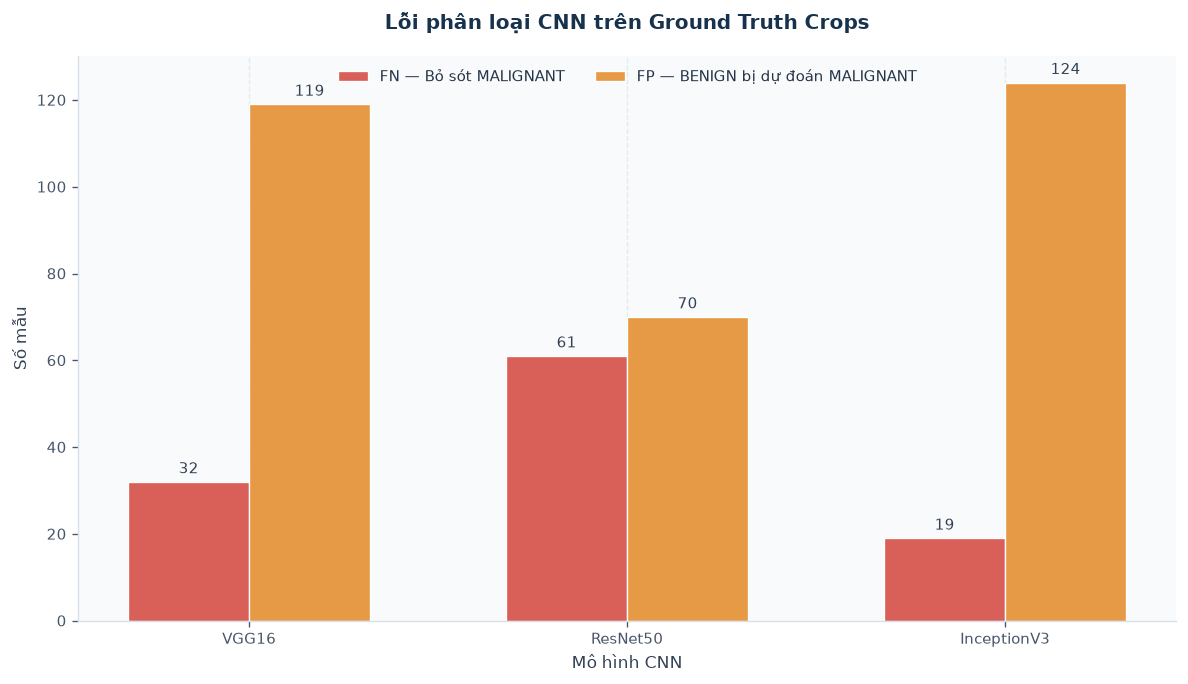

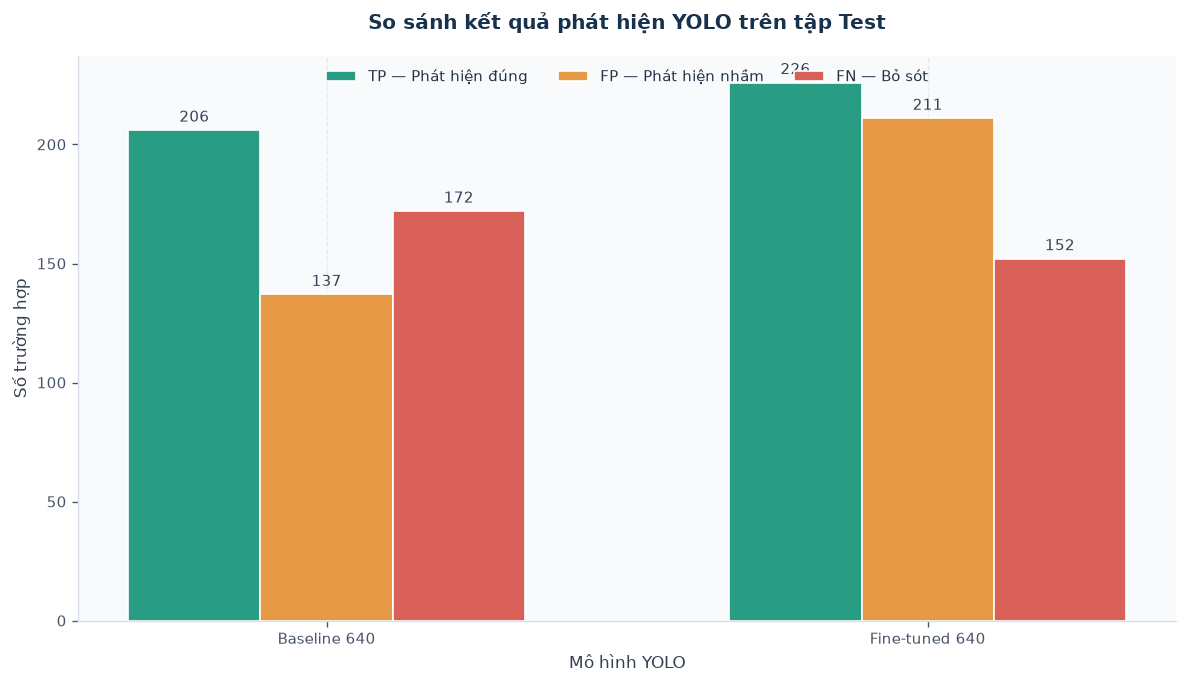

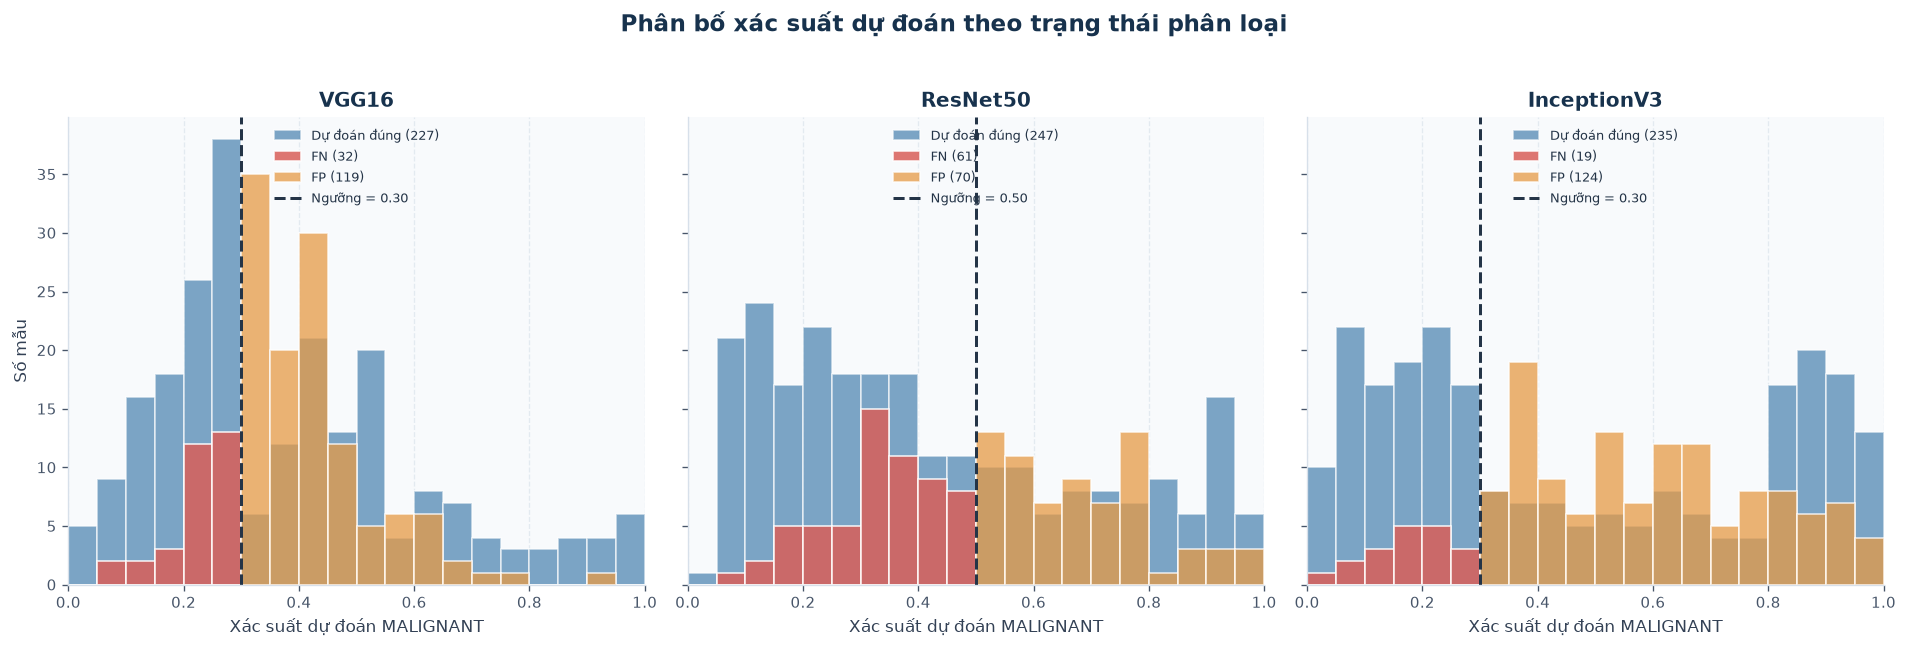

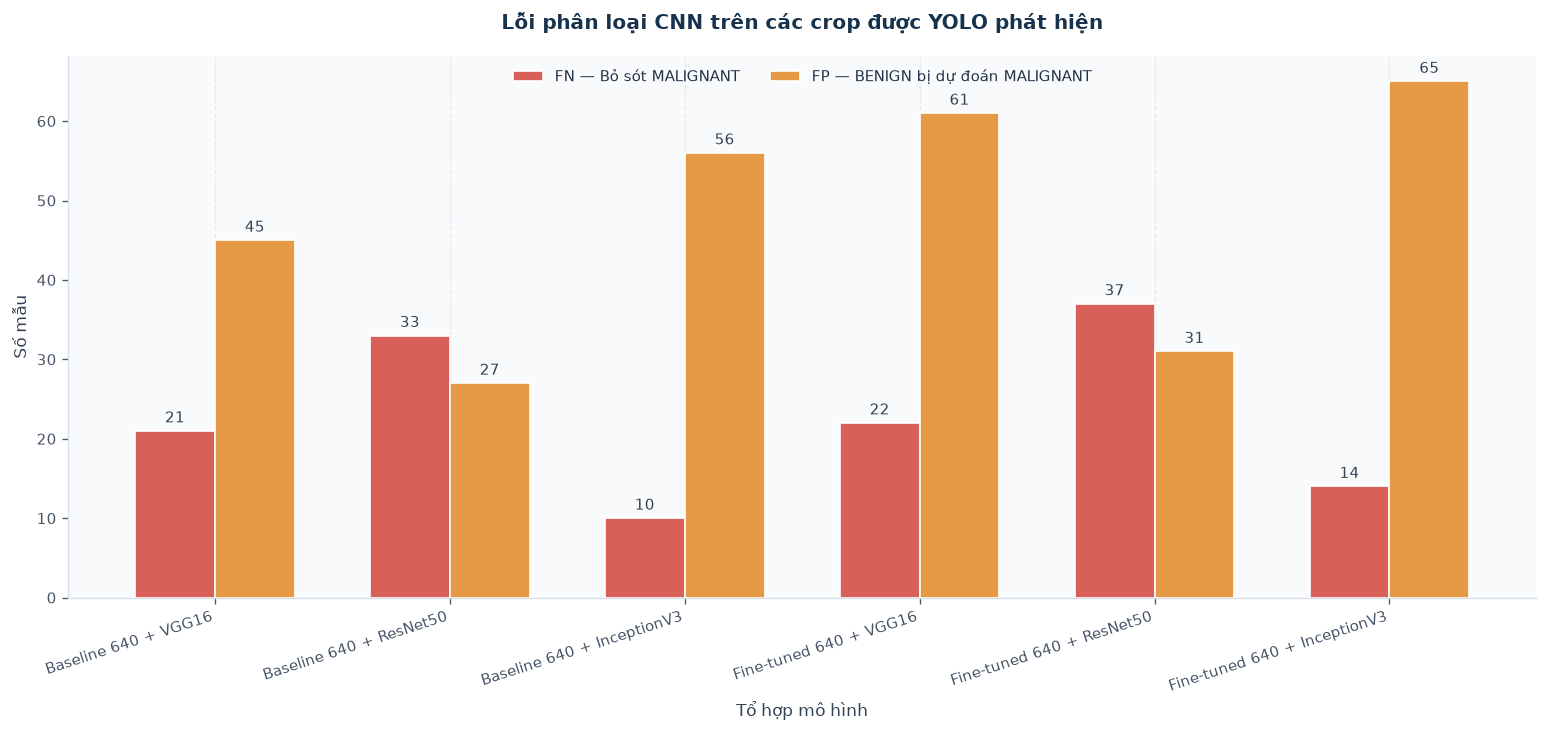

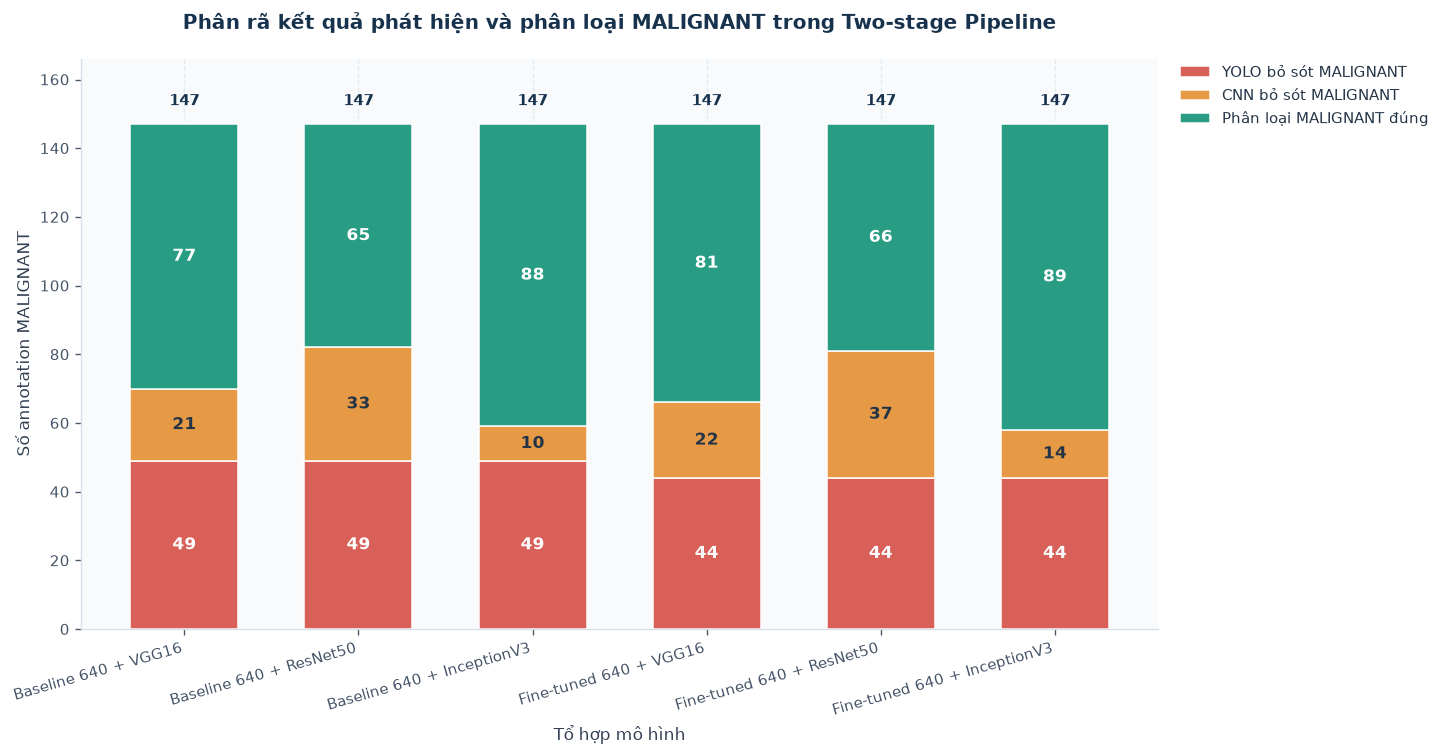

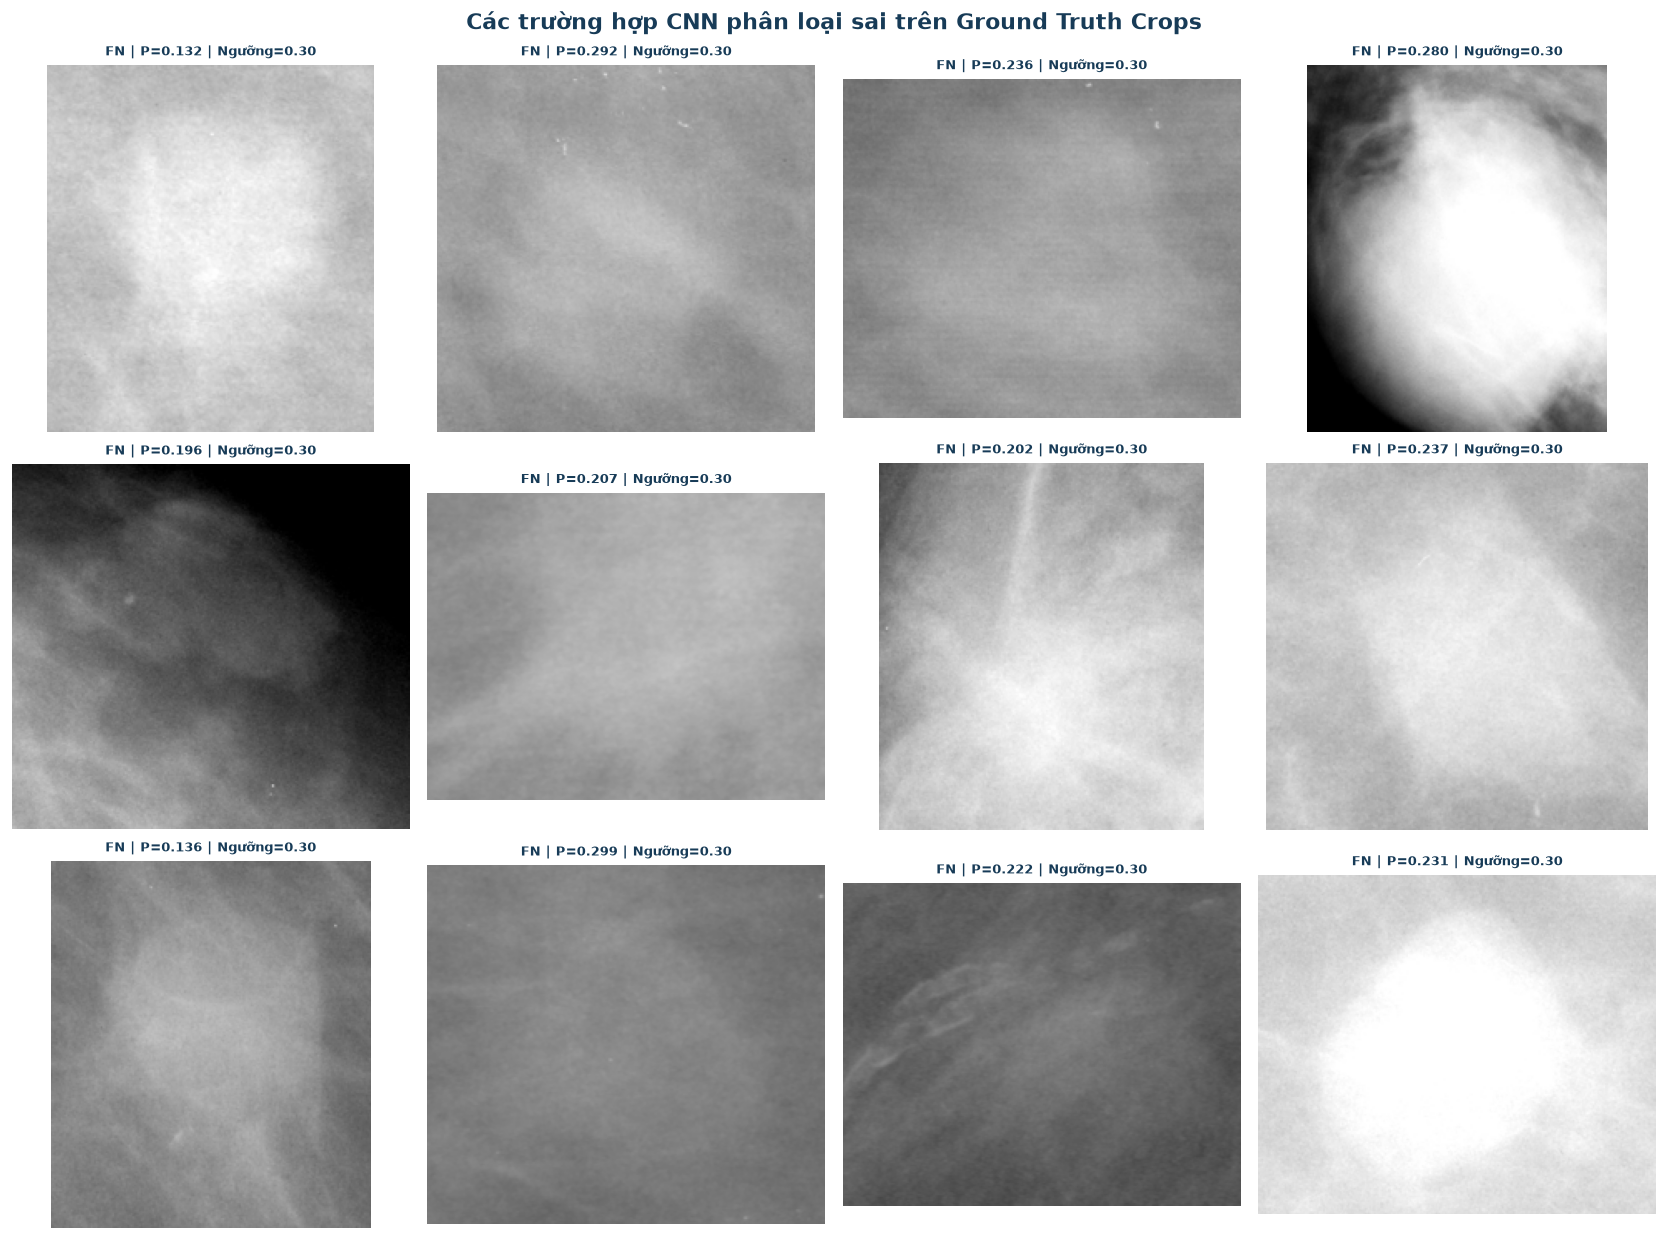

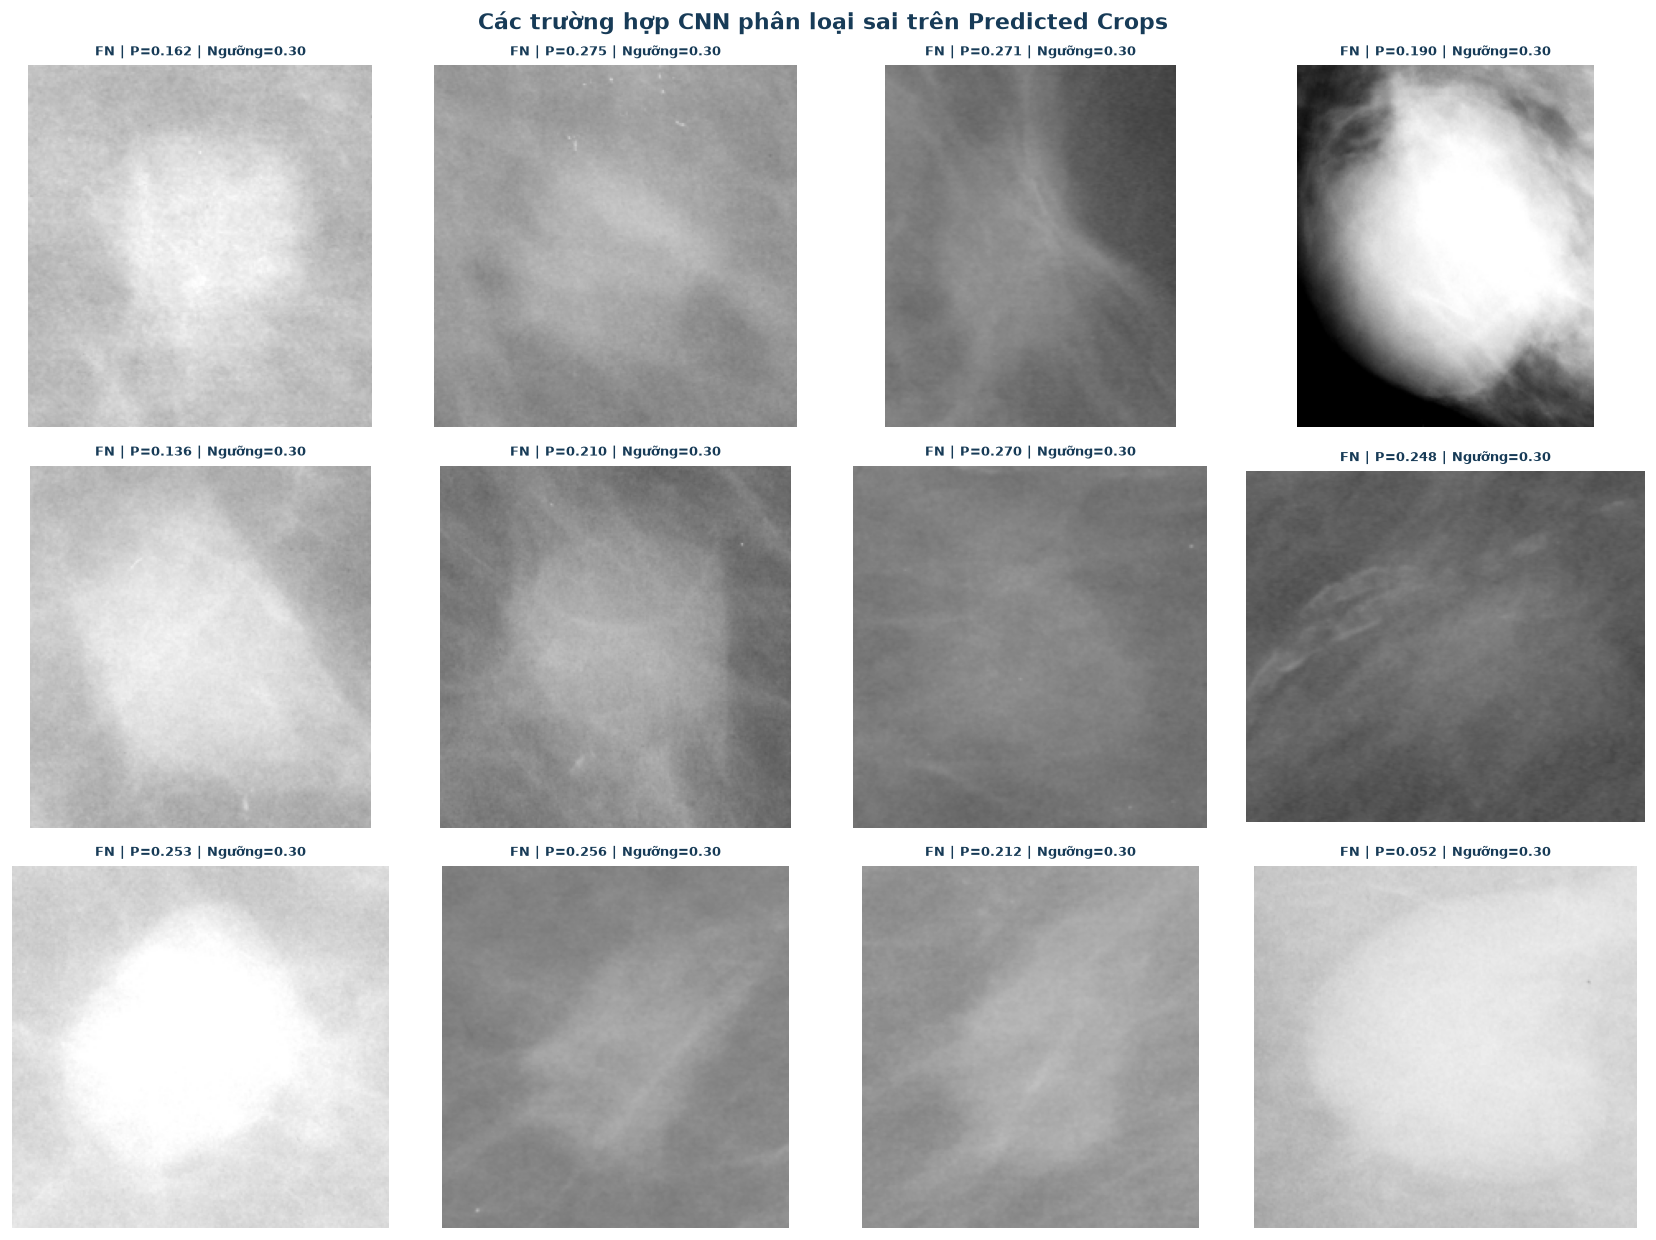

KIỂM TRA TỆP KẾT QUẢ


Tệp,Kết quả
nb09_8_cnn_gt_error_summary.csv,PASS
nb09_8_cnn_error_characteristics.csv,PASS
nb09_8_cnn_gt_error_details.csv,PASS
nb09_8_yolo_error_summary.csv,PASS
nb09_8_yolo_hard_images.csv,PASS
nb09_8_predicted_crop_error_summary.csv,PASS
nb09_8_predicted_crop_error_details.csv,PASS
nb09_8_two_stage_error_summary.csv,PASS
nb09_8_malignant_pipeline_breakdown.csv,PASS
nb09_8_integrity_report.csv,PASS


TỔNG KẾT 09.8


Nội dung,Kết quả
Số mô hình CNN,3
Số mô hình YOLO,2
Số trường hợp phát hiện YOLO,1104
Số crop dự đoán,432
Số tổ hợp Two-stage,6
Số lỗi CNN trên Ground Truth Crops,425
Số lỗi YOLO (FP + FN),672
Số lỗi CNN trên Predicted Crops,422
Kiểm tra toàn vẹn,14/14
Tệp kết quả,17/17


Thư mục kết quả: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb09_model_evaluation\nb09_8_error_analysis
Số lỗi CNN trên Ground Truth Crops: 425
Số lỗi YOLO (FP + FN): 672
Số lỗi CNN trên Predicted Crops: 422
Kiểm tra toàn vẹn: 14/14 PASS
Trạng thái: PASS


In [21]:
# 09.8 — PHÂN TÍCH LỖI VÀ CÁC TRƯỜNG HỢP DỰ ĐOÁN SAI

import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

# 1. CẤU HÌNH

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")
EVALUATION_ROOT = PROJECT_ROOT / "Data" / "processed" / "nb09_model_evaluation"

DIR_CNN_GT = EVALUATION_ROOT / "nb09_3_cnn_test_evaluation"
DIR_YOLO = EVALUATION_ROOT / "nb09_4_yolo_test_error_analysis"
DIR_PREDICTED_CROP = EVALUATION_ROOT / "nb09_6_cnn_predicted_crop_evaluation"
DIR_TWO_STAGE = EVALUATION_ROOT / "nb09_7_two_stage_pipeline_evaluation"

OUTPUT_DIR = EVALUATION_ROOT / "nb09_8_error_analysis"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_FILES = {
    "VGG16": "vgg16",
    "ResNet50": "resnet50",
    "InceptionV3": "inceptionv3"
}

YOLO_NAMES = {
    "YOLOv5n Baseline 640": "YOLOv5n_Baseline_640",
    "YOLOv5n Fine-tuned 640": "YOLOv5n_FineTuned_640"
}

YOLO_DISPLAY = {
    "YOLOv5n_Baseline_640": "Baseline 640",
    "YOLOv5n_FineTuned_640": "Fine-tuned 640"
}

CNN_COLORS = {
    "VGG16": "#3977A8",
    "ResNet50": "#249B8A",
    "InceptionV3": "#8064A2"
}

ERROR_COLORS = {
    "FN": "#D95F59",
    "FP": "#E69A45",
    "TP": "#299D83",
    "Correct": "#3977A8",
    "YOLO Missed": "#D95F59",
    "CNN Missed": "#E69A45",
    "Correct MALIGNANT": "#299D83"
}

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#F8FAFC",
    "axes.edgecolor": "#D7E0EA",
    "axes.labelcolor": "#334155",
    "axes.titlecolor": "#17324D",
    "xtick.color": "#475569",
    "ytick.color": "#475569",
    "text.color": "#243447",
    "grid.color": "#DCE5ED",
    "grid.alpha": 0.75,
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "legend.fontsize": 9,
    "savefig.facecolor": "white"
})

# 2. HÀM HỖ TRỢ

def read_csv_checked(path, required_columns=None):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"Không tìm thấy tệp: {path}")

    df = pd.read_csv(path)

    if required_columns:
        missing = [col for col in required_columns if col not in df.columns]
        if missing:
            raise ValueError(
                f"Tệp {path.name} thiếu cột bắt buộc: {missing}\n"
                f"Các cột hiện có: {df.columns.tolist()}"
            )
    return df


def save_csv(df, filename):
    path = OUTPUT_DIR / filename
    df.to_csv(path, index=False, encoding="utf-8-sig")
    return path


def json_safe(value):
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(v) for v in value]
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return None if not np.isfinite(value) else float(value)
    if isinstance(value, (np.bool_,)):
        return bool(value)
    if pd.isna(value):
        return None
    return value


def save_json(data, filename):
    path = OUTPUT_DIR / filename
    with open(path, "w", encoding="utf-8") as f:
        json.dump(json_safe(data), f, ensure_ascii=False, indent=2)
    return path


def style_table(df, percent_columns=None, decimal_columns=None):
    percent_columns = percent_columns or []
    decimal_columns = decimal_columns or []

    styler = (
        df.style
        .set_properties(**{
            "background-color": "#F7FAFC",
            "color": "#263746",
            "border-color": "#DCE5ED",
            "padding": "6px 9px",
            "text-align": "center"
        })
        .set_table_styles([
            {
                "selector": "th",
                "props": [
                    ("background-color", "#173B57"),
                    ("color", "white"),
                    ("font-weight", "bold"),
                    ("text-align", "center"),
                    ("padding", "8px")
                ]
            },
            {
                "selector": "td",
                "props": [("border", "1px solid #DCE5ED")]
            },
            {
                "selector": "tr:nth-child(even) td",
                "props": [("background-color", "#EAF2F7")]
            },
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "top"),
                    ("font-size", "14px"),
                    ("font-weight", "bold"),
                    ("color", "#173B57")
                ]
            }
        ])
        .hide(axis="index")
    )

    format_dict = {}
    for col in percent_columns:
        if col in df.columns:
            format_dict[col] = "{:.2%}"
    for col in decimal_columns:
        if col in df.columns:
            format_dict[col] = "{:.4f}"

    if format_dict:
        styler = styler.format(format_dict, na_rep="—")

    return styler


def finish_chart(fig, filename):
    fig.savefig(
        OUTPUT_DIR / filename,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )
    plt.show()
    plt.close(fig)


def normalize_binary_label(series):
    return pd.to_numeric(series, errors="coerce").astype("Int64")


def add_chart_labels(ax, containers, fmt="{:,.0f}", fontsize=9):
    for container in containers:
        ax.bar_label(
            container,
            fmt=fmt,
            padding=3,
            fontsize=fontsize,
            color="#334155"
        )


# 3. KIỂM TRA ĐẦU VÀO

required_directories = {
    "CNN Ground Truth": DIR_CNN_GT,
    "YOLO Error Analysis": DIR_YOLO,
    "CNN Predicted Crops": DIR_PREDICTED_CROP,
    "Two-stage Pipeline": DIR_TWO_STAGE
}

for name, folder in required_directories.items():
    if not folder.exists():
        raise FileNotFoundError(f"Không tìm thấy thư mục {name}: {folder}")

cnn_metrics = read_csv_checked(
    DIR_CNN_GT / "nb09_3_cnn_test_metrics.csv",
    [
        "model_name", "test_samples", "accuracy", "precision", "recall",
        "specificity", "f1_score", "roc_auc", "TN", "FP", "FN", "TP"
    ]
)

yolo_details = read_csv_checked(
    DIR_YOLO / "nb09_4_yolo_test_detection_details.csv",
    [
        "model", "image_id", "result", "confidence", "iou",
        "confidence_threshold", "iou_threshold"
    ]
)

yolo_summary = read_csv_checked(
    DIR_YOLO / "nb09_4_yolo_test_error_summary.csv",
    [
        "model", "images", "ground_truth", "predictions_after_threshold",
        "TP", "FP", "FN", "precision", "recall", "F1",
        "mean_matched_iou", "mean_TP_confidence", "mean_FP_confidence"
    ]
)

yolo_image_errors = read_csv_checked(
    DIR_YOLO / "nb09_4_yolo_test_image_level_errors.csv",
    [
        "model", "image_id", "ground_truth_count",
        "prediction_count_after_threshold", "TP", "FP", "FN"
    ]
)

predicted_crop_metrics = read_csv_checked(
    DIR_PREDICTED_CROP / "nb09_6_cnn_predicted_crop_metrics.csv",
    [
        "yolo_model", "cnn_model", "test_matched_crops",
        "accuracy", "precision", "recall", "specificity",
        "f1_score", "roc_auc", "TN", "FP", "FN", "TP"
    ]
)

predicted_crop_manifest = read_csv_checked(
    DIR_PREDICTED_CROP / "nb09_6_predicted_crop_manifest.csv",
    [
        "yolo_model", "annotation_id", "patient_id", "binary_pathology",
        "crop_path", "prediction_confidence", "matched_iou"
    ]
)

two_stage_source = read_csv_checked(
    DIR_TWO_STAGE / "nb09_7_two_stage_pipeline_summary.csv",
    [
        "YOLO", "CNN", "Detection TP", "Detection FP", "Detection FN",
        "Matched Crops", "CNN Accuracy", "CNN Precision", "CNN Recall",
        "CNN F1", "CNN AUC", "E2E Malignant TP",
        "E2E Malignant Total", "E2E Malignant Sensitivity"
    ]
)

cnn_gt_predictions = {}
predicted_crop_predictions = {}

for model_name, file_key in MODEL_FILES.items():
    cnn_gt_predictions[model_name] = read_csv_checked(
        DIR_CNN_GT / f"nb09_3_{file_key}_predictions.csv",
        [
            "annotation_id", "patient_id", "original_pathology",
            "binary_pathology", "crop_path", "true_label",
            "probability_malignant", "predicted_label",
            "threshold", "predicted_pathology", "is_correct"
        ]
    )

    cnn_gt_predictions[model_name]["true_label"] = normalize_binary_label(
        cnn_gt_predictions[model_name]["true_label"]
    )
    cnn_gt_predictions[model_name]["predicted_label"] = normalize_binary_label(
        cnn_gt_predictions[model_name]["predicted_label"]
    )
    cnn_gt_predictions[model_name]["model_name"] = model_name

    if len(cnn_gt_predictions[model_name]) != 378:
        raise ValueError(
            f"{model_name}: số mẫu Ground Truth không bằng 378."
        )

    if cnn_gt_predictions[model_name]["annotation_id"].duplicated().any():
        raise ValueError(
            f"{model_name}: annotation_id bị trùng trong Ground Truth predictions."
        )

    if not set(cnn_gt_predictions[model_name]["true_label"].dropna().unique()).issubset({0, 1}):
        raise ValueError(f"{model_name}: true_label không đúng quy ước nhị phân.")

    if not set(cnn_gt_predictions[model_name]["predicted_label"].dropna().unique()).issubset({0, 1}):
        raise ValueError(f"{model_name}: predicted_label không đúng quy ước nhị phân.")


for yolo_name, yolo_key in YOLO_NAMES.items():
    for model_name, file_key in MODEL_FILES.items():
        filename = (
            f"nb09_6_predictions_{yolo_key}_{model_name}.csv"
        )
        df = read_csv_checked(
            DIR_PREDICTED_CROP / filename,
            [
                "yolo_model", "annotation_id", "patient_id",
                "binary_pathology", "crop_path", "prediction_confidence",
                "matched_iou", "cnn_model", "cnn_threshold",
                "true_label", "malignant_probability",
                "predicted_label", "predicted_pathology",
                "classification_correct"
            ]
        )

        df["true_label"] = normalize_binary_label(df["true_label"])
        df["predicted_label"] = normalize_binary_label(df["predicted_label"])
        df["cnn_model"] = model_name

        if df["annotation_id"].duplicated().any():
            raise ValueError(
                f"{filename}: annotation_id bị trùng trong cùng tổ hợp."
            )

        predicted_crop_predictions[(yolo_key, model_name)] = df


# Đối chiếu số lượng mô hình và dữ liệu đầu vào

assert len(cnn_gt_predictions) == 3
assert len(yolo_summary) == 2
assert len(yolo_details) == 1104
assert len(predicted_crop_manifest) == 432
assert len(two_stage_source) == 6

input_check = pd.DataFrame([
    ["Số mô hình CNN", len(cnn_gt_predictions), "PASS"],
    ["Số mô hình YOLO", len(yolo_summary), "PASS"],
    ["Số trường hợp phát hiện YOLO", len(yolo_details), "PASS"],
    ["Số crop dự đoán", len(predicted_crop_manifest), "PASS"],
    ["Số tổ hợp Two-stage", len(two_stage_source), "PASS"]
], columns=["Kiểm tra", "Số lượng", "Kết quả"])

print("KIỂM TRA ĐẦU VÀO 09.8")
display(style_table(input_check))

# 4. PHÂN TÍCH LỖI CNN TRÊN GROUND TRUTH CROPS

cnn_error_rows = []
cnn_error_detail_frames = []

for model_name, df in cnn_gt_predictions.items():
    true_label = df["true_label"]
    predicted_label = df["predicted_label"]

    fn_mask = (true_label == 1) & (predicted_label == 0)
    fp_mask = (true_label == 0) & (predicted_label == 1)
    correct_mask = (true_label == predicted_label)

    fn_count = int(fn_mask.sum())
    fp_count = int(fp_mask.sum())
    correct_count = int(correct_mask.sum())
    total_samples = len(df)
    total_errors = fn_count + fp_count

    cnn_error_rows.append({
        "model_name": model_name,
        "Correct": correct_count,
        "FN - MALIGNANT bị dự đoán BENIGN": fn_count,
        "FP - BENIGN bị dự đoán MALIGNANT": fp_count,
        "Total Errors": total_errors,
        "Total Samples": total_samples,
        "Error Rate": total_errors / total_samples
    })

    for error_name, mask in [
        ("FN - MALIGNANT bị dự đoán BENIGN", fn_mask),
        ("FP - BENIGN bị dự đoán MALIGNANT", fp_mask)
    ]:
        error_df = df.loc[mask].copy()

        if error_df.empty:
            continue

        error_df["error_type"] = error_name
        error_df["error_code"] = "FN" if error_name.startswith("FN") else "FP"
        error_df["threshold_distance"] = np.where(
            error_df["error_code"].eq("FN"),
            error_df["threshold"] - error_df["probability_malignant"],
            error_df["probability_malignant"] - error_df["threshold"]
        )
        cnn_error_detail_frames.append(error_df)

cnn_error_summary = pd.DataFrame(cnn_error_rows)

cnn_error_details = (
    pd.concat(cnn_error_detail_frames, ignore_index=True)
    if cnn_error_detail_frames
    else pd.DataFrame()
)

cnn_error_characteristics = []

for (model_name, error_type), group in cnn_error_details.groupby(
    ["model_name", "error_type"]
):
    cnn_error_characteristics.append({
        "model_name": model_name,
        "error_type": error_type,
        "error_count": len(group),
        "mean_probability": group["probability_malignant"].mean(),
        "mean_threshold_distance": group["threshold_distance"].mean(),
        "unique_patients": group["patient_id"].nunique()
    })

cnn_error_characteristics = pd.DataFrame(cnn_error_characteristics)

print("KẾT QUẢ PHÂN TÍCH LỖI CNN TRÊN GROUND TRUTH CROPS")
display(style_table(
    cnn_error_summary,
    percent_columns=["Error Rate"]
))

print("ĐẶC ĐIỂM CÁC LỖI CNN")
display(style_table(
    cnn_error_characteristics,
    decimal_columns=["mean_probability", "mean_threshold_distance"]
))

# 5. PHÂN TÍCH LỖI YOLO

yolo_details["result"] = (
    yolo_details["result"].astype(str).str.upper().str.strip()
)

yolo_error_summary_rows = []

for model_name, group in yolo_details.groupby("model"):
    for result_type in ["FN", "FP", "TP"]:
        subset = group[group["result"] == result_type]

        yolo_error_summary_rows.append({
            "model": model_name,
            "result": result_type,
            "case_count": len(subset),
            "unique_images": subset["image_id"].nunique(),
            "mean_confidence": (
                subset["confidence"].mean()
                if subset["confidence"].notna().any()
                else np.nan
            ),
            "median_confidence": (
                subset["confidence"].median()
                if subset["confidence"].notna().any()
                else np.nan
            ),
            "mean_iou": (
                subset["iou"].mean()
                if subset["iou"].notna().any()
                else np.nan
            )
        })

yolo_error_summary = pd.DataFrame(yolo_error_summary_rows)

yolo_image_difficulty = (
    yolo_image_errors
    .groupby(["model", "image_id"], as_index=False)
    .agg({
        "ground_truth_count": "max",
        "prediction_count_after_threshold": "max",
        "TP": "max",
        "FP": "max",
        "FN": "max"
    })
)

yolo_image_difficulty["total_errors"] = (
    yolo_image_difficulty["FP"] + yolo_image_difficulty["FN"]
)

yolo_hard_images = (
    yolo_image_difficulty
    .sort_values(
        ["model", "total_errors", "FN", "FP"],
        ascending=[True, False, False, False]
    )
    .groupby("model")
    .head(15)
    .reset_index(drop=True)
)

print("KẾT QUẢ PHÂN TÍCH LỖI YOLO")
display(style_table(
    yolo_error_summary,
    decimal_columns=["mean_confidence", "median_confidence", "mean_iou"]
))

print("15 ẢNH CÓ NHIỀU LỖI NHẤT TRONG MỖI MÔ HÌNH YOLO")
display(style_table(yolo_hard_images))

# 6. PHÂN TÍCH LỖI CNN TRÊN PREDICTED CROPS

predicted_crop_error_rows = []
predicted_crop_error_details = []

for (yolo_key, model_name), df in predicted_crop_predictions.items():
    fn_mask = (df["true_label"] == 1) & (df["predicted_label"] == 0)
    fp_mask = (df["true_label"] == 0) & (df["predicted_label"] == 1)
    correct_mask = df["true_label"] == df["predicted_label"]

    predicted_crop_error_rows.append({
        "YOLO": yolo_key,
        "CNN": model_name,
        "Matched Crops": len(df),
        "Correct": int(correct_mask.sum()),
        "CNN False Negative": int(fn_mask.sum()),
        "CNN False Positive": int(fp_mask.sum()),
        "Total Errors": int(fn_mask.sum() + fp_mask.sum()),
        "Error Rate": float((fn_mask.sum() + fp_mask.sum()) / len(df))
    })

    for error_type, mask in [
        ("FN - MALIGNANT bị dự đoán BENIGN", fn_mask),
        ("FP - BENIGN bị dự đoán MALIGNANT", fp_mask)
    ]:
        subset = df.loc[mask].copy()
        if subset.empty:
            continue

        subset["error_type"] = error_type
        subset["error_code"] = "FN" if error_type.startswith("FN") else "FP"
        subset["YOLO"] = yolo_key
        predicted_crop_error_details.append(subset)

predicted_crop_error_summary = pd.DataFrame(predicted_crop_error_rows)

predicted_crop_error_detail = (
    pd.concat(predicted_crop_error_details, ignore_index=True)
    if predicted_crop_error_details
    else pd.DataFrame()
)

print("KẾT QUẢ LỖI CNN TRÊN PREDICTED CROPS")
display(style_table(
    predicted_crop_error_summary,
    percent_columns=["Error Rate"]
))

# 7. PHÂN TÍCH LỖI TOÀN BỘ TWO-STAGE PIPELINE

two_stage_rows = []
malignant_breakdown_rows = []
two_stage_integrity_rows = []

for _, pipeline_row in two_stage_source.iterrows():
    yolo_key = str(pipeline_row["YOLO"])
    model_name = str(pipeline_row["CNN"])

    if yolo_key not in YOLO_DISPLAY:
        raise ValueError(f"Không nhận diện được tên YOLO: {yolo_key}")

    if model_name not in MODEL_FILES:
        raise ValueError(f"Không nhận diện được tên CNN: {model_name}")

    prediction_df = predicted_crop_predictions[(yolo_key, model_name)]
    gt_df = cnn_gt_predictions[model_name]

    malignant_gt = gt_df[gt_df["true_label"] == 1].copy()
    benign_gt = gt_df[gt_df["true_label"] == 0].copy()

    if malignant_gt["annotation_id"].duplicated().any():
        raise ValueError(f"{model_name}: annotation MALIGNANT bị trùng.")

    if prediction_df["annotation_id"].duplicated().any():
        raise ValueError(f"{yolo_key} + {model_name}: annotation bị trùng.")

    matched_ids = set(prediction_df["annotation_id"].astype(str))
    malignant_ids = set(malignant_gt["annotation_id"].astype(str))
    benign_ids = set(benign_gt["annotation_id"].astype(str))

    prediction_ids = set(prediction_df["annotation_id"].astype(str))

    matched_malignant = prediction_df[
        prediction_df["true_label"] == 1
    ]
    matched_benign = prediction_df[
        prediction_df["true_label"] == 0
    ]

    missed_malignant_by_yolo = len(malignant_ids - matched_ids)

    malignant_cnn_fn = int(
        (
            (matched_malignant["true_label"] == 1)
            & (matched_malignant["predicted_label"] == 0)
        ).sum()
    )

    malignant_correct = int(
        (
            (matched_malignant["true_label"] == 1)
            & (matched_malignant["predicted_label"] == 1)
        ).sum()
    )

    benign_cnn_fp = int(
        (
            (matched_benign["true_label"] == 0)
            & (matched_benign["predicted_label"] == 1)
        ).sum()
    )

    benign_matched = len(matched_benign)
    malignant_matched = len(matched_malignant)

    detection_fp = int(pipeline_row["Detection FP"])
    detection_fn = int(pipeline_row["Detection FN"])
    detection_tp = int(pipeline_row["Detection TP"])

    malignant_total = len(malignant_gt)

    if malignant_correct + malignant_cnn_fn + missed_malignant_by_yolo != malignant_total:
        raise ValueError(
            f"Không khớp tổng MALIGNANT: {yolo_key} + {model_name}. "
            f"Đúng={malignant_correct}, CNN FN={malignant_cnn_fn}, "
            f"YOLO FN={missed_malignant_by_yolo}, Tổng={malignant_total}."
        )

    if len(prediction_df) != detection_tp:
        raise ValueError(
            f"Số predicted crops không khớp Detection TP: {yolo_key} + {model_name}."
        )

    two_stage_rows.append({
        "YOLO": yolo_key,
        "CNN": model_name,
        "Detection TP": detection_tp,
        "Detection FP": detection_fp,
        "Detection FN": detection_fn,
        "Matched Crops": len(prediction_df),
        "CNN Misclassified": int(
            (prediction_df["true_label"] != prediction_df["predicted_label"]).sum()
        ),
        "CNN False Negative": malignant_cnn_fn,
        "CNN False Positive": benign_cnn_fp,
        "End-to-end YOLO Missed MALIGNANT": missed_malignant_by_yolo,
        "End-to-end CNN Missed MALIGNANT": malignant_cnn_fn,
        "End-to-end MALIGNANT TP": malignant_correct,
        "End-to-end MALIGNANT Total": malignant_total,
        "End-to-end MALIGNANT Sensitivity": malignant_correct / malignant_total
    })

    malignant_breakdown_rows.append({
        "pipeline_result": "Phân rã kết quả MALIGNANT",
        "YOLO": yolo_key,
        "CNN": model_name,
        "FN - CNN dự đoán BENIGN": malignant_cnn_fn,
        "FN - YOLO không phát hiện": missed_malignant_by_yolo,
        "TP - Phân loại MALIGNANT đúng": malignant_correct,
        "Tổng MALIGNANT": malignant_total
    })

    two_stage_integrity_rows.append({
        "Kiểm tra": f"MALIGNANT E2E - {yolo_key} - {model_name}",
        "Kết quả": "PASS",
        "Chi tiết": (
            f"{malignant_correct} TP + {malignant_cnn_fn} CNN FN + "
            f"{missed_malignant_by_yolo} YOLO FN = {malignant_total}"
        )
    })

two_stage_error_summary = pd.DataFrame(two_stage_rows)
malignant_breakdown = pd.DataFrame(malignant_breakdown_rows)

print("TỔNG HỢP LỖI TWO-STAGE PIPELINE")
display(style_table(
    two_stage_error_summary,
    percent_columns=["End-to-end MALIGNANT Sensitivity"]
))

print("PHÂN RÃ KẾT QUẢ MALIGNANT TRONG TOÀN BỘ PIPELINE")
display(style_table(malignant_breakdown))

# 8. TẠO BÁO CÁO TÍNH NHẤT QUÁN

integrity_rows = []

for model_name, df in cnn_gt_predictions.items():
    integrity_rows.append({
        "Kiểm tra": f"Số lượng mẫu CNN Ground Truth - {model_name}",
        "Kết quả": "PASS" if len(df) == 378 else "FAIL",
        "Chi tiết": f"{len(df)} mẫu"
    })

    malignant_count = int((df["true_label"] == 1).sum())
    integrity_rows.append({
        "Kiểm tra": f"Số lượng MALIGNANT - {model_name}",
        "Kết quả": "PASS" if malignant_count == 147 else "FAIL",
        "Chi tiết": f"{malignant_count} annotation MALIGNANT"
    })

for _, row in yolo_summary.iterrows():
    total_predictions = int(row["TP"] + row["FP"])
    total_gt = int(row["TP"] + row["FN"])

    integrity_rows.append({
        "Kiểm tra": f"Đối chiếu số lượng YOLO - {row['model']}",
        "Kết quả": "PASS" if (
            total_predictions == int(row["predictions_after_threshold"])
            and total_gt == int(row["ground_truth"])
        ) else "FAIL",
        "Chi tiết": f"TP={int(row['TP'])}, FP={int(row['FP'])}, FN={int(row['FN'])}"
    })

integrity_rows.extend(two_stage_integrity_rows)

integrity_report = pd.DataFrame(integrity_rows)

# 9. BIỂU ĐỒ 1 — LỖI CNN TRÊN GROUND TRUTH CROPS

plot_df = cnn_error_summary.set_index("model_name").reindex(
    ["VGG16", "ResNet50", "InceptionV3"]
)

fig, ax = plt.subplots(figsize=(10, 5.8))

x = np.arange(len(plot_df))
width = 0.32

bars_fn = ax.bar(
    x - width / 2,
    plot_df["FN - MALIGNANT bị dự đoán BENIGN"],
    width,
    label="FN — Bỏ sót MALIGNANT",
    color=ERROR_COLORS["FN"],
    edgecolor="white",
    linewidth=0.8
)

bars_fp = ax.bar(
    x + width / 2,
    plot_df["FP - BENIGN bị dự đoán MALIGNANT"],
    width,
    label="FP — BENIGN bị dự đoán MALIGNANT",
    color=ERROR_COLORS["FP"],
    edgecolor="white",
    linewidth=0.8
)

ax.set_title("Lỗi phân loại CNN trên Ground Truth Crops", pad=16)
ax.set_ylabel("Số mẫu")
ax.set_xlabel("Mô hình CNN")
ax.set_xticks(x)
ax.set_xticklabels(plot_df.index)
ax.grid(axis="y")
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, 1.0))
add_chart_labels(ax, [bars_fn, bars_fp])

fig.tight_layout()
finish_chart(fig, "nb09_8_figure_01_cnn_gt_errors.png")

# 10. BIỂU ĐỒ 2 — TP, FP, FN CỦA YOLO

yolo_plot = yolo_summary.copy()
yolo_plot["model_short"] = yolo_plot["model"].map({
    "YOLOv5n Baseline 640": "Baseline 640",
    "YOLOv5n Fine-tuned 640": "Fine-tuned 640"
})
yolo_plot = yolo_plot.set_index("model_short").reindex(
    ["Baseline 640", "Fine-tuned 640"]
)

fig, ax = plt.subplots(figsize=(10, 5.8))

x = np.arange(len(yolo_plot))
width = 0.22

bars_tp = ax.bar(
    x - width,
    yolo_plot["TP"],
    width,
    label="TP — Phát hiện đúng",
    color=ERROR_COLORS["TP"],
    edgecolor="white"
)

bars_fp = ax.bar(
    x,
    yolo_plot["FP"],
    width,
    label="FP — Phát hiện nhầm",
    color=ERROR_COLORS["FP"],
    edgecolor="white"
)

bars_fn = ax.bar(
    x + width,
    yolo_plot["FN"],
    width,
    label="FN — Bỏ sót",
    color=ERROR_COLORS["FN"],
    edgecolor="white"
)

ax.set_title("So sánh kết quả phát hiện YOLO trên tập Test", pad=16)
ax.set_ylabel("Số trường hợp")
ax.set_xlabel("Mô hình YOLO")
ax.set_xticks(x)
ax.set_xticklabels(yolo_plot.index)
ax.grid(axis="y")
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.0))
add_chart_labels(ax, [bars_tp, bars_fp, bars_fn])

fig.tight_layout()
finish_chart(fig, "nb09_8_figure_02_yolo_detection_errors.png")

# 11. BIỂU ĐỒ 3 — PHÂN BỐ XÁC SUẤT DỰ ĐOÁN CNN

fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), sharey=True)

for ax, model_name in zip(axes, ["VGG16", "ResNet50", "InceptionV3"]):
    df = cnn_gt_predictions[model_name].copy()

    threshold = float(df["threshold"].iloc[0])

    correct = df[df["true_label"] == df["predicted_label"]]
    fn = df[(df["true_label"] == 1) & (df["predicted_label"] == 0)]
    fp = df[(df["true_label"] == 0) & (df["predicted_label"] == 1)]

    bins = np.linspace(0, 1, 21)

    ax.hist(
        correct["probability_malignant"].dropna(),
        bins=bins,
        alpha=0.65,
        color=ERROR_COLORS["Correct"],
        label=f"Dự đoán đúng ({len(correct)})",
        edgecolor="white"
    )

    ax.hist(
        fn["probability_malignant"].dropna(),
        bins=bins,
        alpha=0.85,
        color=ERROR_COLORS["FN"],
        label=f"FN ({len(fn)})",
        edgecolor="white"
    )

    ax.hist(
        fp["probability_malignant"].dropna(),
        bins=bins,
        alpha=0.75,
        color=ERROR_COLORS["FP"],
        label=f"FP ({len(fp)})",
        edgecolor="white"
    )

    ax.axvline(
        threshold,
        color="#243447",
        linestyle="--",
        linewidth=1.8,
        label=f"Ngưỡng = {threshold:.2f}"
    )

    ax.set_title(model_name)
    ax.set_xlabel("Xác suất dự đoán MALIGNANT")
    ax.set_xlim(0, 1)
    ax.grid(axis="y")
    ax.set_axisbelow(True)
    ax.legend(frameon=False, fontsize=8, loc="upper center")

axes[0].set_ylabel("Số mẫu")
fig.suptitle(
    "Phân bố xác suất dự đoán theo trạng thái phân loại",
    fontsize=14,
    fontweight="bold",
    color="#17324D",
    y=1.03
)
fig.tight_layout()
finish_chart(fig, "nb09_8_figure_03_cnn_probability_distribution.png")

# 12. BIỂU ĐỒ 4 — LỖI CNN TRÊN PREDICTED CROPS

plot_predicted = predicted_crop_error_summary.copy()
plot_predicted["pipeline"] = (
    plot_predicted["YOLO"].map(YOLO_DISPLAY)
    + " + "
    + plot_predicted["CNN"]
)

pipeline_order = [
    "Baseline 640 + VGG16",
    "Baseline 640 + ResNet50",
    "Baseline 640 + InceptionV3",
    "Fine-tuned 640 + VGG16",
    "Fine-tuned 640 + ResNet50",
    "Fine-tuned 640 + InceptionV3"
]

plot_predicted = plot_predicted.set_index("pipeline").reindex(pipeline_order)

fig, ax = plt.subplots(figsize=(13, 6.2))

x = np.arange(len(plot_predicted))
width = 0.34

bars_fn = ax.bar(
    x - width / 2,
    plot_predicted["CNN False Negative"],
    width,
    label="FN — Bỏ sót MALIGNANT",
    color=ERROR_COLORS["FN"],
    edgecolor="white"
)

bars_fp = ax.bar(
    x + width / 2,
    plot_predicted["CNN False Positive"],
    width,
    label="FP — BENIGN bị dự đoán MALIGNANT",
    color=ERROR_COLORS["FP"],
    edgecolor="white"
)

ax.set_title("Lỗi phân loại CNN trên các crop được YOLO phát hiện", pad=16)
ax.set_ylabel("Số mẫu")
ax.set_xlabel("Tổ hợp mô hình")
ax.set_xticks(x)
ax.set_xticklabels(plot_predicted.index, rotation=18, ha="right")
ax.grid(axis="y")
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, 1.0))
add_chart_labels(ax, [bars_fn, bars_fp])

fig.tight_layout()
finish_chart(fig, "nb09_8_figure_04_predicted_crop_errors.png")

# 13. BIỂU ĐỒ 5 — PHÂN RÃ KẾT QUẢ MALIGNANT TOÀN PIPELINE

pipeline_plot = malignant_breakdown.copy()
pipeline_plot["pipeline"] = (
    pipeline_plot["YOLO"].map(YOLO_DISPLAY)
    + " + "
    + pipeline_plot["CNN"]
)

pipeline_plot = pipeline_plot.set_index("pipeline").reindex(pipeline_order)

fig, ax = plt.subplots(figsize=(13, 7.2))

x = np.arange(len(pipeline_plot))
bar_width = 0.62

yolo_missed = pipeline_plot["FN - YOLO không phát hiện"].to_numpy()
cnn_missed = pipeline_plot["FN - CNN dự đoán BENIGN"].to_numpy()
malignant_tp = pipeline_plot["TP - Phân loại MALIGNANT đúng"].to_numpy()

bars_yolo = ax.bar(
    x,
    yolo_missed,
    bar_width,
    label="YOLO bỏ sót MALIGNANT",
    color=ERROR_COLORS["YOLO Missed"],
    edgecolor="white",
    linewidth=0.9
)

bars_cnn = ax.bar(
    x,
    cnn_missed,
    bar_width,
    bottom=yolo_missed,
    label="CNN bỏ sót MALIGNANT",
    color=ERROR_COLORS["CNN Missed"],
    edgecolor="white",
    linewidth=0.9
)

bars_tp = ax.bar(
    x,
    malignant_tp,
    bar_width,
    bottom=yolo_missed + cnn_missed,
    label="Phân loại MALIGNANT đúng",
    color=ERROR_COLORS["Correct MALIGNANT"],
    edgecolor="white",
    linewidth=0.9
)

# Ghi số liệu trực tiếp trong từng phần của cột
for i in range(len(pipeline_plot)):
    if yolo_missed[i] > 0:
        ax.text(
            x[i],
            yolo_missed[i] / 2,
            f"{yolo_missed[i]}",
            ha="center",
            va="center",
            color="white",
            fontsize=10,
            fontweight="bold"
        )

    if cnn_missed[i] > 0:
        ax.text(
            x[i],
            yolo_missed[i] + cnn_missed[i] / 2,
            f"{cnn_missed[i]}",
            ha="center",
            va="center",
            color="#243447",
            fontsize=10,
            fontweight="bold"
        )

    ax.text(
        x[i],
        yolo_missed[i] + cnn_missed[i] + malignant_tp[i] / 2,
        f"{malignant_tp[i]}",
        ha="center",
        va="center",
        color="white",
        fontsize=10,
        fontweight="bold"
    )

    ax.text(
        x[i],
        151.5,
        "147",
        ha="center",
        va="bottom",
        color="#17324D",
        fontsize=9,
        fontweight="bold"
    )

ax.set_title(
    "Phân rã kết quả phát hiện và phân loại MALIGNANT trong Two-stage Pipeline",
    pad=18
)
ax.set_ylabel("Số annotation MALIGNANT")
ax.set_xlabel("Tổ hợp mô hình")
ax.set_xticks(x)
ax.set_xticklabels(pipeline_plot.index, rotation=16, ha="right")
ax.set_ylim(0, 166)
ax.set_yticks(np.arange(0, 161, 20))
ax.grid(axis="y")
ax.set_axisbelow(True)

# Đưa chú thích ra ngoài vùng biểu đồ để không che cột
ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.015, 1.0),
    frameon=False,
    fontsize=9,
    borderaxespad=0
)

fig.subplots_adjust(
    left=0.08,
    right=0.77,
    bottom=0.22,
    top=0.88
)

finish_chart(fig, "nb09_8_figure_05_two_stage_malignant_breakdown.png")

# 14. LƯU CÁC BẢNG KẾT QUẢ

save_csv(input_check, "nb09_8_input_integrity.csv")

save_csv(cnn_error_summary, "nb09_8_cnn_gt_error_summary.csv")
save_csv(cnn_error_characteristics, "nb09_8_cnn_error_characteristics.csv")
save_csv(cnn_error_details, "nb09_8_cnn_gt_error_details.csv")

save_csv(yolo_error_summary, "nb09_8_yolo_error_summary.csv")
save_csv(yolo_hard_images, "nb09_8_yolo_hard_images.csv")
save_csv(yolo_details, "nb09_8_yolo_detection_error_details.csv")

save_csv(
    predicted_crop_error_summary,
    "nb09_8_predicted_crop_error_summary.csv"
)
save_csv(
    predicted_crop_error_detail,
    "nb09_8_predicted_crop_error_details.csv"
)

save_csv(two_stage_error_summary, "nb09_8_two_stage_error_summary.csv")
save_csv(malignant_breakdown, "nb09_8_malignant_pipeline_breakdown.csv")
save_csv(integrity_report, "nb09_8_integrity_report.csv")

# 15. TẠO MONTAGE CÁC CROP PHÂN LOẠI SAI

def make_error_montage(df, title, filename, max_images=12):
    if df.empty or "crop_path" not in df.columns:
        return {
            "title": title,
            "saved": False,
            "reason": "Không có dữ liệu crop phù hợp."
        }

    candidates = df.copy()
    candidates = candidates.drop_duplicates(subset=["crop_path"])
    candidates = candidates.head(max_images)

    loaded_images = []
    skipped = 0

    for _, row in candidates.iterrows():
        image_path = Path(str(row["crop_path"]))

        if not image_path.exists():
            skipped += 1
            continue

        try:
            image = Image.open(image_path).convert("RGB")
            image = ImageOps.contain(image, (260, 220))

            if "error_code" in row:
                error_label = str(row["error_code"])
            else:
                error_label = "Lỗi"

            probability = row.get(
                "probability_malignant",
                row.get("malignant_probability", np.nan)
            )

            threshold = row.get(
                "threshold",
                row.get("cnn_threshold", np.nan)
            )

            caption = (
                f"{error_label} | "
                f"P={probability:.3f} | "
                f"Ngưỡng={threshold:.2f}"
                if pd.notna(probability) and pd.notna(threshold)
                else error_label
            )

            loaded_images.append((image.copy(), caption))
            image.close()

        except Exception:
            skipped += 1

    if not loaded_images:
        return {
            "title": title,
            "saved": False,
            "reason": "Không đọc được crop nào.",
            "skipped": skipped
        }

    ncols = 4
    nrows = int(np.ceil(len(loaded_images) / ncols))

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(14, 3.5 * nrows)
    )
    axes = np.array(axes).reshape(-1)

    for ax in axes:
        ax.axis("off")

    for ax, (image, caption) in zip(axes, loaded_images):
        ax.imshow(image)
        ax.set_title(caption, fontsize=8, color="#173B57")
        ax.axis("off")

    fig.suptitle(
        title,
        fontsize=13,
        fontweight="bold",
        color="#173B57"
    )
    fig.tight_layout()
    finish_chart(fig, filename)

    return {
        "title": title,
        "saved": True,
        "images_displayed": len(loaded_images),
        "images_skipped": skipped
    }


montage_results = []

montage_results.append(
    make_error_montage(
        cnn_error_details,
        "Các trường hợp CNN phân loại sai trên Ground Truth Crops",
        "nb09_8_figure_06_cnn_gt_error_examples.png"
    )
)

montage_results.append(
    make_error_montage(
        predicted_crop_error_detail,
        "Các trường hợp CNN phân loại sai trên Predicted Crops",
        "nb09_8_figure_07_predicted_crop_error_examples.png"
    )
)

# 16. TỔNG HỢP VÀ KIỂM TRA CUỐI

total_cnn_gt_errors = int(cnn_error_summary["Total Errors"].sum())
total_yolo_fp_fn = int(
    yolo_error_summary[
        yolo_error_summary["result"].isin(["FP", "FN"])
    ]["case_count"].sum()
)
total_predicted_crop_errors = int(
    predicted_crop_error_summary["Total Errors"].sum()
)

integrity_pass = int(
    (integrity_report["Kết quả"] == "PASS").sum()
)
integrity_total = len(integrity_report)

summary = {
    "notebook_section": "09.8",
    "section_name": "Phân tích lỗi và các trường hợp dự đoán sai",
    "input": {
        "cnn_models": len(cnn_gt_predictions),
        "yolo_models": len(yolo_summary),
        "yolo_detection_cases": len(yolo_details),
        "predicted_crops": len(predicted_crop_manifest),
        "two_stage_combinations": len(two_stage_source)
    },
    "cnn_ground_truth": {
        "total_errors": total_cnn_gt_errors,
        "models": cnn_error_summary.to_dict(orient="records")
    },
    "yolo_detection": {
        "false_positive_and_false_negative": total_yolo_fp_fn,
        "summary": yolo_error_summary.to_dict(orient="records")
    },
    "cnn_predicted_crops": {
        "total_errors": total_predicted_crop_errors,
        "summary": predicted_crop_error_summary.to_dict(orient="records")
    },
    "two_stage_pipeline": {
        "summary": two_stage_error_summary.to_dict(orient="records"),
        "malignant_breakdown": malignant_breakdown.to_dict(orient="records")
    },
    "integrity": {
        "passed": integrity_pass,
        "total": integrity_total,
        "status": "PASS" if integrity_pass == integrity_total else "FAIL"
    },
    "montage": montage_results
}

save_json(summary, "nb09_8_summary.json")

# Tạo danh sách tệp kết quả và sắp xếp theo tên tệp

inventory_files = sorted(
    [
        {
            "file_name": path.name,
            "file_size_bytes": path.stat().st_size,
            "file_type": path.suffix.lower()
        }
        for path in OUTPUT_DIR.iterdir()
        if path.is_file() and path.name != "nb09_8_inventory.json"
    ],
    key=lambda item: item["file_name"].lower()
)

inventory = {
    "output_directory": str(OUTPUT_DIR),
    "file_count": len(inventory_files) + 1,
    "files": inventory_files
}

save_json(inventory, "nb09_8_inventory.json")

# Kiểm tra các tệp kết quả

expected_outputs = [
    "nb09_8_cnn_gt_error_summary.csv",
    "nb09_8_cnn_error_characteristics.csv",
    "nb09_8_cnn_gt_error_details.csv",
    "nb09_8_yolo_error_summary.csv",
    "nb09_8_yolo_hard_images.csv",
    "nb09_8_predicted_crop_error_summary.csv",
    "nb09_8_predicted_crop_error_details.csv",
    "nb09_8_two_stage_error_summary.csv",
    "nb09_8_malignant_pipeline_breakdown.csv",
    "nb09_8_integrity_report.csv",
    "nb09_8_figure_01_cnn_gt_errors.png",
    "nb09_8_figure_02_yolo_detection_errors.png",
    "nb09_8_figure_03_cnn_probability_distribution.png",
    "nb09_8_figure_04_predicted_crop_errors.png",
    "nb09_8_figure_05_two_stage_malignant_breakdown.png",
    "nb09_8_summary.json",
    "nb09_8_inventory.json"
]

export_checks = []

for filename in expected_outputs:
    file_path = OUTPUT_DIR / filename
    export_checks.append({
        "Tệp": filename,
        "Kết quả": (
            "PASS"
            if file_path.exists() and file_path.stat().st_size > 0
            else "FAIL"
        )
    })

export_check_df = pd.DataFrame(export_checks)

all_integrity_pass = (
    integrity_pass == integrity_total
    and (export_check_df["Kết quả"] == "PASS").all()
)

print("KIỂM TRA TỆP KẾT QUẢ")
display(style_table(export_check_df))

print("TỔNG KẾT 09.8")

final_summary = pd.DataFrame([
    ["Số mô hình CNN", len(cnn_gt_predictions)],
    ["Số mô hình YOLO", len(yolo_summary)],
    ["Số trường hợp phát hiện YOLO", len(yolo_details)],
    ["Số crop dự đoán", len(predicted_crop_manifest)],
    ["Số tổ hợp Two-stage", len(two_stage_source)],
    ["Số lỗi CNN trên Ground Truth Crops", total_cnn_gt_errors],
    ["Số lỗi YOLO (FP + FN)", total_yolo_fp_fn],
    ["Số lỗi CNN trên Predicted Crops", total_predicted_crop_errors],
    ["Kiểm tra toàn vẹn", f"{integrity_pass}/{integrity_total}"],
    ["Tệp kết quả", f"{(export_check_df['Kết quả'] == 'PASS').sum()}/{len(export_check_df)}"],
    ["Trạng thái", "PASS" if all_integrity_pass else "FAIL"]
], columns=["Nội dung", "Kết quả"])

display(style_table(final_summary))

print(f"Thư mục kết quả: {OUTPUT_DIR}")
print(f"Số lỗi CNN trên Ground Truth Crops: {total_cnn_gt_errors}")
print(f"Số lỗi YOLO (FP + FN): {total_yolo_fp_fn}")
print(f"Số lỗi CNN trên Predicted Crops: {total_predicted_crop_errors}")
print(f"Kiểm tra toàn vẹn: {integrity_pass}/{integrity_total} PASS")
print(f"Trạng thái: {'PASS' if all_integrity_pass else 'FAIL'}")

### TỔNG KẾT NOTEBOOK 09 — ĐÁNH GIÁ MÔ HÌNH VÀ PHÂN TÍCH LỖI

**Trạng thái:** HOÀN THÀNH (Kiểm định toàn vẹn dữ liệu & kết quả: **PASS**).

---

## 1. Mục tiêu và Phạm vi đánh giá

Notebook 09 thực hiện đánh giá độc lập các mô hình đã huấn luyện từ Notebook 08 trên tập **Test** của bộ dữ liệu CBIS-DDSM (**361 ảnh**, **378 annotations**, **201 bệnh nhân**, gồm **231 BENIGN** và **147 MALIGNANT**). Toàn bộ siêu tham số và ngưỡng quyết định đều được khóa cố định từ tập Validation trước khi đánh giá.

* **Nhóm mô hình phát hiện & định vị (Stage 1 — YOLOv5n):**
  * `YOLOv5n Baseline` ($640 \times 640$)
  * `YOLOv5n Full Image` ($1024 \times 1024$)
  * `YOLOv5n Fine-tuned` ($640 \times 640$)
* **Nhóm mô hình phân loại lành/ác tính (Stage 2 — CNN):**
  * `VGG16` (ngưỡng `0,30`), `ResNet50` (ngưỡng `0,50`), `InceptionV3` (ngưỡng `0,30`)

---

## 2. Lộ trình thực nghiệm (09.1 – 09.8)

| Mục | Nội dung thực hiện | Mục tiêu chính |
| :--- | :--- | :--- |
| **09.1** | Kiểm tra dữ liệu & mô hình đầu vào | Xác nhận tính hợp lệ của manifest tập Test và các tệp checkpoint. |
| **09.2** | Đánh giá YOLOv5n trên tập Test | Đo lường `Precision`, `Recall`, `mAP@0.5` và `mAP@0.5:0.95` của 3 cấu hình. |
| **09.3 & 09.5** | Đánh giá & So sánh CNN trên Ground Truth Crops | Đánh giá năng lực phân loại độc lập của 3 kiến trúc CNN trên 378 vùng chuẩn. |
| **09.4** | Phân tích lỗi phát hiện YOLOv5n | Bóc tách `TP`, `FP`, `FN` và độ khớp `Mean IoU` tại ngưỡng vận hành cố định. |
| **09.6** | Đánh giá CNN trên Predicted Crops | Kiểm tra độ ổn định của CNN khi nhận đầu vào từ vùng cắt tự động của YOLO. |
| **09.7** | Đánh giá toàn bộ Two-stage Pipeline | Tính toán độ nhạy ác tính End-to-End (*E2E Malignant Sensitivity*) của 6 tổ hợp. |
| **09.8** | Phân tích lỗi tổng hợp & Kiểm tra tính nhất quán | Phân rã nguyên nhân bỏ sót ca ác tính, phân bố xác suất và xác minh toàn vẹn. |

---

## 3. Kết quả tổng quan theo từng giai đoạn

### 3.1. Giai đoạn 1 — Phát hiện & Định vị tổn thương (YOLOv5n)
* **Đánh giá mAP tổng quát (Mục 09.2):** `YOLOv5n Fine-tuned 640×640` đạt `Precision` (**0,656**), `mAP@0.5` (**0,592**) và `mAP@0.5:0.95` (**0,252**) cao nhất; trong khi `YOLOv5n Baseline 640×640` đạt `Recall` cao nhất (**0,582**).
* **Phân tích lỗi tại ngưỡng vận hành (Mục 09.4):** `Fine-tuned 640` tăng số ca phát hiện đúng từ **206** lên **226 TP** (`Recall = 59,79%`), nhưng đồng thời làm tăng lượng báo động giả từ **137** lên **211 FP**, khiến `F1-score` thấp hơn `Baseline 640` (**0,5546** so với **0,5714**).

### 3.2. Giai đoạn 2 — Phân loại tổn thương (CNN)
* **Trên Ground Truth Crops (378 mẫu):**
  * **InceptionV3 (ngưỡng 0,30)** dẫn đầu về khả năng thu hồi tổn thương ác tính với `Recall` (**0,8707**), `F1-score` (**0,6416**) và `ROC-AUC` (**0,7475**), chỉ bỏ sót 19/147 ca `MALIGNANT`.
  * **ResNet50 (ngưỡng 0,50)** dẫn đầu về `Accuracy` (**0,6534**), `Precision` (**0,5513**) và `Specificity` (**0,6970**), hạn chế tốt nhất số ca dương tính giả (`FP = 70`).
* **Trên Predicted Crops (206 / 226 mẫu ghép đúng):** Cả ba mô hình CNN đều duy trì hiệu suất ổn định (tổ hợp `Baseline 640 + InceptionV3` đạt `F1-score = 0,7273` và `ROC-AUC = 0,8148`), chứng tỏ sai lệch khung định vị từ Stage 1 không làm suy giảm năng lực phân loại ở Stage 2.

### 3.3. Hiệu năng tổng thể Two-stage Pipeline & Phân tích lỗi (Mục 09.7 & 09.8)

| Tổ hợp Two-stage Pipeline | Matched Crops | CNN F1 (Matched) | E2E Malignant Đúng | E2E Sensitivity | Nguyên nhân bỏ sót (YOLO FN / CNN FN) |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **YOLOv5n Fine-tuned 640 + InceptionV3** | 226 | 0,6926 | **89 / 147** | **60,54%** | 44 / 14 |
| **YOLOv5n Baseline 640 + InceptionV3** | 206 | **0,7273** | 88 / 147 | 59,86% | 49 / 10 |
| **YOLOv5n Fine-tuned 640 + VGG16** | 226 | 0,6612 | 81 / 147 | 55,10% | 44 / 22 |
| **YOLOv5n Baseline 640 + VGG16** | 206 | 0,7000 | 77 / 147 | 52,38% | 49 / 21 |
| **YOLOv5n Fine-tuned 640 + ResNet50** | 226 | 0,6600 | 66 / 147 | 44,90% | 44 / 37 |
| **YOLOv5n Baseline 640 + ResNet50** | 206 | 0,6842 | 65 / 147 | 44,22% | 49 / 33 |

* **Phát hiện cốt lõi từ phân tích lỗi:** Nút thắt lớn nhất của toàn hệ thống nằm ở giai đoạn phát hiện (Stage 1), khi YOLOv5n bỏ sót **44 – 49 ca ác tính** (`29,9% – 33,3%` tổng số ca `MALIGNANT`) trước khi tới được bước phân loại. Việc tinh chỉnh (`Fine-tuning`) giúp giảm nhẹ số ca bỏ sót nhưng làm tăng mạnh báo động giả (`FP`), do đó chưa thể kết luận `Fine-tuned` cải thiện toàn diện so với `Baseline`.

---

## 4. Kết luận & Chuyển tiếp sang Notebook 10

1. Notebook 09 đã hoàn tất toàn bộ quy trình đánh giá độc lập trên tập Test và kiểm định tính toàn vẹn dữ liệu (**100% PASS**).
2. Tuân thủ nghiêm ngặt nguyên tắc thực nghiệm: **không thực hiện huấn luyện lại, không điều chỉnh ngưỡng quyết định và không chọn lại siêu tham số dựa trên tập Test** sau khi hoàn thành đánh giá.
3. Toàn bộ bảng chỉ số, ma trận nhầm lẫn, phân tích lỗi và biểu đồ trực quan được lưu trữ có hệ thống để phục vụ tổng hợp, đối chiếu nghiên cứu liên quan và xây dựng **Web Demo** trong **Notebook 11**.